# **Задача**
По данным о пациенте из файла **heart_ssz.tsv** научиться предсказывать наличие у него сердечно-сосудистого заболевания



# ПРЕДОБРАБОТКА ДАННЫХ

## ИМПОРТ ДАННЫХ

In [ ]:
import warnings
warnings.filterwarnings('ignore')

* Загрузим необходимые библиотеки

In [ ]:
import pandas as pd                  # Импорт библиотеки pandas для работы с табличными данными (DataFrame)
import numpy as np                   # Импорт библиотеки numpy для работы с массивами и числовыми операциями
import seaborn as sns                # Импорт библиотеки seaborn для создания красивых и информативных визуализаций данных
from matplotlib import pyplot as plt # Импорт функции pyplot из библиотеки matplotlib для создания графиков и визуализаций

from scipy import stats
from scipy.stats import norm #загружаем график нормального распределения

from sklearn.preprocessing import OneHotEncoder, StandardScaler # Импорт классов для кодирования категориальных признаков и стандартизации данных

In [ ]:
heart = pd.read_csv("data/heart_ssz.tsv", sep="\t")
heart.head().T # выведем первые 5 строк таблицы

,0,1,2,3,4
ID,0,1,2,3,4
Бронхиальная астма,0,0,0,0,0
ЛПНП,2.79,6.62,3.17,2.74,6.62
Возраст алког,18.0,NaN,17.0,13.0,16.0
Работа,1,0,0,1,0
ВИЧ/СПИД,0,0,0,0,0
Статус Курения,Курит,Никогда не курил(а),Никогда не курил(а),Бросил(а),Никогда не курил(а)
Пассивное курение,0,0,1,1,1
Переломы,0,1,0,0,1
Время пробуждения,06:00:00,04:00:00,07:00:00,07:00:00,06:00:00


In [ ]:
display(heart.tail())

,ID,Бронхиальная астма,ЛПНП,Возраст алког,Работа,ВИЧ/СПИД,Статус Курения,Пассивное курение,Переломы,Время пробуждения,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Прекращение работы по болезни,Религия,Профессия,ССЗ
951,951,0,2.80,26.0,1,0,Курит,0,0,07:15:00,...,0,21:30:00,0,10.0,3 - средняя школа / закон.среднее / выше среднего,26.0,0,Христианство,низкоквалифицированные работники,0
952,952,0,3.28,20.0,0,0,Бросил(а),0,0,08:00:00,...,1,22:30:00,0,10.0,3 - средняя школа / закон.среднее / выше среднего,27.8,0,Христианство,служащие,1
953,953,0,2.57,21.0,1,0,Никогда не курил(а),0,0,08:30:00,...,0,23:00:00,0,NaN,5 - ВУЗ,23.1,0,Атеист / агностик,"представители законодат. органов власти,...",0
954,954,0,3.53,17.0,1,0,Курит,0,1,05:00:00,...,1,22:00:00,0,30.0,4 - профессиональное училище,27.6,0,Христианство,операторы и монтажники установок и машинного о...,1
955,956,0,3.81,NaN,0,0,Никогда не курил(а),1,1,05:00:00,...,0,23:00:00,0,NaN,3 - средняя школа / закон.среднее / выше среднего,34.0,0,Ислам,ведение домашнего хозяйства,1


## ПРОВЕРКА ДАННЫХ

* Узнаем количество строк и столбцов в датафрейме

In [ ]:
heart.shape

(956, 42)

956 строк и 42 столбца

* Посмотрим информацию о признаках с помощью функции **.info()**

In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 42 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ID                                      956 non-null    int64  
 1   Бронхиальная астма                      956 non-null    int64  
 2   ЛПНП                                    956 non-null    float64
 3   Возраст алког                           788 non-null    float64
 4   Работа                                  956 non-null    int64  
 5   ВИЧ/СПИД                                956 non-null    int64  
 6   Статус Курения                          956 non-null    object 
 7   Пассивное курение                       956 non-null    int64  
 8   Переломы                                956 non-null    int64  
 9   Время пробуждения                       956 non-null    object 
 10  ЛПВП                                    956 non-null    float6

* Выведем названия всех признаков в наборе данных **heart**

In [ ]:
heart.columns

Index(['ID', 'Бронхиальная астма', 'ЛПНП', 'Возраст алког', 'Работа',
       'ВИЧ/СПИД', 'Статус Курения', 'Пассивное курение', 'Переломы',
       'Время пробуждения', 'ЛПВП', 'Выход на пенсию', 'Холестерин',
       'Артериальная гипертония', 'Триглицериды', 'Гепатит', 'Сахарный диабет',
       'Пол', 'Спорт, клубы', 'Семья', 'Религия, клубы', 'Частота пасс кур',
       'Возраст курения', 'Туберкулез легких', 'Онкология', 'Травмы за год',
       'Регулярный прием лекарственных средств', 'Этнос', 'Национальность',
       'Алкоголь', 'Глюкоза плазмы натощак', 'Абдоминальное ожирение, см',
       'Сон после обеда', 'Время засыпания', 'Хроническое заболевание легких',
       'Сигарет в день', 'Образование', 'Индекс массы тела, кг/м^2',
       'Прекращение работы по болезни', 'Религия', 'Профессия', 'ССЗ'],
      dtype='object')

* Посмотрим описательную статистику числовых признаков с помощью метода  **.describe()**, округлив значения до 2-х знаков после запятой c помощью **round()**

* Для удобства изучения транспонируем таблицу с помощью **.T**

In [ ]:
heart.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
ID,956.0,477.50,276.12,0.00,238.75,477.50,716.25,956.00
Бронхиальная астма,956.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
ЛПНП,956.0,3.87,1.57,0.08,2.64,3.33,5.06,7.91
Возраст алког,788.0,20.04,5.18,6.00,17.00,19.00,20.00,63.00
Работа,956.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
ВИЧ/СПИД,956.0,0.00,0.05,0.00,0.00,0.00,0.00,1.00
Пассивное курение,956.0,0.24,0.42,0.00,0.00,0.00,0.00,1.00
Переломы,956.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00
ЛПВП,956.0,1.07,0.37,-0.68,0.85,1.11,1.34,1.79
Выход на пенсию,956.0,0.33,0.47,0.00,0.00,0.00,1.00,1.00


* Посмотрим описательные статистики категорийных признаков с помощью метода **.describe()**, используя параметр **include='object'**
* Транспонируем таблицу

In [ ]:
heart.describe(include='object').round(2).T

,count,unique,top,freq
Статус Курения,956,3,Никогда не курил(а),544
Время пробуждения,956,34,06:00:00,233
Пол,954,2,Ж,666
Семья,956,6,в браке в настоящее время,564
Частота пасс кур,224,5,1-2 раза в неделю,93
Этнос,956,3,европейская,932
Национальность,956,18,Русские,899
Алкоголь,956,3,употребляю в настоящее время,634
Время засыпания,956,22,23:00:00,312
Образование,956,4,4 - профессиональное училище,454


* Можно посмотреть статистики всех переменных используя значение **'all'** для аргумента **include**

In [ ]:
heart.describe(include='all').round(2).T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,956.0,NaN,NaN,NaN,477.5,276.12,0.0,238.75,477.5,716.25,956.0
Бронхиальная астма,956.0,NaN,NaN,NaN,0.04,0.2,0.0,0.0,0.0,0.0,1.0
ЛПНП,956.0,NaN,NaN,NaN,3.87,1.57,0.08,2.64,3.33,5.06,7.91
Возраст алког,788.0,NaN,NaN,NaN,20.04,5.18,6.0,17.0,19.0,20.0,63.0
Работа,956.0,NaN,NaN,NaN,0.52,0.5,0.0,0.0,1.0,1.0,1.0
ВИЧ/СПИД,956.0,NaN,NaN,NaN,0.0,0.05,0.0,0.0,0.0,0.0,1.0
Статус Курения,956,3,Никогда не курил(а),544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Пассивное курение,956.0,NaN,NaN,NaN,0.24,0.42,0.0,0.0,0.0,0.0,1.0
Переломы,956.0,NaN,NaN,NaN,0.35,0.48,0.0,0.0,0.0,1.0,1.0
Время пробуждения,956,34,06:00:00,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* Узнаем количество уникальных значений в каждом столбце с помощью метода .**nunique()**

In [ ]:
heart.nunique()

,0
ID,956
Бронхиальная астма,2
ЛПНП,439
Возраст алког,35
Работа,2
ВИЧ/СПИД,2
Статус Курения,3
Пассивное курение,2
Переломы,2
Время пробуждения,34


* Подсчитаем количество значений всех признаков датасета, включая пропущенные

In [ ]:
for col in heart.columns:
    print(f'Признак:  {heart[col].value_counts(dropna=False)} \n')

Признак:  ID
956    1
0      1
1      1
2      1
3      1
      ..
16     1
15     1
14     1
13     1
12     1
Name: count, Length: 956, dtype: int64 

Признак:  Бронхиальная астма
0    915
1     41
Name: count, dtype: int64 

Признак:  ЛПНП
2.79    8
3.16    8
2.37    7
2.64    7
2.53    7
       ..
2.13    1
6.28    1
3.82    1
6.89    1
3.36    1
Name: count, Length: 439, dtype: int64 

Признак:  Возраст алког
20.0    183
NaN     168
18.0    160
17.0     91
16.0     66
25.0     57
19.0     42
21.0     36
15.0     29
22.0     21
30.0     17
23.0     15
14.0     10
35.0      8
24.0      5
12.0      5
26.0      5
27.0      4
29.0      4
40.0      4
13.0      3
37.0      3
32.0      2
10.0      2
33.0      2
28.0      2
50.0      2
6.0       2
9.0       1
48.0      1
45.0      1
46.0      1
36.0      1
63.0      1
43.0      1
44.0      1
Name: count, dtype: int64 

Признак:  Работа
1    500
0    456
Name: count, dtype: int64 

Признак:  ВИЧ/СПИД
0    954
1      2
Name: count, dtype: in

 #### Анализ целевой переменной

Целевая переменная - категориальная, бинарная. Имеет значения- 0 (нет ССЗ) и 1 (есть ССЗ). Необходимо посмотреть как она распределена. Для этого используйте визуализацию.

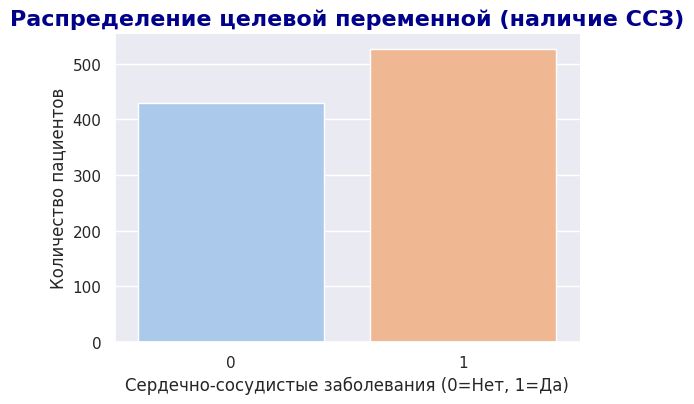

In [ ]:
sns.set_style('darkgrid')
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=heart, x='ССЗ', palette='pastel')
plt.title(
    'Распределение целевой переменной (наличие ССЗ)',
    fontsize=16,
    fontweight='bold',
    color='darkblue'
)
plt.xlabel('Сердечно-сосудистые заболевания (0=Нет, 1=Да)', fontsize=12)
plt.ylabel('Количество пациентов', fontsize=12)
sns.despine()


#plt.figure(figsize=(4,3))
#sns.countplot(data=heart, x='ССЗ')
#plt.title('Распределение целевой переменной')
plt.show()

In [ ]:
# Процентное соотношение
print("Процентное соотношение классов:")
percentages = heart['ССЗ'].value_counts(normalize=True) * 100
formatted_percentages = percentages.map('{:.0f}%'.format)
print(formatted_percentages)
#print(heart['ССЗ'].value_counts(normalize=True) * 100)

Процентное соотношение классов:
ССЗ
1    55%
0    45%
Name: proportion, dtype: object


#### Распределение числовых признаков

In [ ]:
# Получение списка числовых признаков
numeric_columns = heart.select_dtypes(include=['number']).columns.tolist()

# Выводим результат
print(numeric_columns)
print(f"Количество числовых признаков: {len(numeric_columns)}")

['ID', 'Бронхиальная астма', 'ЛПНП', 'Возраст алког', 'Работа', 'ВИЧ/СПИД', 'Пассивное курение', 'Переломы', 'ЛПВП', 'Выход на пенсию', 'Холестерин', 'Артериальная гипертония', 'Триглицериды', 'Гепатит', 'Сахарный диабет', 'Спорт, клубы', 'Религия, клубы', 'Возраст курения', 'Туберкулез легких', 'Онкология', 'Травмы за год', 'Регулярный прием лекарственных средств', 'Глюкоза плазмы натощак', 'Абдоминальное ожирение, см', 'Сон после обеда', 'Хроническое заболевание легких', 'Сигарет в день', 'Индекс массы тела, кг/м^2', 'Прекращение работы по болезни', 'ССЗ']
Количество числовых признаков: 30


* Постройте графики распределений

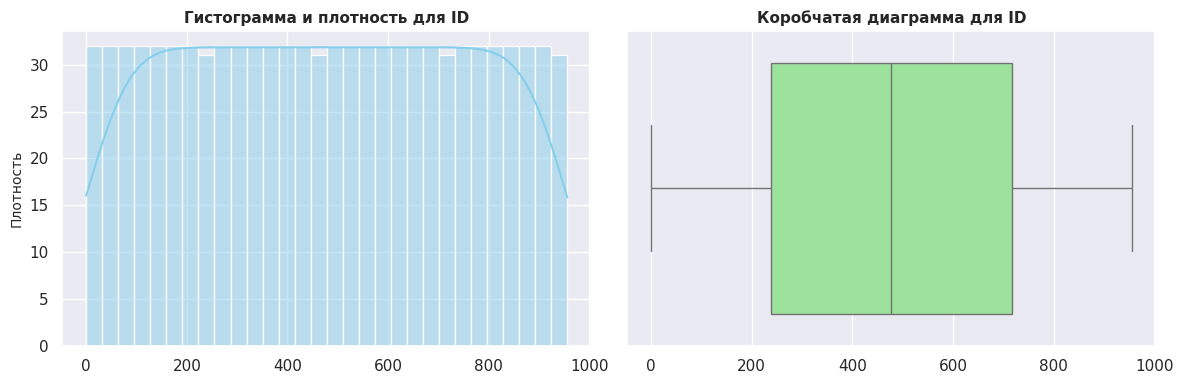

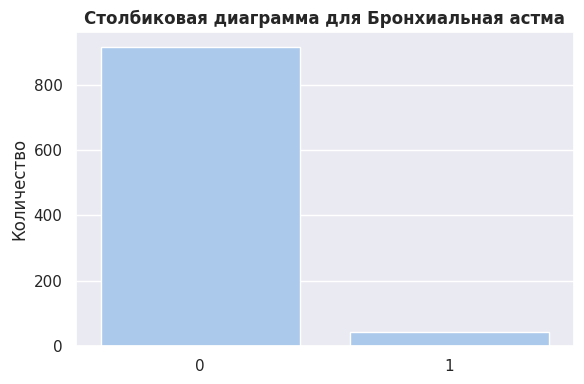

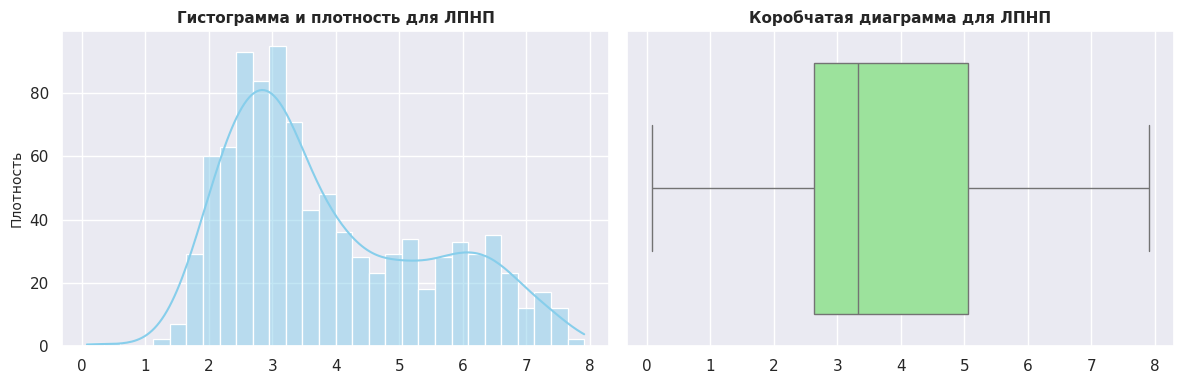

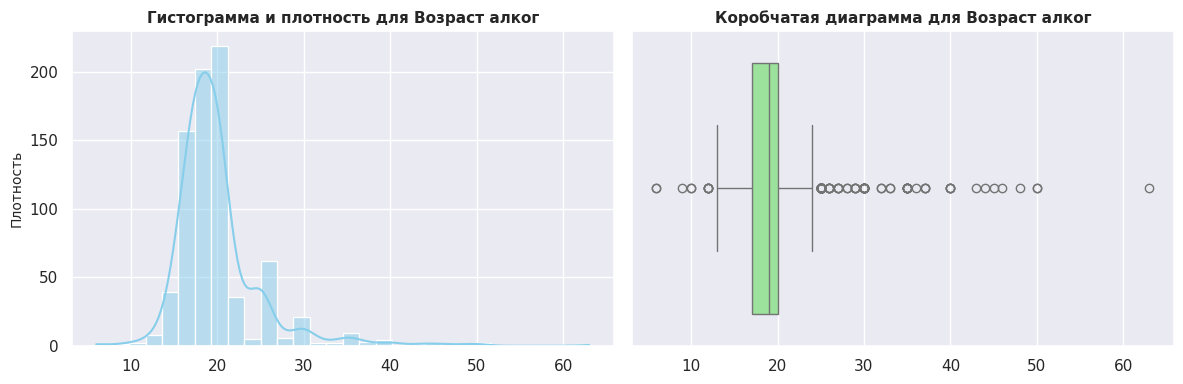

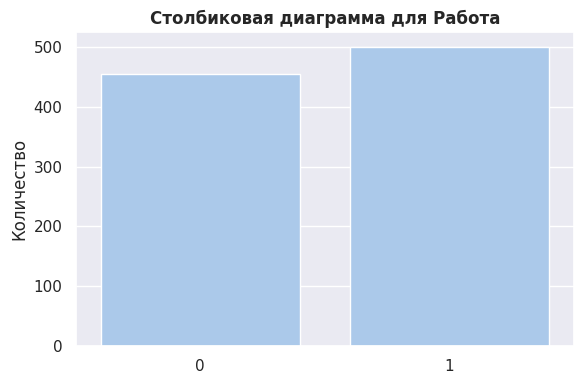

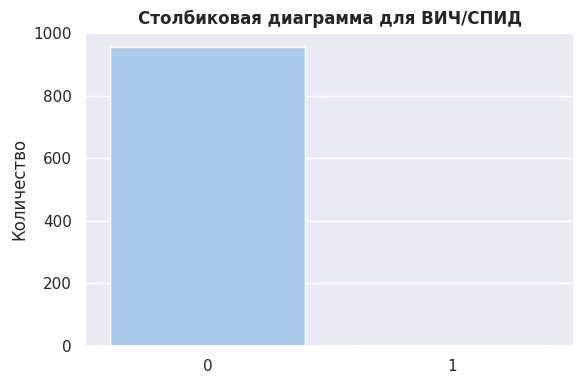

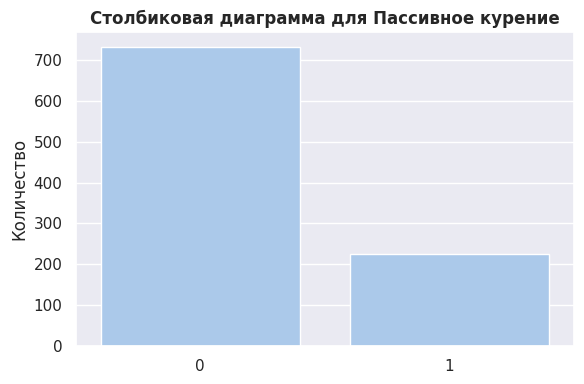

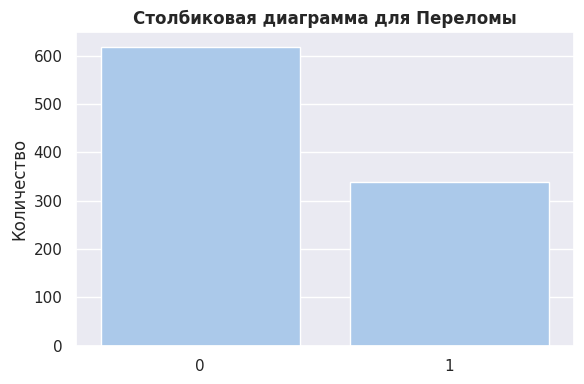

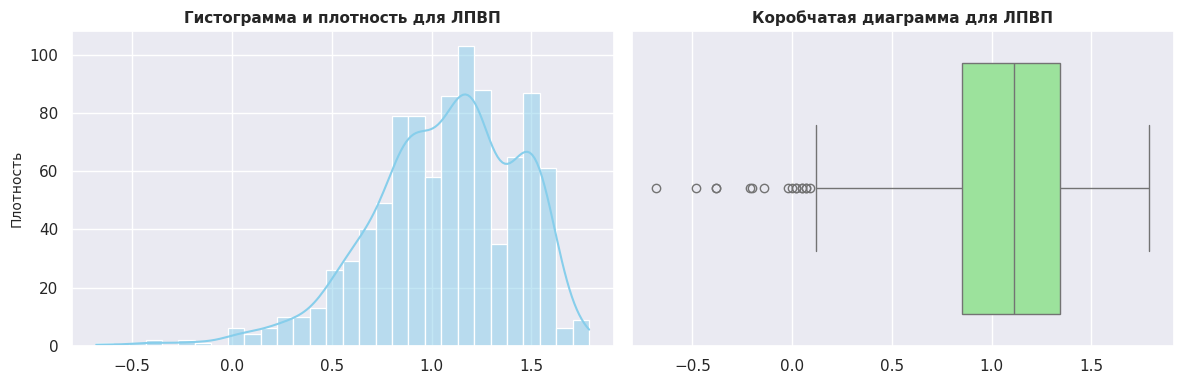

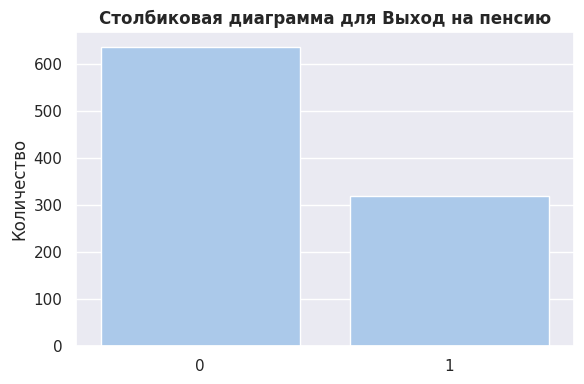

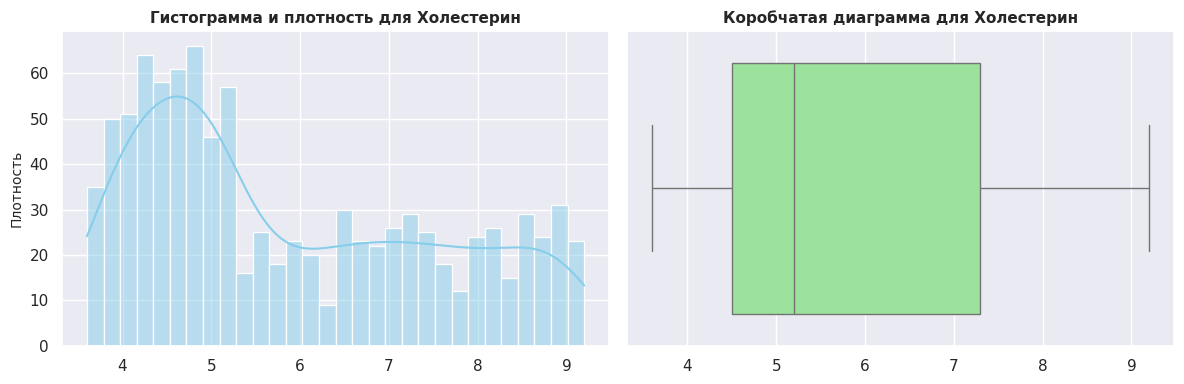

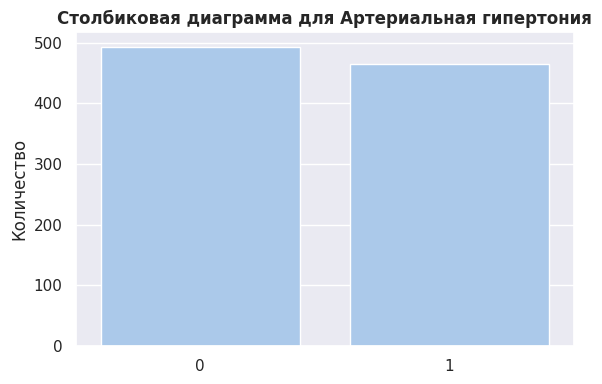

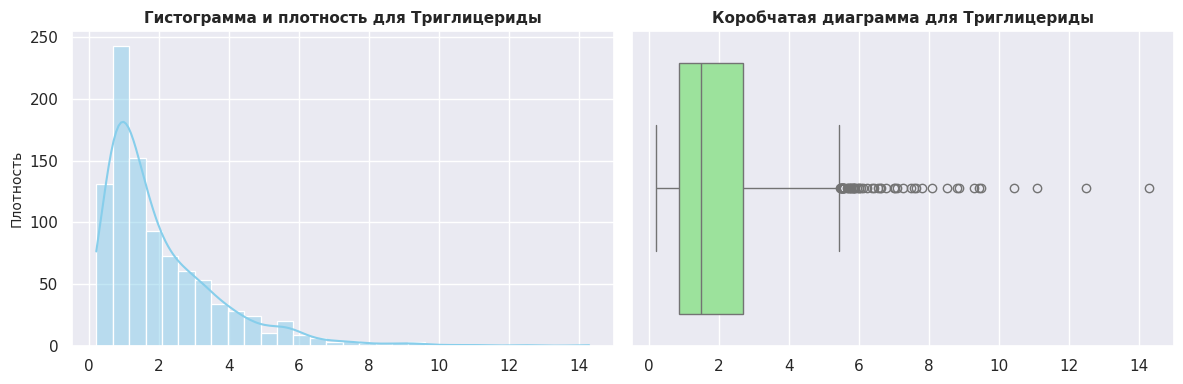

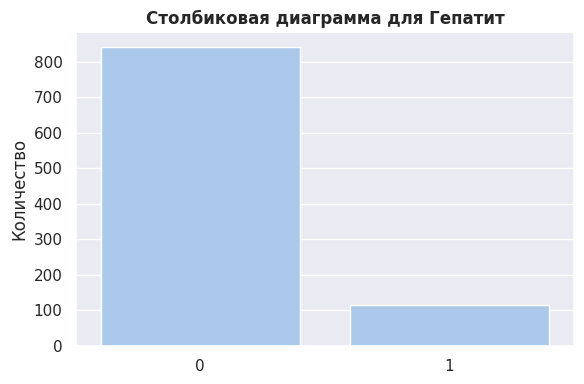

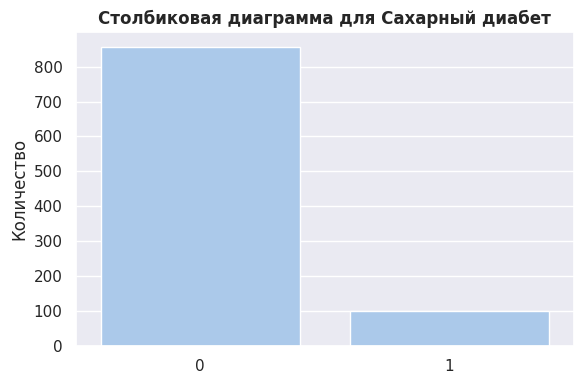

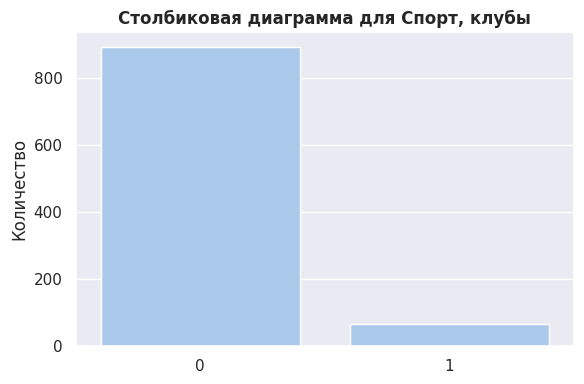

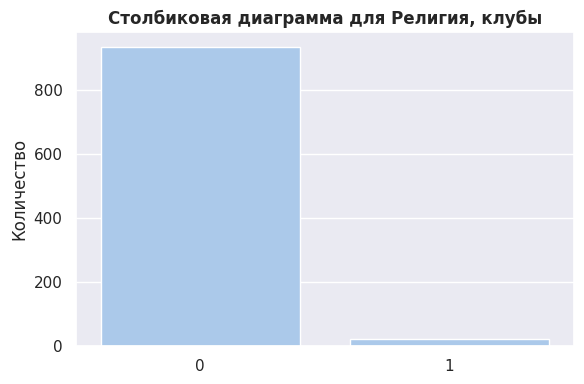

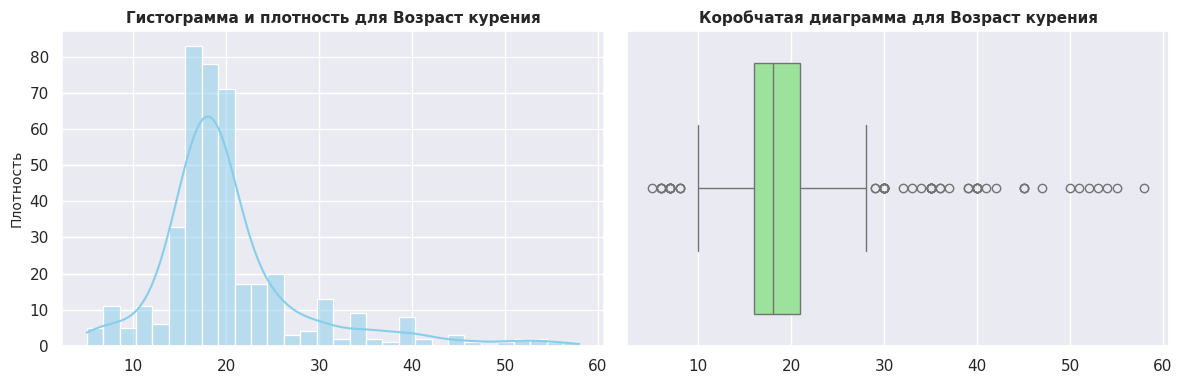

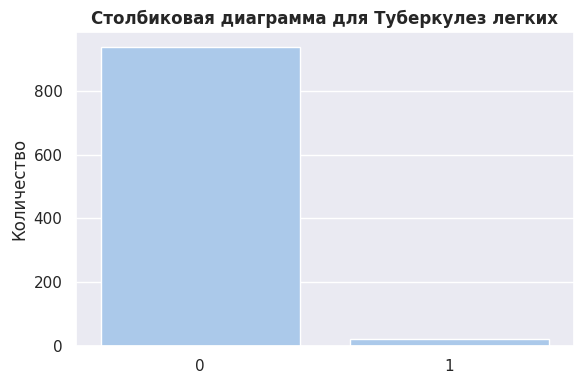

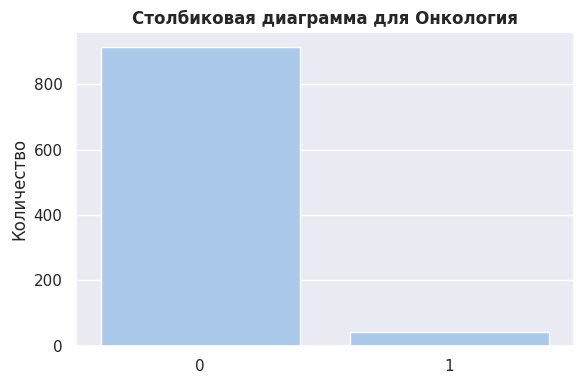

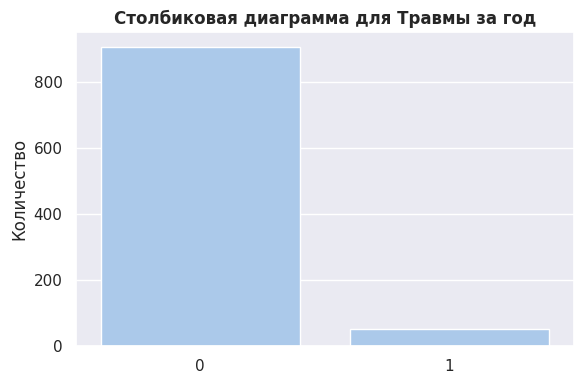

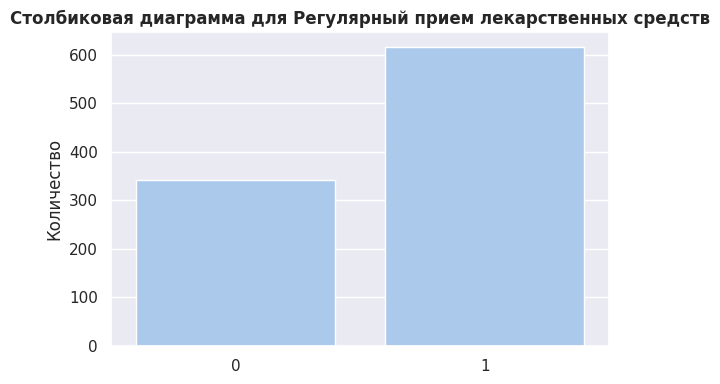

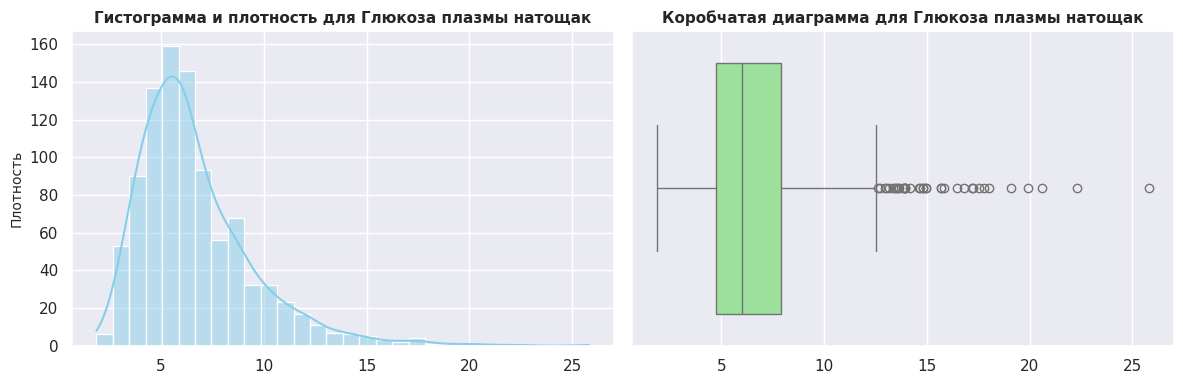

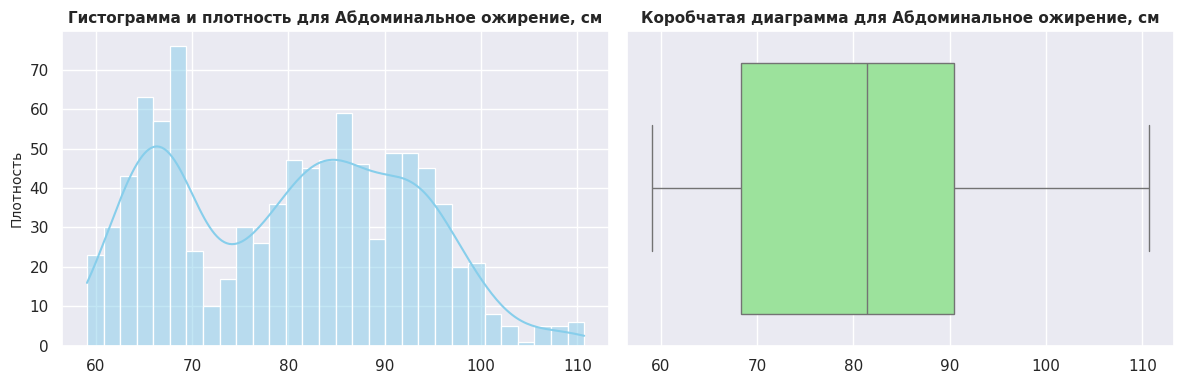

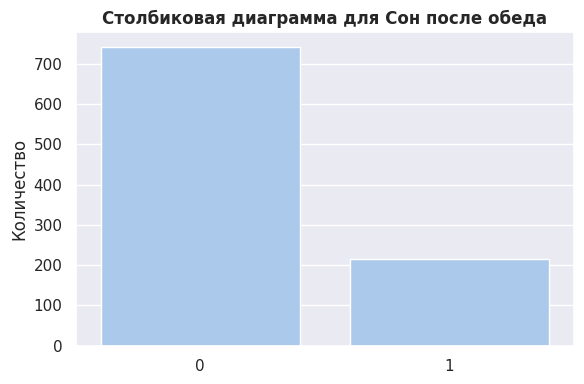

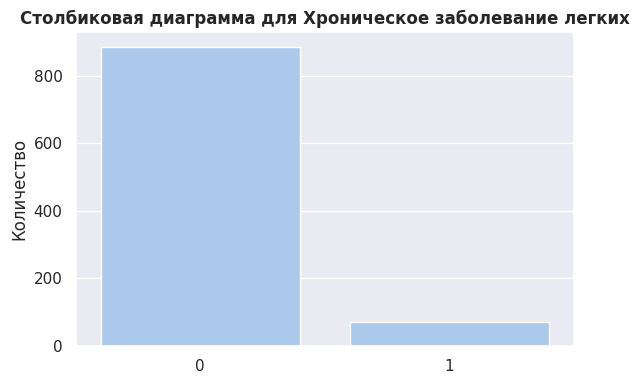

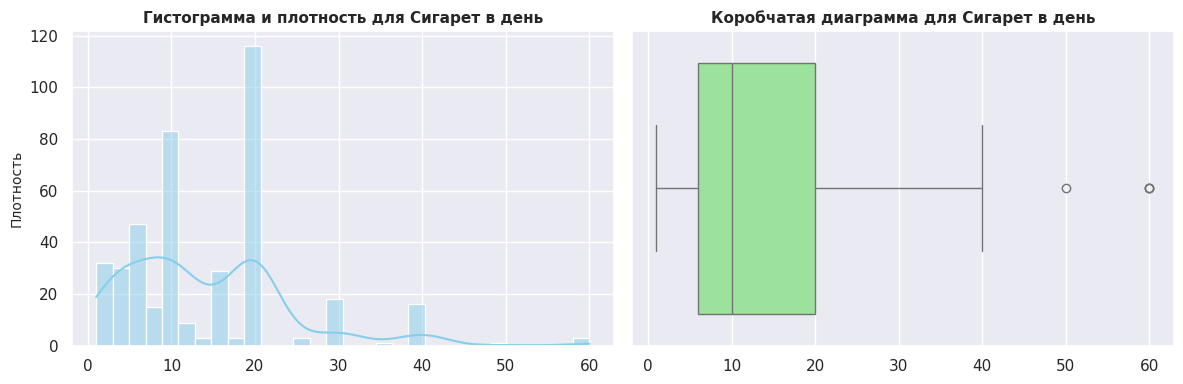

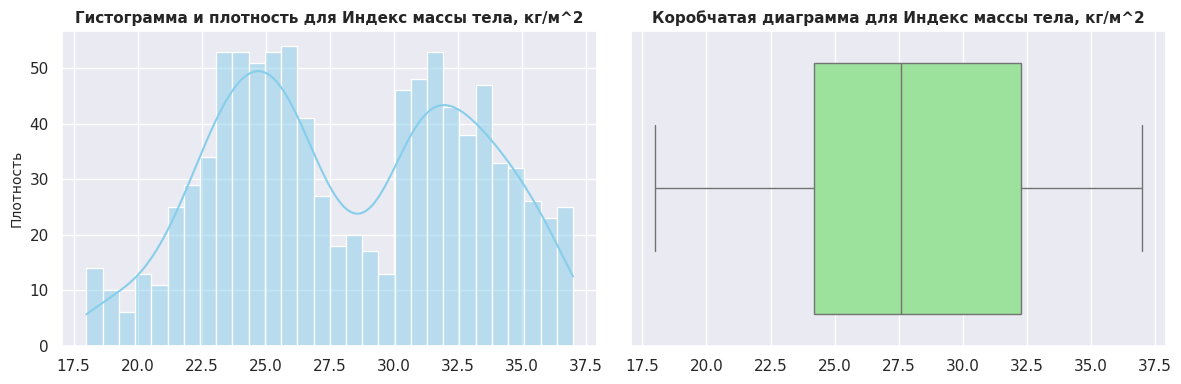

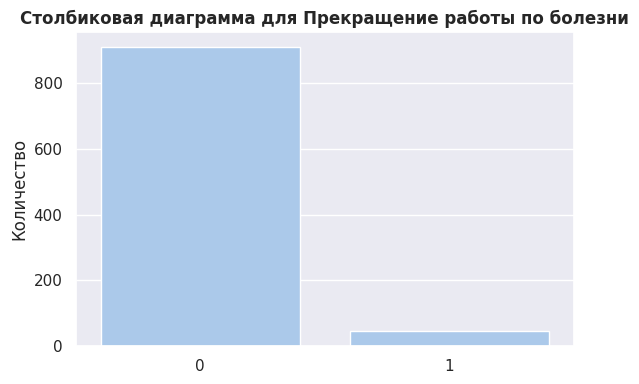

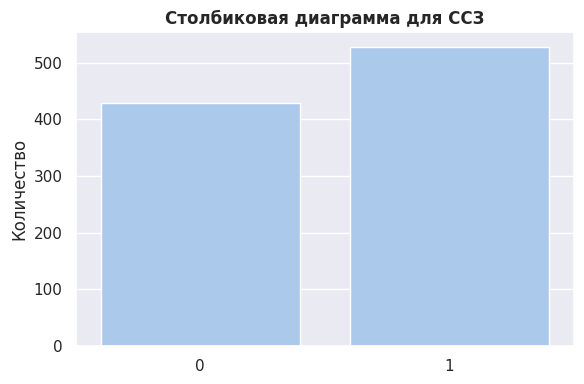

In [ ]:
# Устанавливаем стиль графиков
#sns.set(style="whitegrid")
sns.set(style="darkgrid")
sns.set_palette('pastel')

# Перебираем все столбцы
for column in numeric_columns:
    unique_values = heart[column].nunique()  # Получаем количество уникальных значений

    if unique_values > 2:
        plt.figure(figsize=(12, 4)) # Увеличим ширину для двух графиков
    else:
        plt.figure(figsize=(6, 4))

    if unique_values > 2:  # Если больше 2 уникальных значений, строим гистограмму и коробчатую диаграмму
        plt.subplot(1, 2, 1)
        sns.histplot(heart[column], bins=30, kde=True, color='skyblue')
        plt.title(f'Гистограмма и плотность для {column}', fontsize=11, fontweight='bold')
        #plt.xlabel(column, fontsize=10)
        plt.xlabel('')
        plt.ylabel('Плотность', fontsize=10)

        plt.subplot(1, 2, 2)
        sns.boxplot(x=heart[column], color='lightgreen')
        plt.title(f'Коробчатая диаграмма для {column}', fontsize=11, fontweight='bold')
        #plt.xlabel(column, fontsize=10)
        plt.xlabel('')


    elif unique_values == 2:  # Если ровно 2 уникальных значения, строим столбиковую диаграмму
        plt.subplot(1, 1, 1)
        sns.countplot(x=heart[column])
        plt.title(f'Столбиковая диаграмма для {column}', fontsize=12, fontweight='bold')
        #plt.xlabel(column, fontsize=10)
        plt.xlabel('')
        plt.ylabel('Количество', fontsize=12)


    plt.tight_layout() #функция, которая автоматически корректирует расстояние между элементами графика
    plt.show()

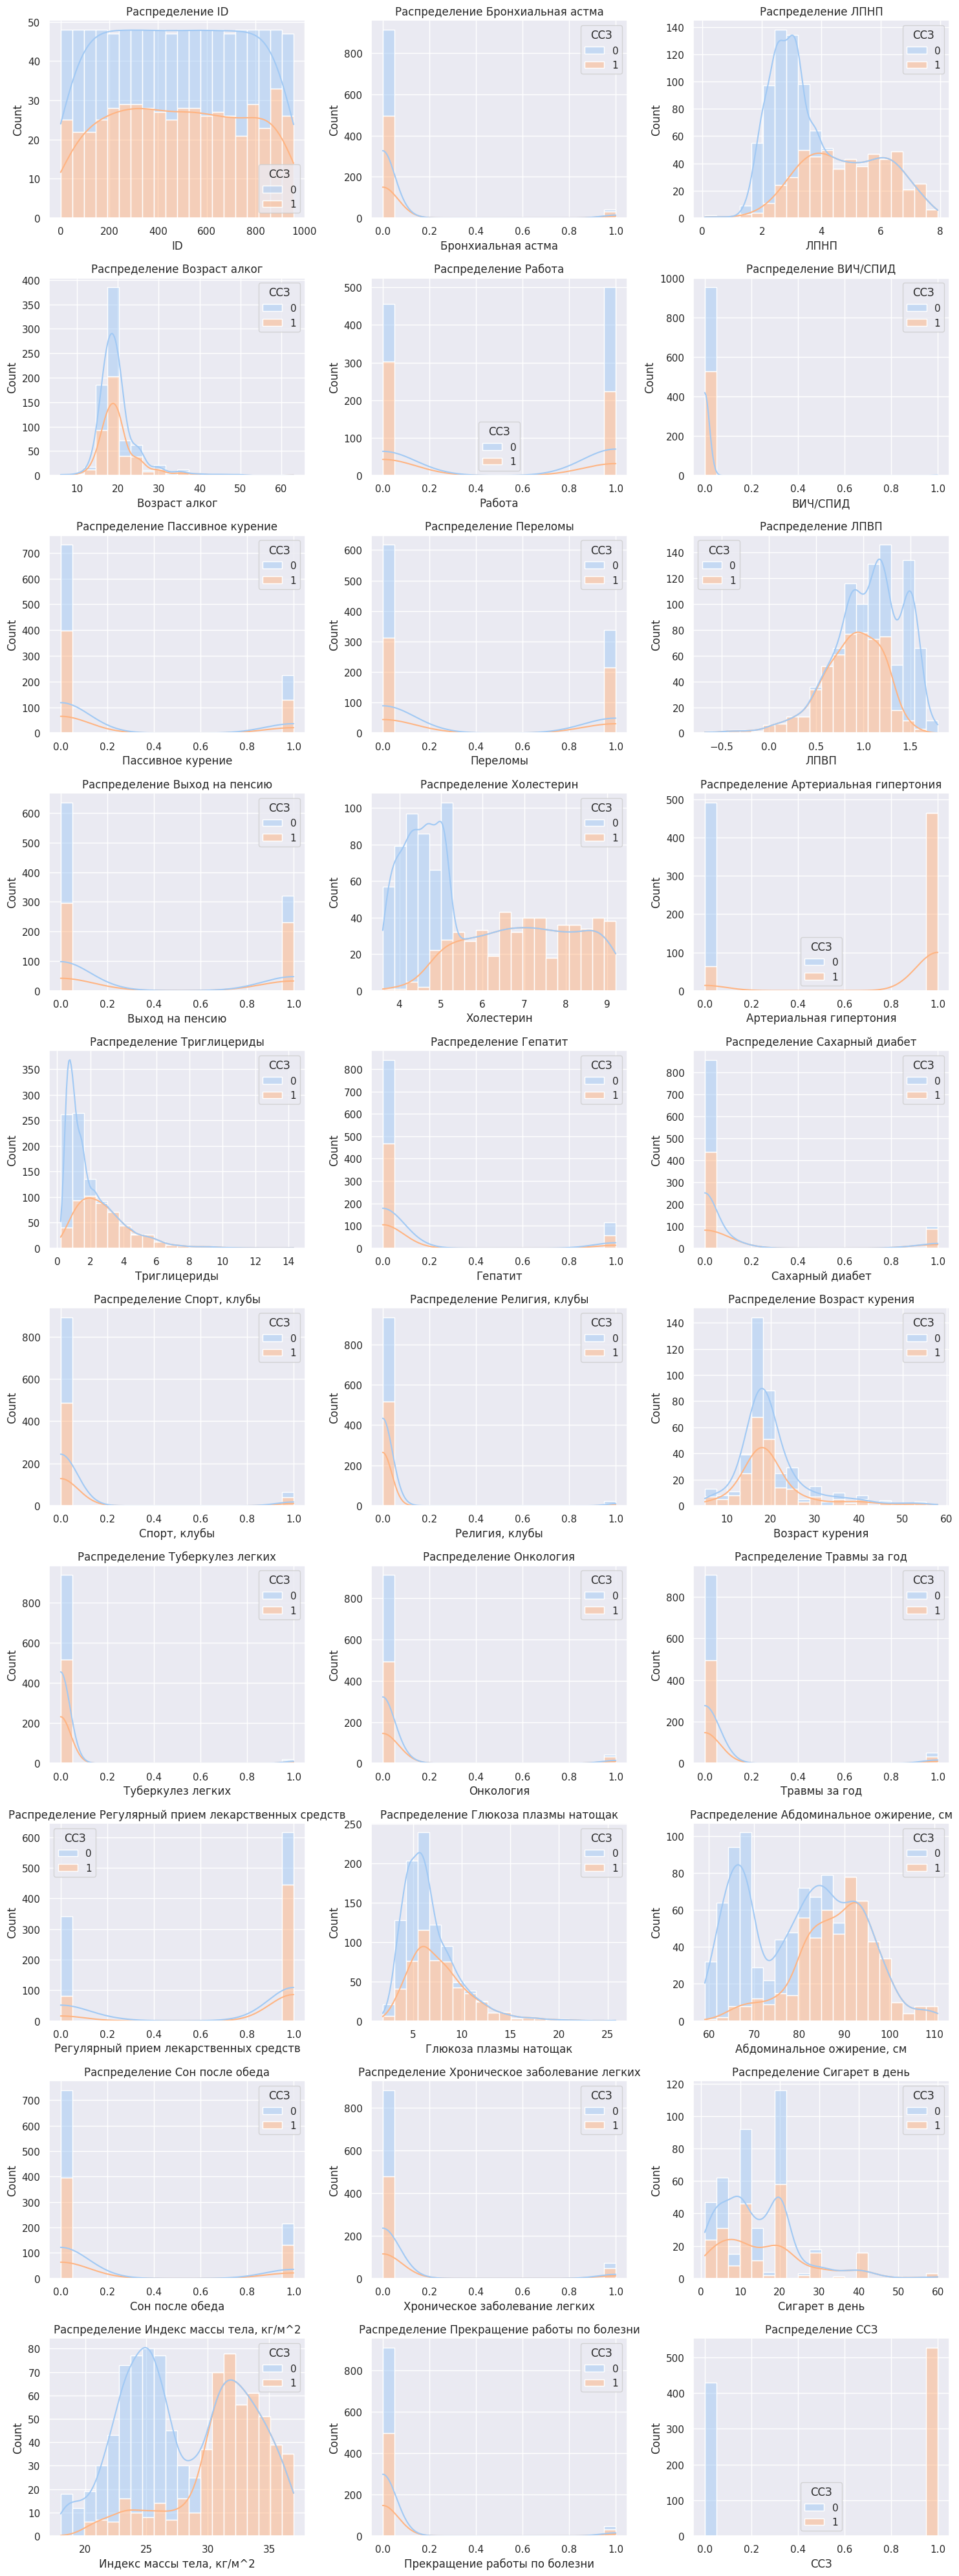

In [ ]:
# Гистограммы числовых признаков
heart[numeric_columns] = heart[numeric_columns].apply(pd.to_numeric, errors='coerce')

plt.figure(figsize=(15, 40))
for i, col in enumerate(numeric_columns):
    plt.subplot(10, 3, i+1)
    sns.histplot(data=heart, x=col, hue='ССЗ', kde=True, bins=20, multiple='stack')
    plt.title(f'Распределение {col}')
plt.tight_layout()
plt.show()

#### Парные диаграмы рассеяния

* Построим для начала в Matplotlib. Убедимся, что код сложный, большой.

In [ ]:
'''
# Берём список числовых столбцов из DataFrame heart
numeric_columns = heart.select_dtypes(include=[np.number]).columns.tolist()

cols = numeric_columns  # список названий числовых столбцов
n = len(cols)  # число числовых признаков
if n == 0:
    # Если числовых столбцов нет — сообщаем об ошибке
    raise ValueError("Нет числовых столбцов для построения.")

# Размер фигуры — масштабируем в зависимости от числа признаков
figsize = (2.5 * n, 2.5 * n)
# Создаём матрицу осей n x n
fig, axes = plt.subplots(nrows=n, ncols=n, figsize=figsize, squeeze=False)
# Отступы между подграфиками
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# Проходим по всем парам признаков (i, j)
for i, ci in enumerate(cols):
    for j, cj in enumerate(cols):
        ax = axes[i][j]  # текущая ось (subplot)
        if i == j:
            # Если это диагональный элемент — строим гистограмму данного признака
            data = heart[ci].dropna()  # убираем пропуски перед построением
            if data.shape[0] > 0:
                # Гистограмма с 30 бинами, светло-серым заливом и чёрной границей
                ax.hist(data, bins=30, color='lightgray', edgecolor='black')
            # Не показываем подписи осей для компактности (подпись — в заголовке)
            ax.set_xlabel('')
            ax.set_ylabel('')
            # Заголовок подграфика — имя признака
            ax.set_title(ci, fontsize=9)
        else:
            # Вне диагонали — scatter plot (cj по оси x, ci по оси y)
            x = heart[cj]
            y = heart[ci]
            # Маска для точек, где оба значения не пропущены
            mask = x.notna() & y.notna()
            # Рисуем точки с небольшим размером и прозрачностью для визуальной читабельности
            ax.scatter(x[mask], y[mask], s=8, alpha=0.6, color='tab:blue')
            # Для компактности убираем подписи внутренних осей, показываем только крайние
            ax.set_xlabel('')
            ax.set_ylabel('')
        # Настройка визуальной степени тиков: показываем небольшие шрифты
        ax.tick_params(axis='both', which='major', labelsize=7)

# Добавляем общий заголовок для всей фигуры
fig.suptitle('Парные диаграммы (Matplotlib)', fontsize=14)

plt.show() # Показываем итоговый рисунок
'''

'\n# Берём список числовых столбцов из DataFrame heart\nnumeric_columns = heart.select_dtypes(include=[np.number]).columns.tolist()\n\ncols = numeric_columns  # список названий числовых столбцов\nn = len(cols)  # число числовых признаков\nif n == 0:\n    # Если числовых столбцов нет — сообщаем об ошибке\n    raise ValueError("Нет числовых столбцов для построения.")\n\n# Размер фигуры — масштабируем в зависимости от числа признаков\nfigsize = (2.5 * n, 2.5 * n)\n# Создаём матрицу осей n x n\nfig, axes = plt.subplots(nrows=n, ncols=n, figsize=figsize, squeeze=False)\n# Отступы между подграфиками\nplt.subplots_adjust(wspace=0.3, hspace=0.3)\n\n# Проходим по всем парам признаков (i, j)\nfor i, ci in enumerate(cols):\n    for j, cj in enumerate(cols):\n        ax = axes[i][j]  # текущая ось (subplot)\n        if i == j:\n            # Если это диагональный элемент — строим гистограмму данного признака\n            data = heart[ci].dropna()  # убираем пропуски перед построением\n            

* Построим в Seaborn: проще и понятнее

In [ ]:
'''
numeric_columns = heart.select_dtypes(include=[np.number]).columns.tolist()
cols = numeric_columns
if len(cols) == 0:
    raise ValueError("Нет числовых столбцов для построения.")

# Простой pairplot (диагональ — гистограммы, вне диагонали — scatter)
sns.set(style="ticks")
g = sns.pairplot(heart[cols], diag_kind='hist', plot_kws={'s': 20, 'alpha': 0.6})
g.fig.suptitle('Парные диаграммы (Seaborn)', y=1.02)
plt.show()
'''

'\nnumeric_columns = heart.select_dtypes(include=[np.number]).columns.tolist()\ncols = numeric_columns\nif len(cols) == 0:\n    raise ValueError("Нет числовых столбцов для построения.")\n\n# Простой pairplot (диагональ — гистограммы, вне диагонали — scatter)\nsns.set(style="ticks")\ng = sns.pairplot(heart[cols], diag_kind=\'hist\', plot_kws={\'s\': 20, \'alpha\': 0.6})\ng.fig.suptitle(\'Парные диаграммы (Seaborn)\', y=1.02)\nplt.show()\n'

* Нет смысла строить диаграммы для переменных, у которых всего 2 уникальных значения. Исключим их

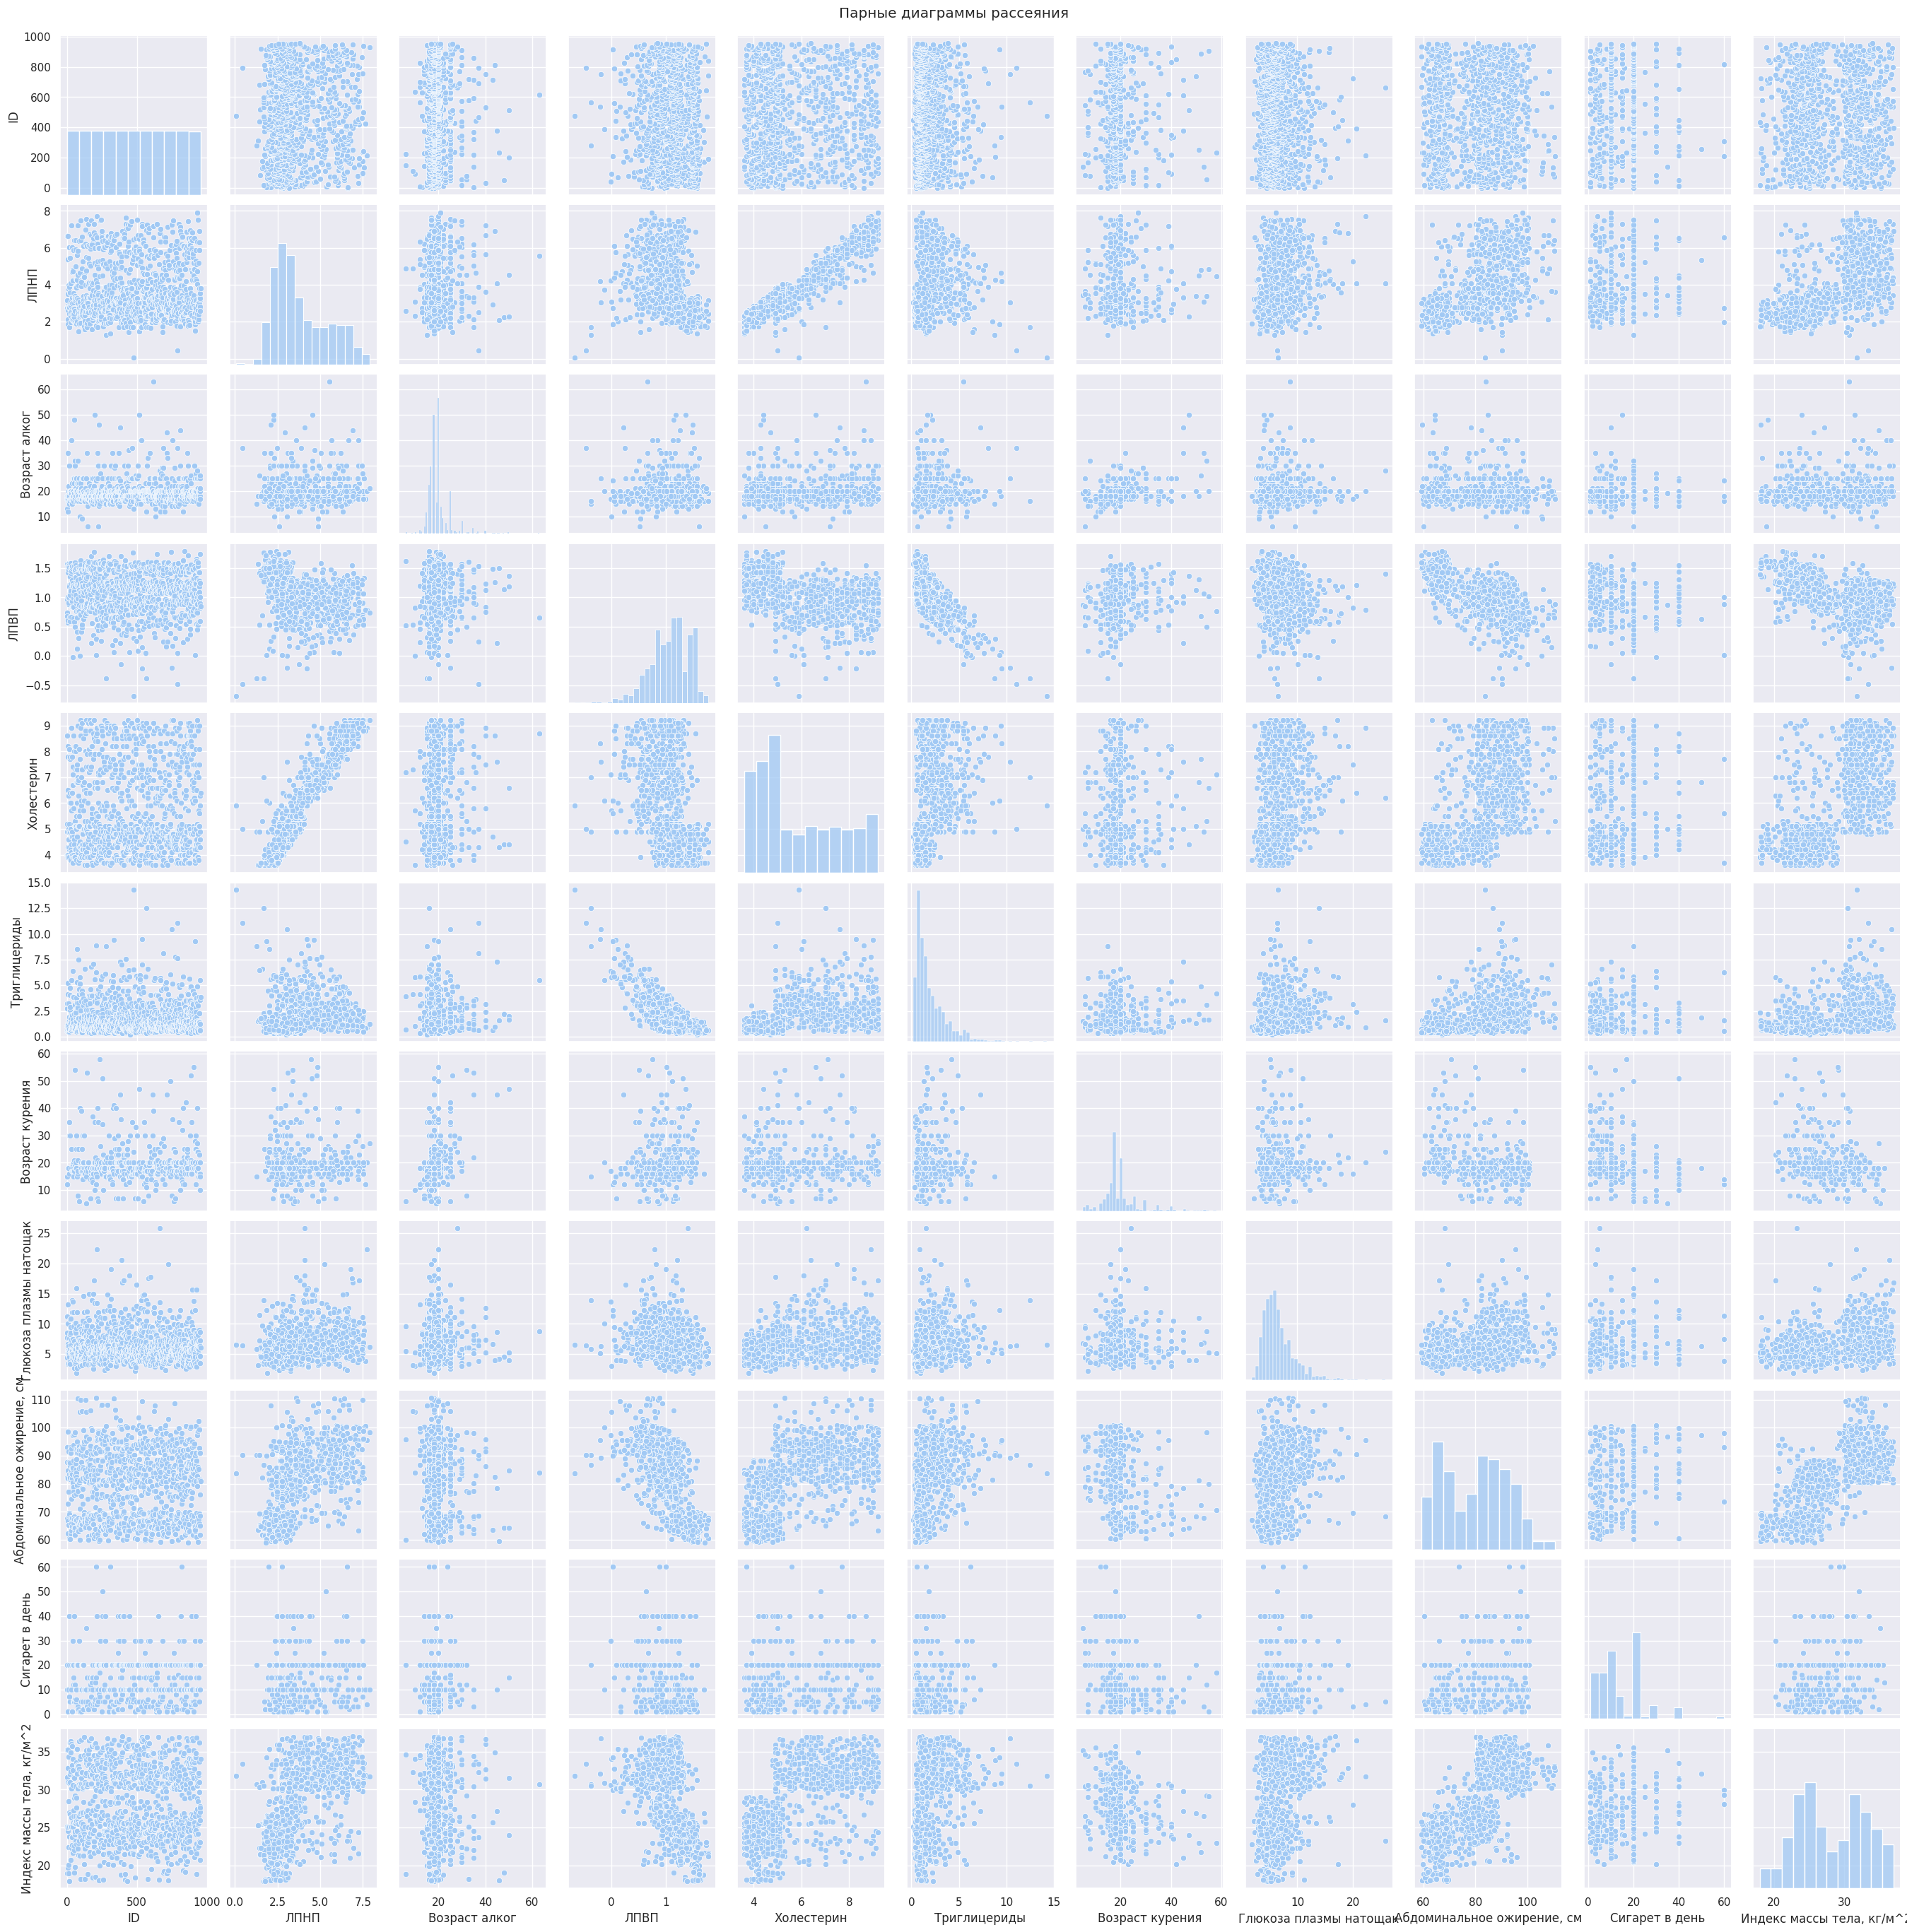

In [ ]:
# Фильтруем переменные с количеством уникальных значений больше 2
filtered_columns = [col for col in numeric_columns if heart[col].nunique() > 2]

# Если есть подходящие столбцы, строим парные диаграммы
if filtered_columns:
    pairplot = sns.pairplot(heart[filtered_columns])
    plt.suptitle('Парные диаграммы рассеяния', y=1)  # Заголовок
    plt.show()
else:
    print("Нет подходящих числовых переменных с уникальным количеством значений больше 2.")

Параметр y отвечает за расположение главного заголовка сверху. При y = 1 заголовок находит прямо сверху всех графиков, при y > 1 он улетает вверх, чем больше y. При y < 1 заголовок съезжает вниз на графики. Оптимальное значение y = 1. При малейшем увеличении этого параметра, заголовок сразу улетает вверх.

## ОЧИСТКА ДАННЫХ

### НЕИНФОРМАТИВНЫЕ ПРИЗНАКИ

In [ ]:
#список неинформативных признаков
low_information = []

#цикл по всем столбцам
for col in heart.columns:
    #наибольшая относительная частота в признаке
    top_freq = heart[col].value_counts(normalize=True).max()
    #доля уникальных значений от размера признака
    nunique_ratio = heart[col].nunique() / heart[col].count()
    # сравниваем наибольшую частоту с порогом
    if top_freq > 0.95:
        low_information.append(col)
        print(f'{col}: {round(top_freq*100, 2)}% одинаковых значений')
    # сравниваем долю уникальных значений с порогом
    if nunique_ratio > 0.95:
        low_information.append(col)
        print(f'{col}: {round(nunique_ratio*100, 2)}% уникальных значений')

ID: 100.0% уникальных значений
Бронхиальная астма: 95.71% одинаковых значений
ВИЧ/СПИД: 99.79% одинаковых значений
Религия, клубы: 97.7% одинаковых значений
Туберкулез легких: 97.91% одинаковых значений
Онкология: 95.5% одинаковых значений
Этнос: 97.49% одинаковых значений
Прекращение работы по болезни: 95.19% одинаковых значений


* Отбросим неинформативный признак **ID**

In [ ]:
heart = heart.drop("ID", axis=1) # можно также использовать heart.drop("ID", axis=1, inplace=True)
heart.head(3)

,Бронхиальная астма,ЛПНП,Возраст алког,Работа,ВИЧ/СПИД,Статус Курения,Пассивное курение,Переломы,Время пробуждения,ЛПВП,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Прекращение работы по болезни,Религия,Профессия,ССЗ
0,0,2.79,18.0,1,0,Курит,0,0,06:00:00,0.97,...,0,22:00:00,0,20.0,3 - средняя школа / закон.среднее / выше среднего,25.1,0,Христианство,низкоквалифицированные работники,0
1,0,6.62,NaN,0,0,Никогда не курил(а),0,1,04:00:00,0.74,...,1,00:00:00,0,NaN,5 - ВУЗ,35.2,0,Христианство,дипломированные специалисты,1
2,0,3.17,17.0,0,0,Никогда не курил(а),1,0,07:00:00,1.57,...,0,23:00:00,0,NaN,5 - ВУЗ,19.0,0,Христианство,дипломированные специалисты,0


* Удалим из датасета и другие неинформативные признаки.

In [ ]:
columns_to_remove = ["Этнос", "Туберкулез легких", "Бронхиальная астма", "ВИЧ/СПИД", "Религия, клубы", "Онкология","Прекращение работы по болезни"]
heart = heart.drop(columns=columns_to_remove)
heart.head()

,ЛПНП,Возраст алког,Работа,Статус Курения,Пассивное курение,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,...,"Абдоминальное ожирение, см",Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ
0,2.79,18.0,1,Курит,0,0,06:00:00,0.97,0,4.0,...,82.3,0,22:00:00,0,20.0,3 - средняя школа / закон.среднее / выше среднего,25.1,Христианство,низкоквалифицированные работники,0
1,6.62,NaN,0,Никогда не курил(а),0,1,04:00:00,0.74,0,8.6,...,87.6,1,00:00:00,0,NaN,5 - ВУЗ,35.2,Христианство,дипломированные специалисты,1
2,3.17,17.0,0,Никогда не курил(а),1,0,07:00:00,1.57,0,5.2,...,67.5,0,23:00:00,0,NaN,5 - ВУЗ,19.0,Христианство,дипломированные специалисты,0
3,2.74,13.0,1,Бросил(а),1,0,07:00:00,0.68,0,4.9,...,93.1,0,23:00:00,0,10.0,3 - средняя школа / закон.среднее / выше среднего,31.6,Атеист / агностик,низкоквалифицированные работники,1
4,6.62,16.0,0,Никогда не курил(а),1,1,06:00:00,1.01,0,8.2,...,84.6,0,23:00:00,0,NaN,3 - средняя школа / закон.среднее / выше среднего,32.8,Христианство,операторы и монтажники установок и машинного о...,1


In [ ]:
heart.shape

(956, 34)

In [ ]:
heart.columns

Index(['ЛПНП', 'Возраст алког', 'Работа', 'Статус Курения',
       'Пассивное курение', 'Переломы', 'Время пробуждения', 'ЛПВП',
       'Выход на пенсию', 'Холестерин', 'Артериальная гипертония',
       'Триглицериды', 'Гепатит', 'Сахарный диабет', 'Пол', 'Спорт, клубы',
       'Семья', 'Частота пасс кур', 'Возраст курения', 'Травмы за год',
       'Регулярный прием лекарственных средств', 'Национальность', 'Алкоголь',
       'Глюкоза плазмы натощак', 'Абдоминальное ожирение, см',
       'Сон после обеда', 'Время засыпания', 'Хроническое заболевание легких',
       'Сигарет в день', 'Образование', 'Индекс массы тела, кг/м^2', 'Религия',
       'Профессия', 'ССЗ'],
      dtype='object')

### ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ

In [ ]:
display(heart.isnull().tail())

,ЛПНП,Возраст алког,Работа,Статус Курения,Пассивное курение,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,...,"Абдоминальное ожирение, см",Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ
951,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
952,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
953,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
954,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
955,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False


**Список столбцов с пропусками**

Первый способ — это вывести на экран названия столбцов, где число пропусков больше 0. Найдём долю пропусков в каждом столбце

In [ ]:
cols_null_percent = heart.isnull().mean() * 100
cols_with_null = cols_null_percent[cols_null_percent>0].sort_values(ascending=False)
display(cols_with_null)

,0
Частота пасс кур,76.569038
Сигарет в день,57.217573
Возраст курения,56.903766
Возраст алког,17.573222
Пол,0.209205


* Наибольшее число пропусков в признаке **Частота пасс кур** - 77%

* **Сигарет в день** и **Возраст курения** содержат по 57% пропусков

* **Возраст алког** - 17%

* Самое малое количество пропусков в признаке **Пол** - меньше 1%.





#### Столбчатая диаграмма пропусков

Визуально оценим соотношение числа пропусков к числу записей.

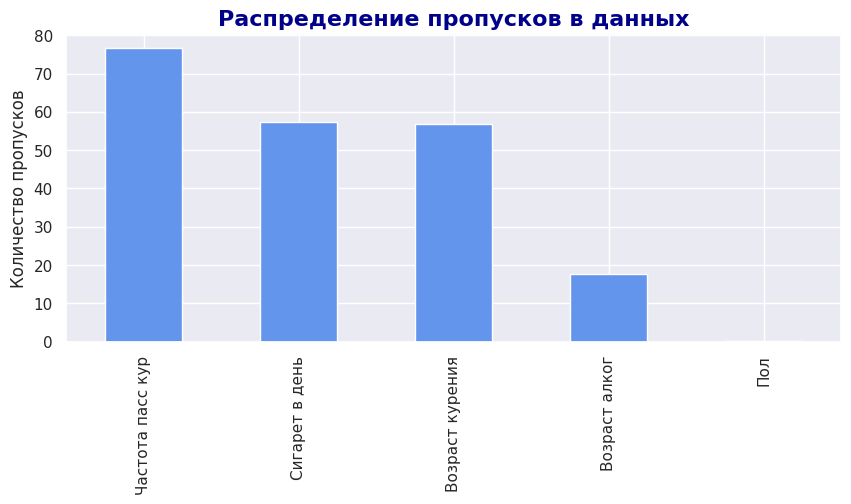

In [ ]:
cols_with_null.plot(
    kind='bar',
    figsize=(10, 4),
    color='cornflowerblue'
)
plt.title(
    'Распределение пропусков в данных',
    fontsize=16,
    fontweight='bold',
    color='darkblue'
)

plt.ylabel('Количество пропусков', fontsize=12)
plt.show();

#### Тепловая карта пропусков

Для создания тепловой карты: метод **isnull()**.
Ячейки таблицы, в которых есть пропуск, будем отмечать жёлтым цветом, а остальные — синим. Для этого создадим собственную палитру цветов тепловой карты с помощью метода color_palete() из библиотеки seaborn.

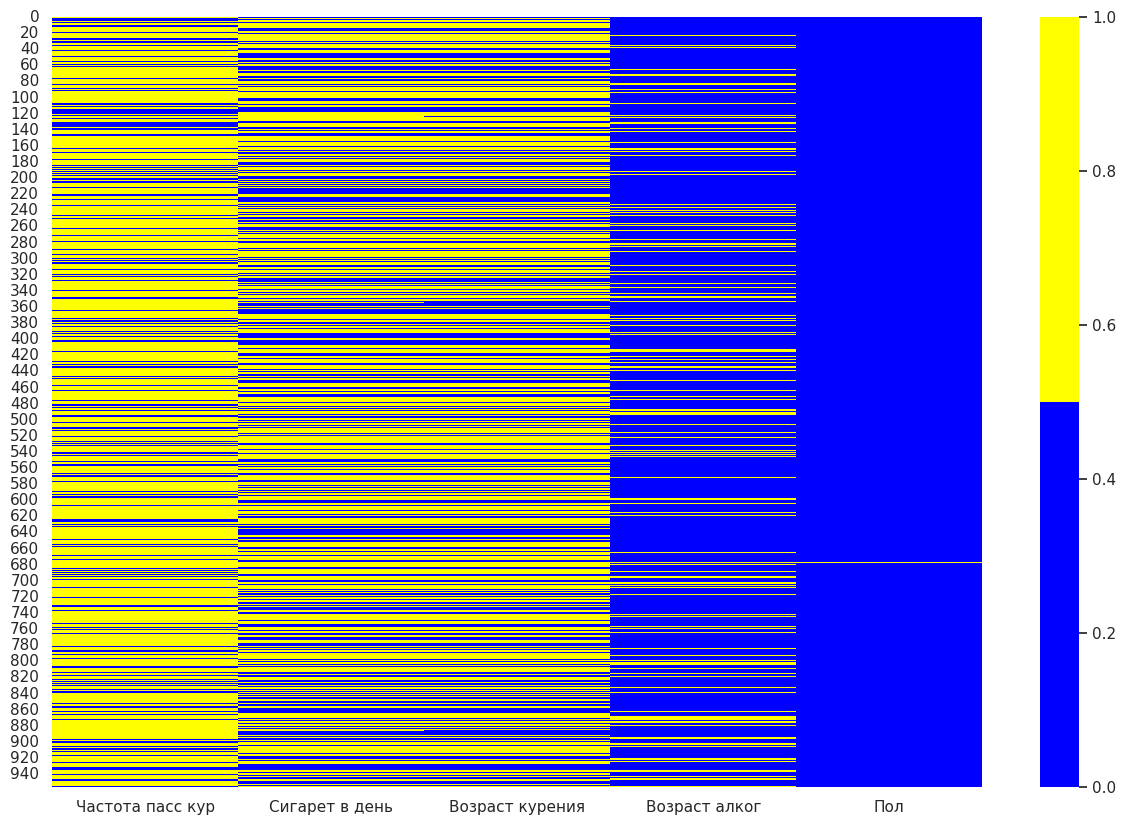

In [ ]:
colors = ['blue', 'yellow']
fig = plt.figure(figsize=(15, 10))
cols = cols_with_null.index
ax = sns.heatmap(
    heart[cols].isnull(),
    cmap=sns.color_palette(colors),
)

#### **Работа с пропусками**

##### **1. Отбрасывание записей и признаков**

**Правило:** удаляется столбец, если число пропусков в нем более 30%. В остальных случаях удаляются записи.

Предварительно создадим копию исходной таблицы — drop_heart, чтобы не повредить её. Зададимся порогом в 70%: будем оставлять только те столбцы, в которых 70 и более процентов записей не являются пустыми. После этого удалим записи, в которых содержится хотя бы один пропуск.

In [ ]:
#создаем копию исходной таблицы
drop_heart = heart.copy()
#задаем минимальный порог: вычисляем 70% от числа строк
thresh = drop_heart.shape[0]*0.7
#удаляем столбцы, в которых более 30% (100-70) пропусков
drop_heart = drop_heart.dropna(thresh=thresh, axis=1)#удаляем записи, в которых есть хотя бы 1 пропуск
drop_heart = drop_heart.dropna(how='any', axis=0)
#отображаем результирующую долю пропусков
drop_heart.isnull().mean()

,0
ЛПНП,0.0
Возраст алког,0.0
Работа,0.0
Статус Курения,0.0
Пассивное курение,0.0
Переломы,0.0
Время пробуждения,0.0
ЛПВП,0.0
Выход на пенсию,0.0
Холестерин,0.0


In [ ]:
print(drop_heart.shape)

(787, 31)


##### **2. Заполнение недостающих значений константами**

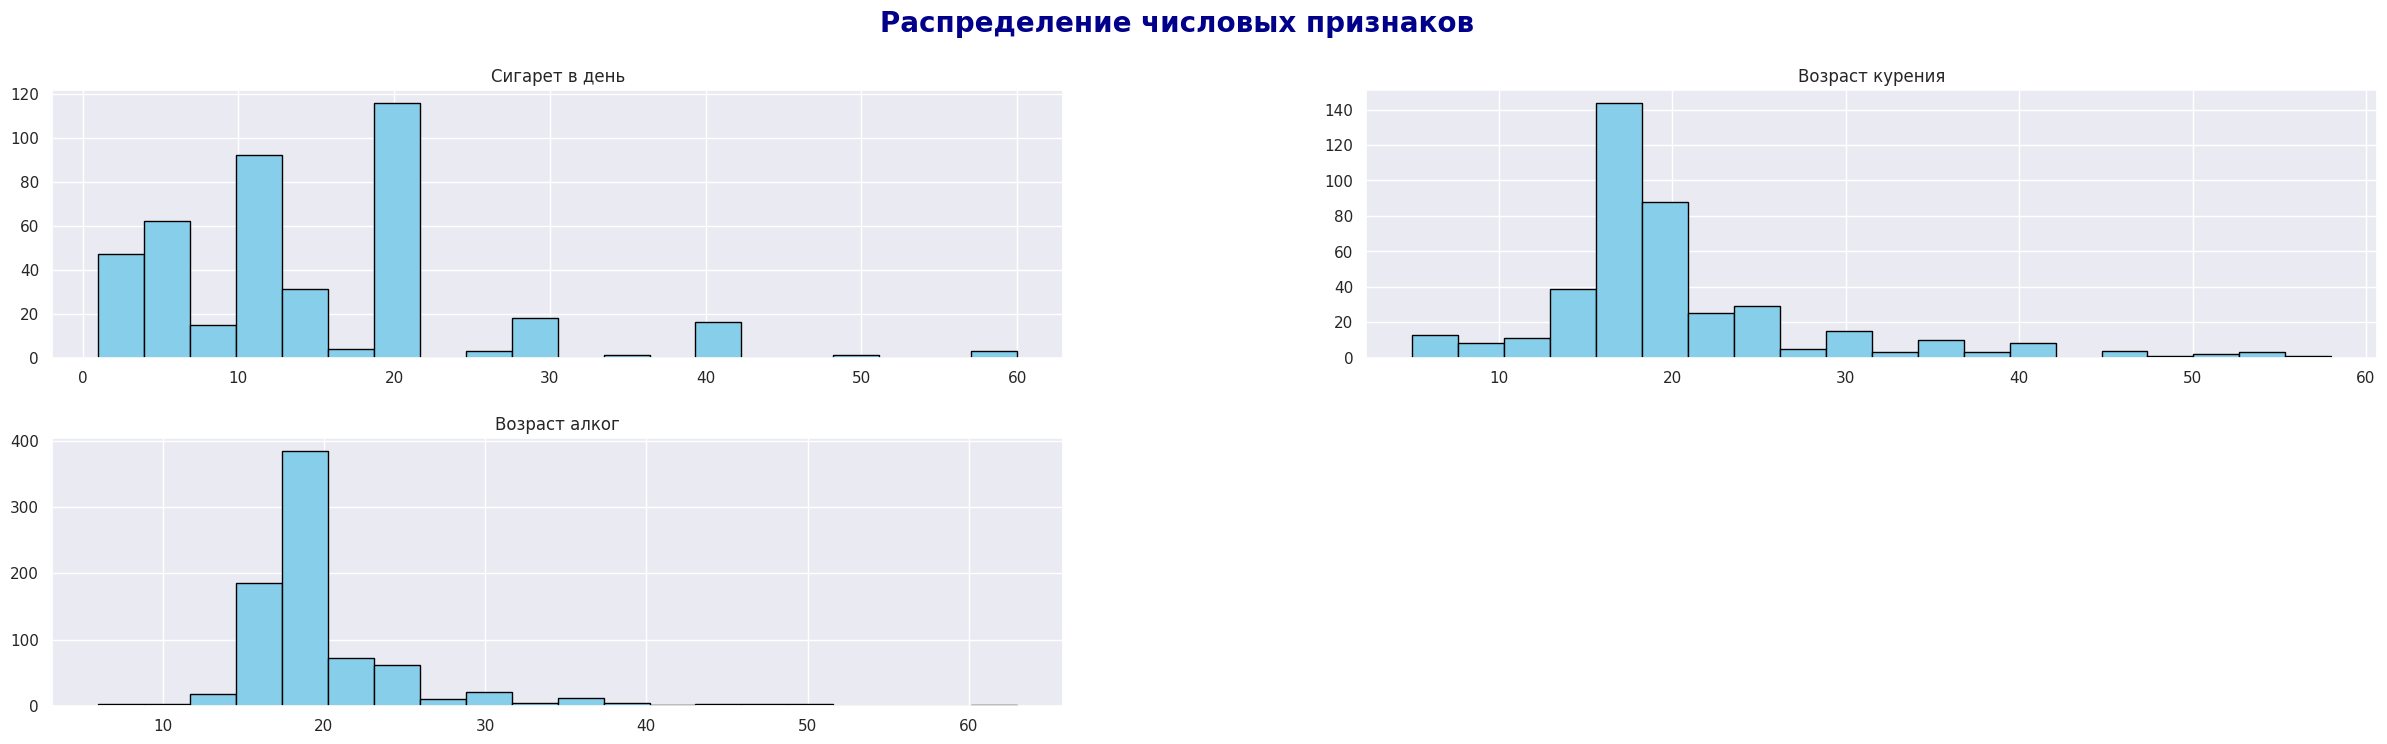

In [ ]:
cols = cols_with_null.index
heart[cols].hist(figsize=(30, 8),
                 color='skyblue',
                 edgecolor='black', bins=20)

plt.suptitle('Распределение числовых признаков', fontsize=20, fontweight='bold', color='darkblue')

plt.show()


У пациентов с нулевым значением в переменной **Пассивное курение** должны быть пропущены значения в столбцах **Частота пасс кур**. Проверим это.

In [ ]:
# Проверяем условие, что если 'Пассивное курение' равно 0, то 'Частота пасс кур' должна быть NaN
condition = (heart['Пассивное курение'] == 0) & (heart['Частота пасс кур'].notna())

# Подсчитываем количество строк, где условие не выполняется
count_invalid_rows = condition.sum()

# Если условие выполняется для хотя бы одной строки, выводим соответствующее сообщение и индексы строк
if count_invalid_rows > 0:
    print('Есть строки, где "Пассивное курение" равно 0, но "Частота пасс кур" не является NaN.')
    print('Индексы этих строк:')
    print(heart.index[condition].tolist())
    print(f'Количество таких строк: {count_invalid_rows}')
else:
    print('Все строки корректны: если "Пассивное курение" равно 0, то "Частота пасс кур" равна NaN.')

Есть строки, где "Пассивное курение" равно 0, но "Частота пасс кур" не является NaN.
Индексы этих строк:
[392]
Количество таких строк: 1


Одна ошибка. У пациента с индексом 392 условие не выполняется. Изучим данного пациента.

In [ ]:
print(heart.loc[392])

ЛПНП                                                              1.94
Возраст алког                                                     20.0
Работа                                                               0
Статус Курения                                                   Курит
Пассивное курение                                                    0
Переломы                                                             0
Время пробуждения                                             09:00:00
ЛПВП                                                              1.11
Выход на пенсию                                                      0
Холестерин                                                         3.7
Артериальная гипертония                                              0
Триглицериды                                                      1.43
Гепатит                                                              0
Сахарный диабет                                                      0
Пол   

* Заменим значение признака ‘Пассивное курение’ для пациента с индексом 392 на 1.

In [ ]:
heart.loc[392, 'Пассивное курение'] = 1

Теперь всё правильно и мы можем заполнить эти пропуски нулями.

* Заполним пропуски в признаке **Частота пасс кур** нулями. Но так как признак является категорийным, поставим 0 как строку, заключив в кавычки. Иначе далее при кодировании признака эти нули снова будут рассматриваться как пропущенные значения.

In [ ]:
heart.fillna({'Частота пасс кур':'0'}, inplace=True)

Я обнаружила **логическую ошибку** в заполнении всех пустых данных **Сигарет в день** нулями, так как возможно, что есть строки, где указан **Возраст курения**, но не указан **Сигарет в день**. Такие пропуски лучше заполнить медианой, а не нулем. И наоборот, если указан **Сигарет в день**, но отсутствует **Возраст курения**. Поэтому правильнее сначала проверить наличие таких записей, а потом уже оставшиеся заполнить значениями 0 и 90.

In [ ]:
'''
# 1. Создаем булевы маски для пропусков
missing_cigs = heart['Сигарет в день'].isna()
missing_age = heart['Возраст курения'].isna()

# 2. Определяем условия логических ошибок:

# Условие А: пропущены сигареты И НЕ пропущен возраст
condition_A = missing_cigs & (~missing_age)

# Условие Б: пропущен возраст И НЕ пропущены сигареты
condition_B = missing_age & (~missing_cigs)

# 3. Объединяем условия оператором "ИЛИ" (|)
# Нам нужны строки, которые соответствуют либо А, либо Б
logical_errors = condition_A | condition_B

# 4. Фильтруем DataFrame и выводим результаты для просмотра
if logical_errors.any():
    print("Обнаружены строки с логическими ошибками:")
    # Выводим только те столбцы, которые нас интересуют
    display(heart[logical_errors][['Возраст курения', 'Сигарет в день']])
else:
    print("Логических ошибок в данных не найдено.")
'''


'\n# 1. Создаем булевы маски для пропусков\nmissing_cigs = heart[\'Сигарет в день\'].isna()\nmissing_age = heart[\'Возраст курения\'].isna()\n\n# 2. Определяем условия логических ошибок:\n\n# Условие А: пропущены сигареты И НЕ пропущен возраст\ncondition_A = missing_cigs & (~missing_age)\n\n# Условие Б: пропущен возраст И НЕ пропущены сигареты\ncondition_B = missing_age & (~missing_cigs)\n\n# 3. Объединяем условия оператором "ИЛИ" (|)\n# Нам нужны строки, которые соответствуют либо А, либо Б\nlogical_errors = condition_A | condition_B\n\n# 4. Фильтруем DataFrame и выводим результаты для просмотра\nif logical_errors.any():\n    print("Обнаружены строки с логическими ошибками:")\n    # Выводим только те столбцы, которые нас интересуют\n    display(heart[logical_errors][[\'Возраст курения\', \'Сигарет в день\']])\nelse:\n    print("Логических ошибок в данных не найдено.")\n'

Найдено 3 строки.

In [ ]:
'''
median_cigs_per_day = heart['Сигарет в день'].median()
heart.loc[heart['Сигарет в день'].isna() & heart['Возраст курения'].notna(),
          'Сигарет в день'] = median_cigs_per_day
'''

"\nmedian_cigs_per_day = heart['Сигарет в день'].median()\nheart.loc[heart['Сигарет в день'].isna() & heart['Возраст курения'].notna(),\n          'Сигарет в день'] = median_cigs_per_day\n"

Проверим отсутствуют ли значения в столбцах **Возраст курения** и **Сигарет в день** у людей, которые никогда не курили

In [ ]:
# Находим строки, где 'Возраст курения' отсутствует
missing_smoking_age = heart['Возраст курения'].isna()

# Находим строки, где 'Сигарет в день' также отсутствует
missing_cigarettes_per_day = heart['Сигарет в день'].isna()

# Проверяем, есть ли строки, где 'Возраст курения' отсутствует и 'Сигарет в день' также отсутствует
if (missing_smoking_age & missing_cigarettes_per_day).any():
    print('Да, это правда!')

Да, это правда!


Мы можем заполнить эти пропуски, используя максимальное значение возраста (например, 90, что будет означать, что пациент начал курить только в 90 лет...точнее никогда не начнёт) для **Возраст курения** и ноль для **Сигарет в день**.

In [ ]:
heart.fillna({'Возраст курения':'90'}, inplace=True)
heart.fillna({'Сигарет в день': 0 }, inplace=True)

Хорошо бы проверить есть ли строки, в которых значение **Алкоголь употребляет, а Возраст алког не указан**. В таких строка пропуски лучше заполнить медианой или удалить.

In [ ]:
'''
# 1. Создаем булевы маски для пропусков
# Используем .isna() для проверки пропусков
missing_alcohol_age = heart['Возраст алког'].isna()
missing_alcohol_status = heart['Алкоголь'].isna()

# Также нам понадобится маска для тех, кто НЕ употребляет алкоголь (если 0 - это не употребляет)
not_drinking = (heart['Алкоголь'] == 'никогда не употреблял') # или другая логика для вашего датасета

# 2. Определяем условия логических ошибок (противоречий):

# Условие А (самая частая ошибка): Человек НЕ пьет (not_drinking == True),
# НО при этом у него указан возраст начала употребления (missing_alcohol_age == False)
condition_A = not_drinking & (~missing_alcohol_age)

# Условие Б (менее частая ошибка): Человек Пьет (not_drinking == False),
# НО при этом пропущен возраст начала употребления (missing_alcohol_age == True)
condition_B = (~not_drinking) & (missing_alcohol_age)

# 3. Объединяем условия оператором "ИЛИ" (|)
logical_errors_alcohol = condition_A | condition_B

# 4. Фильтруем DataFrame и выводим результаты для просмотра
if logical_errors_alcohol.any():
    print("Обнаружены строки с логическими ошибками в данных по алкоголю:")
    # Выводим только столбцы, которые нас интересуют
    display(heart[logical_errors_alcohol][['Алкоголь', 'Возраст алког']])
else:
    print("Логических ошибок в данных по алкоголю не найдено.")
'''

'\n# 1. Создаем булевы маски для пропусков\n# Используем .isna() для проверки пропусков\nmissing_alcohol_age = heart[\'Возраст алког\'].isna()\nmissing_alcohol_status = heart[\'Алкоголь\'].isna()\n\n# Также нам понадобится маска для тех, кто НЕ употребляет алкоголь (если 0 - это не употребляет)\nnot_drinking = (heart[\'Алкоголь\'] == \'никогда не употреблял\') # или другая логика для вашего датасета\n\n# 2. Определяем условия логических ошибок (противоречий):\n\n# Условие А (самая частая ошибка): Человек НЕ пьет (not_drinking == True),\n# НО при этом у него указан возраст начала употребления (missing_alcohol_age == False)\ncondition_A = not_drinking & (~missing_alcohol_age)\n\n# Условие Б (менее частая ошибка): Человек Пьет (not_drinking == False),\n# НО при этом пропущен возраст начала употребления (missing_alcohol_age == True)\ncondition_B = (~not_drinking) & (missing_alcohol_age)\n\n# 3. Объединяем условия оператором "ИЛИ" (|)\nlogical_errors_alcohol = condition_A | condition_B\n\n#

Найдено 2 строки.

Аналогично для переменной **Возраст алког**.

In [ ]:
heart.fillna({'Возраст алког':'90'}, inplace=True)

In [ ]:
heart.isna().sum()

,0
ЛПНП,0
Возраст алког,0
Работа,0
Статус Курения,0
Пассивное курение,0
Переломы,0
Время пробуждения,0
ЛПВП,0
Выход на пенсию,0
Холестерин,0


##### **Пол**

У 2-х пациентов неизвестен пол

In [ ]:
heart['Пол'].value_counts(dropna=False)

,count
Пол,
Ж,666
М,288
NaN,2


* Выберем только строчки с данными о пациентах, у которого не указан пол

In [ ]:
heart[heart['Пол'].isna()]

,ЛПНП,Возраст алког,Работа,Статус Курения,Пассивное курение,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,...,"Абдоминальное ожирение, см",Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ
222,2.06,18.0,0,Никогда не курил(а),0,0,07:00:00,1.58,1,3.9,...,60.5,0,23:00:00,0,0.0,4 - профессиональное училище,21.9,Христианство,квалифицированные работники сельского хозяйств...,0
677,3.71,90,0,Никогда не курил(а),0,1,08:00:00,1.08,1,5.9,...,94.5,0,22:00:00,0,0.0,4 - профессиональное училище,32.6,Христианство,низкоквалифицированные работники,1


In [ ]:
# Кодировка пола как 0.5:
# heart['Пол'] = heart['Пол'].map({'Ж': 0, 'М': 1})
# heart['Пол'].fillna(0.5, inplace=True)

* Так как пустых значений в признаке **Пол** меньше 1%, удалим из датасета строчки, в которой не указан пол пациента

In [ ]:
heart.dropna(subset=['Пол'], axis=0, inplace=True)

* Проверим остались ли у нас пропущенные значения в данных

In [ ]:
heart.isna().sum()

,0
ЛПНП,0
Возраст алког,0
Работа,0
Статус Курения,0
Пассивное курение,0
Переломы,0
Время пробуждения,0
ЛПВП,0
Выход на пенсию,0
Холестерин,0


**МЕТОД** **duplicated()**

In [ ]:
dupl_columns = list(heart.columns)
mask = heart.duplicated(subset=dupl_columns) #находит полные дубликаты по всем столбцам
heart_duplicates = heart[mask]
print(f'Число найденных дубликатов: {heart_duplicates.shape[0]}')

Число найденных дубликатов: 1


In [ ]:
heart = heart.drop_duplicates(subset=dupl_columns)
print(f'Результирующее число записей: {heart.shape[0]}')

Результирующее число записей: 953


### ВЫБРОСЫ

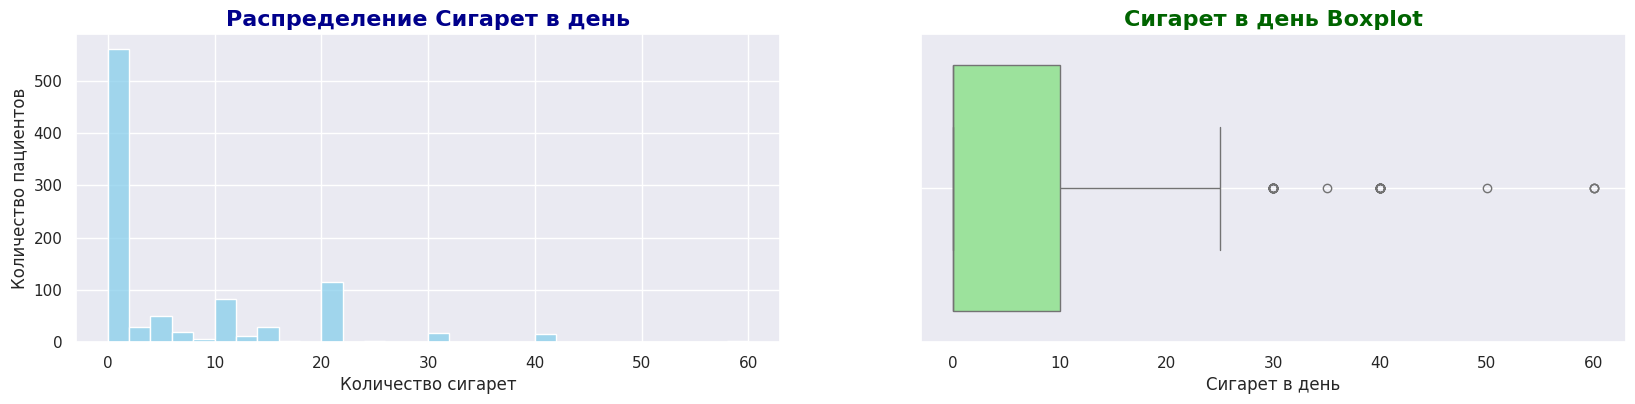

In [ ]:
sns.set_style("darkgrid")
sns.set_palette("Accent")
fix, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 4))
histplot = sns.histplot(data = heart, x = 'Сигарет в день', color='skyblue', ax=axes[0])
histplot.set_title('Распределение Сигарет в день',
                  fontsize=16,
                  fontweight='bold',
                  color='darkblue'
                  )
histplot.set_xlabel('Количество сигарет')
histplot.set_ylabel('Количество пациентов')

boxplot = sns.boxplot(data=heart, x='Сигарет в день',color='lightgreen', ax=axes[1])
boxplot.set_title(
                  'Сигарет в день Boxplot',
                  fontsize=16,
                  fontweight='bold',
                  color='darkgreen'
                  )
boxplot.set_xlabel('Сигарет в день')
boxplot.grid()

##### **1. Метод межквартильного размаха (метод Тьюки)**

In [ ]:
from IPython.display import Image

In [ ]:
def outliers_iqr(data, feature):
    x = data[feature]
    quartile_1, quartile_3 = x.quantile(0.25), x.quantile(0.75),
    iqr = quartile_3 - quartile_1
    lower_bound = quartile_1 - (iqr * 1.5)
    upper_bound = quartile_3 + (iqr * 1.5)
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

Применим эту функцию к таблице **heart** и признаку **Сигарет в день**, а также выведем размерности результатов:



In [ ]:
outliers, cleaned = outliers_iqr(heart, 'Сигарет в день')
print(f'Число выбросов по методу Тьюки: {outliers.shape[0]}')
print(f'Результирующее число записей: {cleaned.shape[0]}')

Число выбросов по методу Тьюки: 39
Результирующее число записей: 914


Согласно классическому методу Тьюки, под выбросы попали 39 записей в таблице. Построим гистограмму и коробчатую диаграмму на новых данных cleaned_heart:

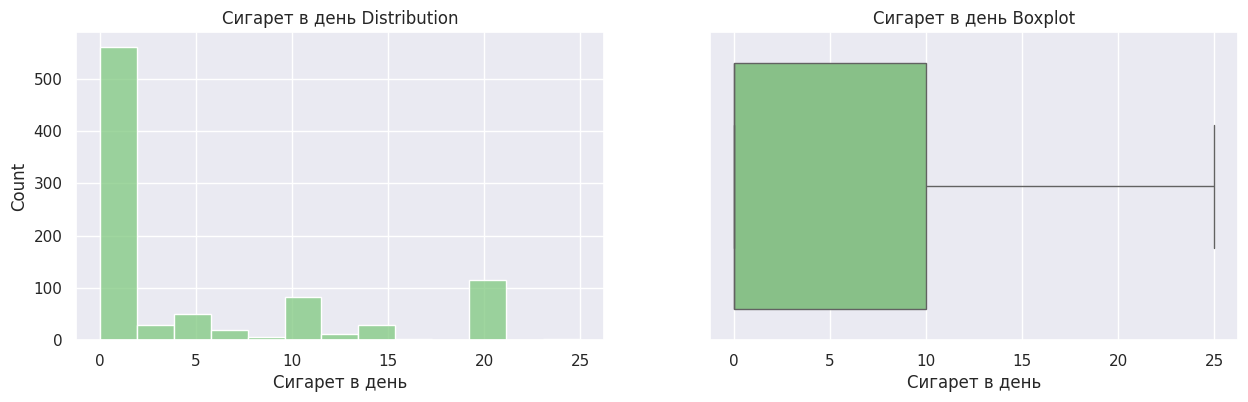

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))
histplot = sns.histplot(data=cleaned, x='Сигарет в день', ax=axes[0]);
histplot.set_title('Сигарет в день Distribution');
boxplot = sns.boxplot(data=cleaned, x='Сигарет в день', ax=axes[1]);
boxplot.set_title('Сигарет в день Boxplot');

Модифицируем функцию **outliers_iqr(data, feature).** Добавим в неё параметры **left** и **right**, которые задают число **IQR** влево и вправо от границ ящика. Функция, как и раньше, будет возвращать потенциальные выбросы и очищенный DataFrame.

In [ ]:
def outliers_iqr_mod(data, feature, left, right):
    x = data[feature]
    quartile_1, quartile_3 = x.quantile(0.25), x.quantile(0.75),
    iqr = quartile_3 - quartile_1
    lower_bound = quartile_1 - (iqr * left)
    upper_bound = quartile_3 + (iqr * right)
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

Ослабим границы метода Тьюки справа и усилим их влево. Применим модифицированную функцию outliers_iqr_mod() к признаку **Сигарет в день** данным с параметрами left=1 и right=2. Результаты работы поместим в переменные outliers и cleaned.

In [ ]:
outliers, cleaned = outliers_iqr_mod(heart, 'Сигарет в день', left=1, right=2)
print(f'Число выбросов по методу Тьюки: {outliers.shape[0]}')
print(f'Результирующее число записей: {cleaned.shape[0]}')

Число выбросов по методу Тьюки: 21
Результирующее число записей: 932


Если мы построим гистограмму и коробчатую диаграмму на полученных данных, то увидим вот такую картинку:

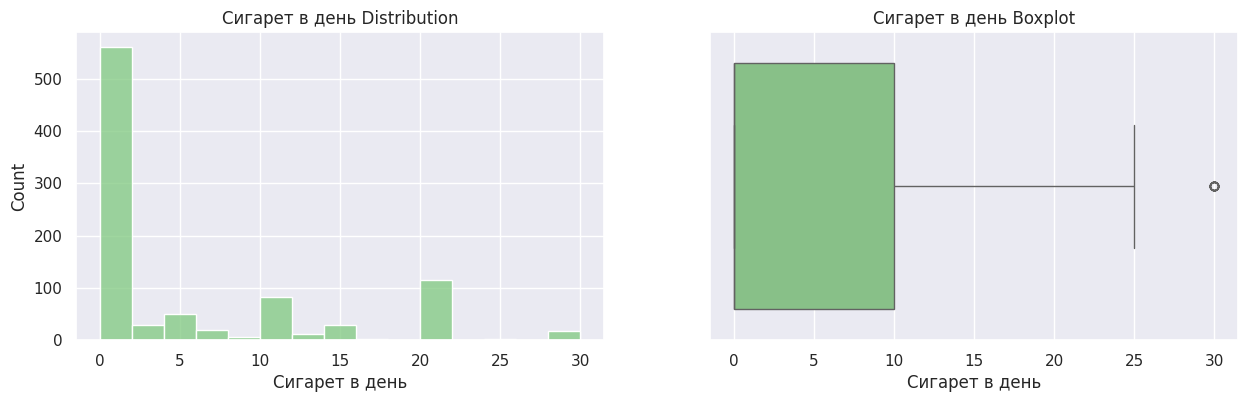

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))
histplot = sns.histplot(data=cleaned, x='Сигарет в день', ax=axes[0]);
histplot.set_title('Сигарет в день Distribution');
boxplot = sns.boxplot(data=cleaned, x='Сигарет в день', ax=axes[1]);
boxplot.set_title('Сигарет в день Boxplot');

##### **2. Метод z-отклонений (метод сигм)**

Построим две гистограммы признака **Сигарет в день**: первая — в обычном масштабе, а вторая — в логарифмическом. Логарифмировать будем с помощью функции log() из библиотеки numpy (натуральный логарифм — логарифм по основанию числа e). Признак имеет среди своих значений 0. Из математики известно, что логарифма от 0 не существует, поэтому мы прибавляем к нашему признаку 1, чтобы не логарифмировать нули и не получать предупреждения.

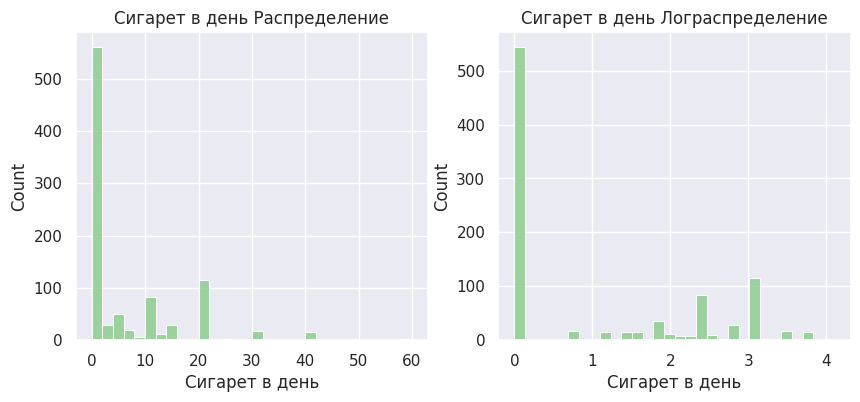

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

#гистограмма исходного признака
histplot = sns.histplot(heart['Сигарет в день'], bins=30, ax=axes[0])
histplot.set_title('Сигарет в день Распределение');

#гистограмма в логарифмическом масштабе
log_sig= np.log(heart['Сигарет в день'] + 1)
histplot = sns.histplot(log_sig , bins=30, ax=axes[1])
histplot.set_title('Сигарет в день Лограспределение');

Левое распределение напоминает логнормальное распределение с наличием потенциальных выбросов-«пеньков», далеко отстоящих от основной массы наблюдений. Если случайная величина имеет логнормальное распределение, то её логарифм имеет нормальное распределение. Опираясь на это применим метод z-отклонений к признаку после логарифмирования. Определим сначала функцию z-отклонений.


In [ ]:
def outliers_z_score(data, feature, log_scale=False):
    if log_scale:
        x = np.log(data[feature]+1)
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - 3 * sigma
    upper_bound = mu + 3 * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

Применим эту функцию к таблице **heart** и признаку **Сигарет в день**, а также выведем размерности результатов:

In [ ]:
outliers, cleaned = outliers_z_score(heart, 'Сигарет в день', log_scale=True)
print(f'Число выбросов по методу z-отклонения: {outliers.shape[0]}')
print(f'Результирующее число записей: {cleaned.shape[0]}')

Число выбросов по методу z-отклонения: 0
Результирующее число записей: 953


Если логарифм распределения не идеально нормален и в нём присутствует некоторая асимметрия, стоит дать некоторое «послабление» на границы интервалов. Построим гистограмму прологарифмированного распределения, а также отобразим на гистограмме вертикальные линии, соответствующие среднему (центру интервала в методе трёх сигм) и границы интервала μ+3σ. Вертикальные линии можно построить с помощью метода axvline(). Для среднего линия будет обычной, а для границ интервала — пунктирной (параметр ls ='--'):

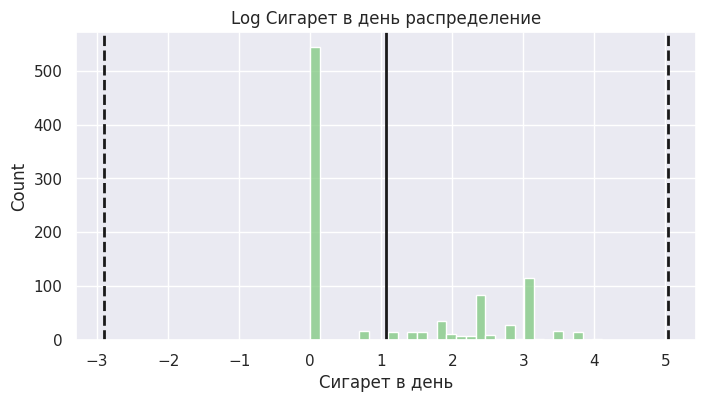

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
log_sig = np.log(heart['Сигарет в день'] + 1)
histplot = sns.histplot(log_sig, bins=30, ax=ax)
histplot.axvline(log_sig.mean(), color='k', lw=2)
histplot.axvline(log_sig.mean()+ 3 * log_sig.std(), color='k', ls='--', lw=2)
histplot.axvline(log_sig.mean()- 3 * log_sig.std(), color='k', ls='--', lw=2)
histplot.set_title('Log Сигарет в день распределение');

Расширим правило трёх сигм, чтобы иметь возможность учитывать особенности данных. Добавим в функцию outliers_z_score(data, feature, log_scale=False) параметры left и right, которые будут задавать число сигм (стандартных отклонений) влево и вправо соответственно, определяющее границы метода z-отклонения. По умолчанию оба параметры равны 3.

In [ ]:
def outliers_z_score_mod(data, feature, left, right, log_scale=False):
    if log_scale:
        x = np.log(data[feature]+1)
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - left * sigma
    upper_bound = mu + right * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

In [ ]:
outliers, cleaned = outliers_z_score_mod(heart, 'Сигарет в день',left=1, right=2, log_scale=True)
print(f'Число выбросов по методу z-отклонения: {outliers.shape[0]}')
print(f'Результирующее число записей: {cleaned.shape[0]}')

Число выбросов по методу z-отклонения: 20
Результирующее число записей: 933


##### **3. Метод ручного поиска и здравого смысла**

* Рассчитайте статистические показатели для переменной **"Сигарет в день"** с помощью функции **.describe()**

In [ ]:
heart['Сигарет в день'].describe()


,Сигарет в день
count,953.000000
mean,6.102833
std,9.684190
min,0.000000
25%,0.000000
50%,0.000000
75%,10.000000
max,60.000000


In [ ]:
# Подсчет количества строк, где "Сигарет в день" больше 40
count = heart[heart['Сигарет в день'] > 40].shape[0]

# Вывод результата
print(f'Количество строк с "Сигарет в день" больше 40: {count}')

Количество строк с "Сигарет в день" больше 40: 4


In [ ]:
# Фильтрация значений, где "Сигарет в день" больше 40
filtered_values = heart.loc[heart['Сигарет в день'] > 40, 'Сигарет в день']

# Вывод значений на экран
print(filtered_values)

208    60.0
256    50.0
309    60.0
818    60.0
Name: Сигарет в день, dtype: float64


In [ ]:
# Удаление строк, где "Сигарет в день" больше 40
heart = heart[heart['Сигарет в день'] <= 40]

In [ ]:
heart.shape

(949, 34)

In [ ]:
heart['Сигарет в день'].describe()

,Сигарет в день
count,949.000000
mean,5.886196
std,9.105321
min,0.000000
25%,0.000000
50%,0.000000
75%,10.000000
max,40.000000


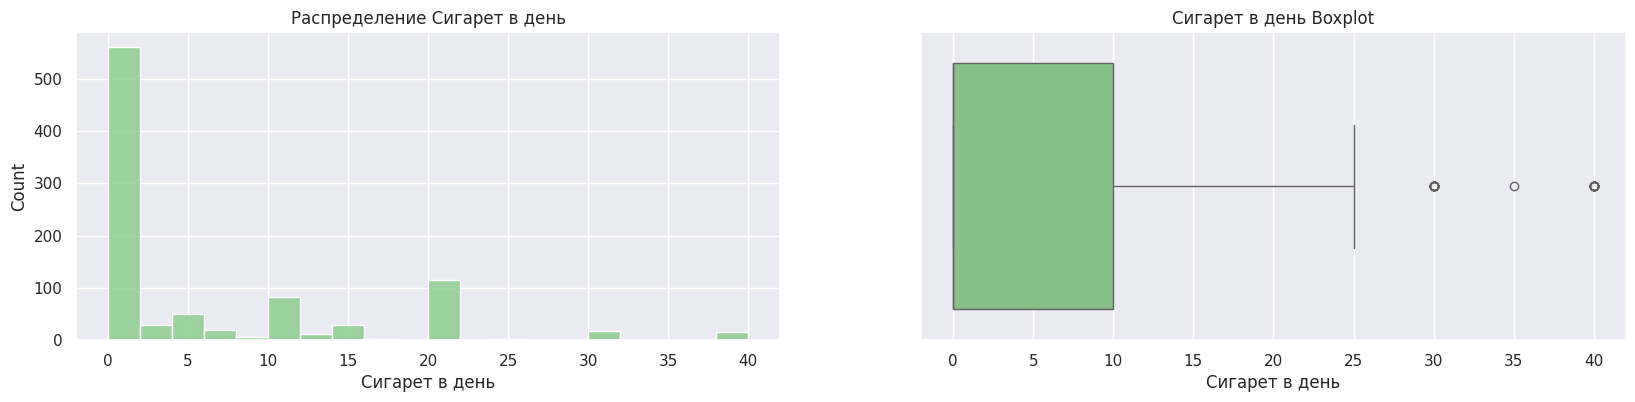

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 4))
histplot = sns.histplot(data=heart, x='Сигарет в день', ax=axes[0]);
histplot.set_title('Распределение Сигарет в день');
boxplot = sns.boxplot(data=heart, x='Сигарет в день', ax=axes[1]);
boxplot.set_title('Сигарет в день Boxplot');

### ОБРАБОТКА КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ

Категориальные переменные требуют соответствующей **кодировки** для обработки в моделях машинного обучения.

* Закодируем признак **Пол**

In [ ]:
heart['Пол'] = heart['Пол'].map({'М': 0, 'Ж': 1})

In [ ]:
heart.head().T

,0,1,2,3,4
ЛПНП,2.79,6.62,3.17,2.74,6.62
Возраст алког,18.0,90,17.0,13.0,16.0
Работа,1,0,0,1,0
Статус Курения,Курит,Никогда не курил(а),Никогда не курил(а),Бросил(а),Никогда не курил(а)
Пассивное курение,0,0,1,1,1
Переломы,0,1,0,0,1
Время пробуждения,06:00:00,04:00:00,07:00:00,07:00:00,06:00:00
ЛПВП,0.97,0.74,1.57,0.68,1.01
Выход на пенсию,0,0,0,0,0
Холестерин,4.0,8.6,5.2,4.9,8.2


* Исследуем признаки **Образование** и **Частота пасс кур**

In [ ]:
for col in ['Образование', 'Частота пасс кур']:
    print(heart[col].value_counts(dropna=False))
    print()

Образование
4 - профессиональное училище                         450
5 - ВУЗ                                              312
3 - средняя школа / закон.среднее / выше среднего    180
2 - начальная школа                                    7
Name: count, dtype: int64

Частота пасс кур
0                         726
1-2 раза в неделю          92
4 и более раз в день       47
2-3 раза в день            30
не менее 1 раза в день     29
3-6 раз в неделю           25
Name: count, dtype: int64



Признаки **Образование** и **Частота пасс кур** являются ординальными.

**Ординарные признаки** (также известные как порядковые или ранговые) - это характеристики, которые можно упорядочить по степени или уровню.

* Заменим все уникальные значения переменной **Частота пасс кур** на числа

In [ ]:
heart['Частота пасс кур'] = heart['Частота пасс кур'].map(
    {'0': 0,
     '1-2 раза в неделю': 1,
     '3-6 раз в неделю': 2,
     'не менее 1 раза в день': 3,
     '2-3 раза в день': 4,
     '4 и более раз в день': 5})

* Изменим тип переменной **Частота пасс кур** на целочисленный

In [ ]:
heart['Частота пасс кур'] = heart['Частота пасс кур'].astype(int)

* Закодируем признак **Образование**

In [ ]:
heart['Образование'] = heart['Образование'].str[:1].astype(int)

**.str[:1]** получает первый символ каждой строки, а **.astype(int)** преобразует полученные символы в целые числа (изначально они были строками).

* Посмотрим результат

In [ ]:
for col in ['Образование', 'Частота пасс кур']:
    print(heart[col].value_counts(dropna=False))
    print()

Образование
4    450
5    312
3    180
2      7
Name: count, dtype: int64

Частота пасс кур
0    726
1     92
5     47
4     30
3     29
2     25
Name: count, dtype: int64



### ОБРАБОТКА ЧИСЛОВЫХ ПРИЗНАКОВ

Рассмотрим переменные **Время пробуждения** и **Время засыпания**

* Закодируем время пробуждения, как час от полуночи, а время засыпания, как час от полудня

In [ ]:
heart['Время пробуждения'].head()

,Время пробуждения
0,06:00:00
1,04:00:00
2,07:00:00
3,07:00:00
4,06:00:00


In [ ]:
heart['Время пробуждения'] = heart['Время пробуждения'].str[:2].astype(int)
heart['Время засыпания'] = (heart['Время засыпания'].str[:2].astype(int) + 12) % 24

In [ ]:
heart['Время пробуждения'].head()

,Время пробуждения
0,6
1,4
2,7
3,7
4,6


* Добавим в датасет новый признак - **Продолжительность сна**

In [ ]:
heart['Продолжительность сна'] = heart['Время пробуждения'] - heart['Время засыпания'] + 12

* Посмотрим что у нас получилось

In [ ]:
heart.head(5)

,ЛПНП,Возраст алког,Работа,Статус Курения,Пассивное курение,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ,Продолжительность сна
0,2.79,18.0,1,Курит,0,0,6,0.97,0,4.0,...,0,10,0,20.0,3,25.1,Христианство,низкоквалифицированные работники,0,8
1,6.62,90,0,Никогда не курил(а),0,1,4,0.74,0,8.6,...,1,12,0,0.0,5,35.2,Христианство,дипломированные специалисты,1,4
2,3.17,17.0,0,Никогда не курил(а),1,0,7,1.57,0,5.2,...,0,11,0,0.0,5,19.0,Христианство,дипломированные специалисты,0,8
3,2.74,13.0,1,Бросил(а),1,0,7,0.68,0,4.9,...,0,11,0,10.0,3,31.6,Атеист / агностик,низкоквалифицированные работники,1,8
4,6.62,16.0,0,Никогда не курил(а),1,1,6,1.01,0,8.2,...,0,11,0,0.0,3,32.8,Христианство,операторы и монтажники установок и машинного о...,1,7


In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
Index: 949 entries, 0 to 954
Data columns (total 35 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ЛПНП                                    949 non-null    float64
 1   Возраст алког                           949 non-null    object 
 2   Работа                                  949 non-null    int64  
 3   Статус Курения                          949 non-null    object 
 4   Пассивное курение                       949 non-null    int64  
 5   Переломы                                949 non-null    int64  
 6   Время пробуждения                       949 non-null    int64  
 7   ЛПВП                                    949 non-null    float64
 8   Выход на пенсию                         949 non-null    int64  
 9   Холестерин                              949 non-null    float64
 10  Артериальная гипертония                 949 non-null    int64  
 11

Больше нет пропущенных значений. Осталось 6 категориальных признаков. Но прежде чем их кодировать, посмотрим корреляционные зависимости между всеми числовыми признаками.

In [ ]:
heart.corr(numeric_only=True).round(2)

,ЛПНП,Работа,Пассивное курение,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,...,Глюкоза плазмы натощак,"Абдоминальное ожирение, см",Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",ССЗ,Продолжительность сна
ЛПНП,1.00,-0.16,-0.00,0.11,-0.01,-0.33,0.18,0.95,0.63,0.16,...,0.30,0.58,0.06,-0.08,0.06,0.04,-0.06,0.58,0.69,0.05
Работа,-0.16,1.00,0.06,-0.06,-0.16,0.07,-0.74,-0.19,-0.19,-0.13,...,-0.08,-0.11,-0.15,-0.04,0.00,0.08,0.14,-0.19,-0.22,-0.11
Пассивное курение,-0.00,0.06,1.00,-0.04,-0.00,0.09,-0.03,0.01,0.03,-0.03,...,0.02,0.06,-0.05,-0.04,-0.04,-0.09,-0.02,0.03,0.02,0.03
Переломы,0.11,-0.06,-0.04,1.00,-0.01,-0.15,0.07,0.11,0.08,0.08,...,0.04,0.17,0.05,0.01,0.07,0.07,-0.08,0.12,0.12,-0.02
Время пробуждения,-0.01,-0.16,-0.00,-0.01,1.00,0.04,0.10,-0.01,0.02,-0.02,...,-0.04,-0.00,-0.01,0.30,-0.10,-0.05,0.05,-0.03,0.00,0.67
ЛПВП,-0.33,0.07,0.09,-0.15,0.04,1.00,-0.09,-0.45,-0.55,-0.78,...,-0.25,-0.67,-0.10,-0.03,-0.03,-0.28,0.17,-0.57,-0.58,0.06
Выход на пенсию,0.18,-0.74,-0.03,0.07,0.10,-0.09,1.00,0.22,0.23,0.14,...,0.09,0.15,0.11,0.01,-0.00,-0.13,-0.12,0.22,0.25,0.08
Холестерин,0.95,-0.19,0.01,0.11,-0.01,-0.45,0.22,1.00,0.73,0.44,...,0.35,0.59,0.04,-0.07,0.07,-0.05,-0.05,0.62,0.79,0.04
Артериальная гипертония,0.63,-0.19,0.03,0.08,0.02,-0.55,0.23,0.73,1.00,0.56,...,0.42,0.67,0.05,-0.00,0.05,-0.08,-0.06,0.70,0.88,0.02
Триглицериды,0.16,-0.13,-0.03,0.08,-0.02,-0.78,0.14,0.44,0.56,1.00,...,0.25,0.41,0.00,0.01,0.03,-0.05,-0.07,0.43,0.56,-0.03


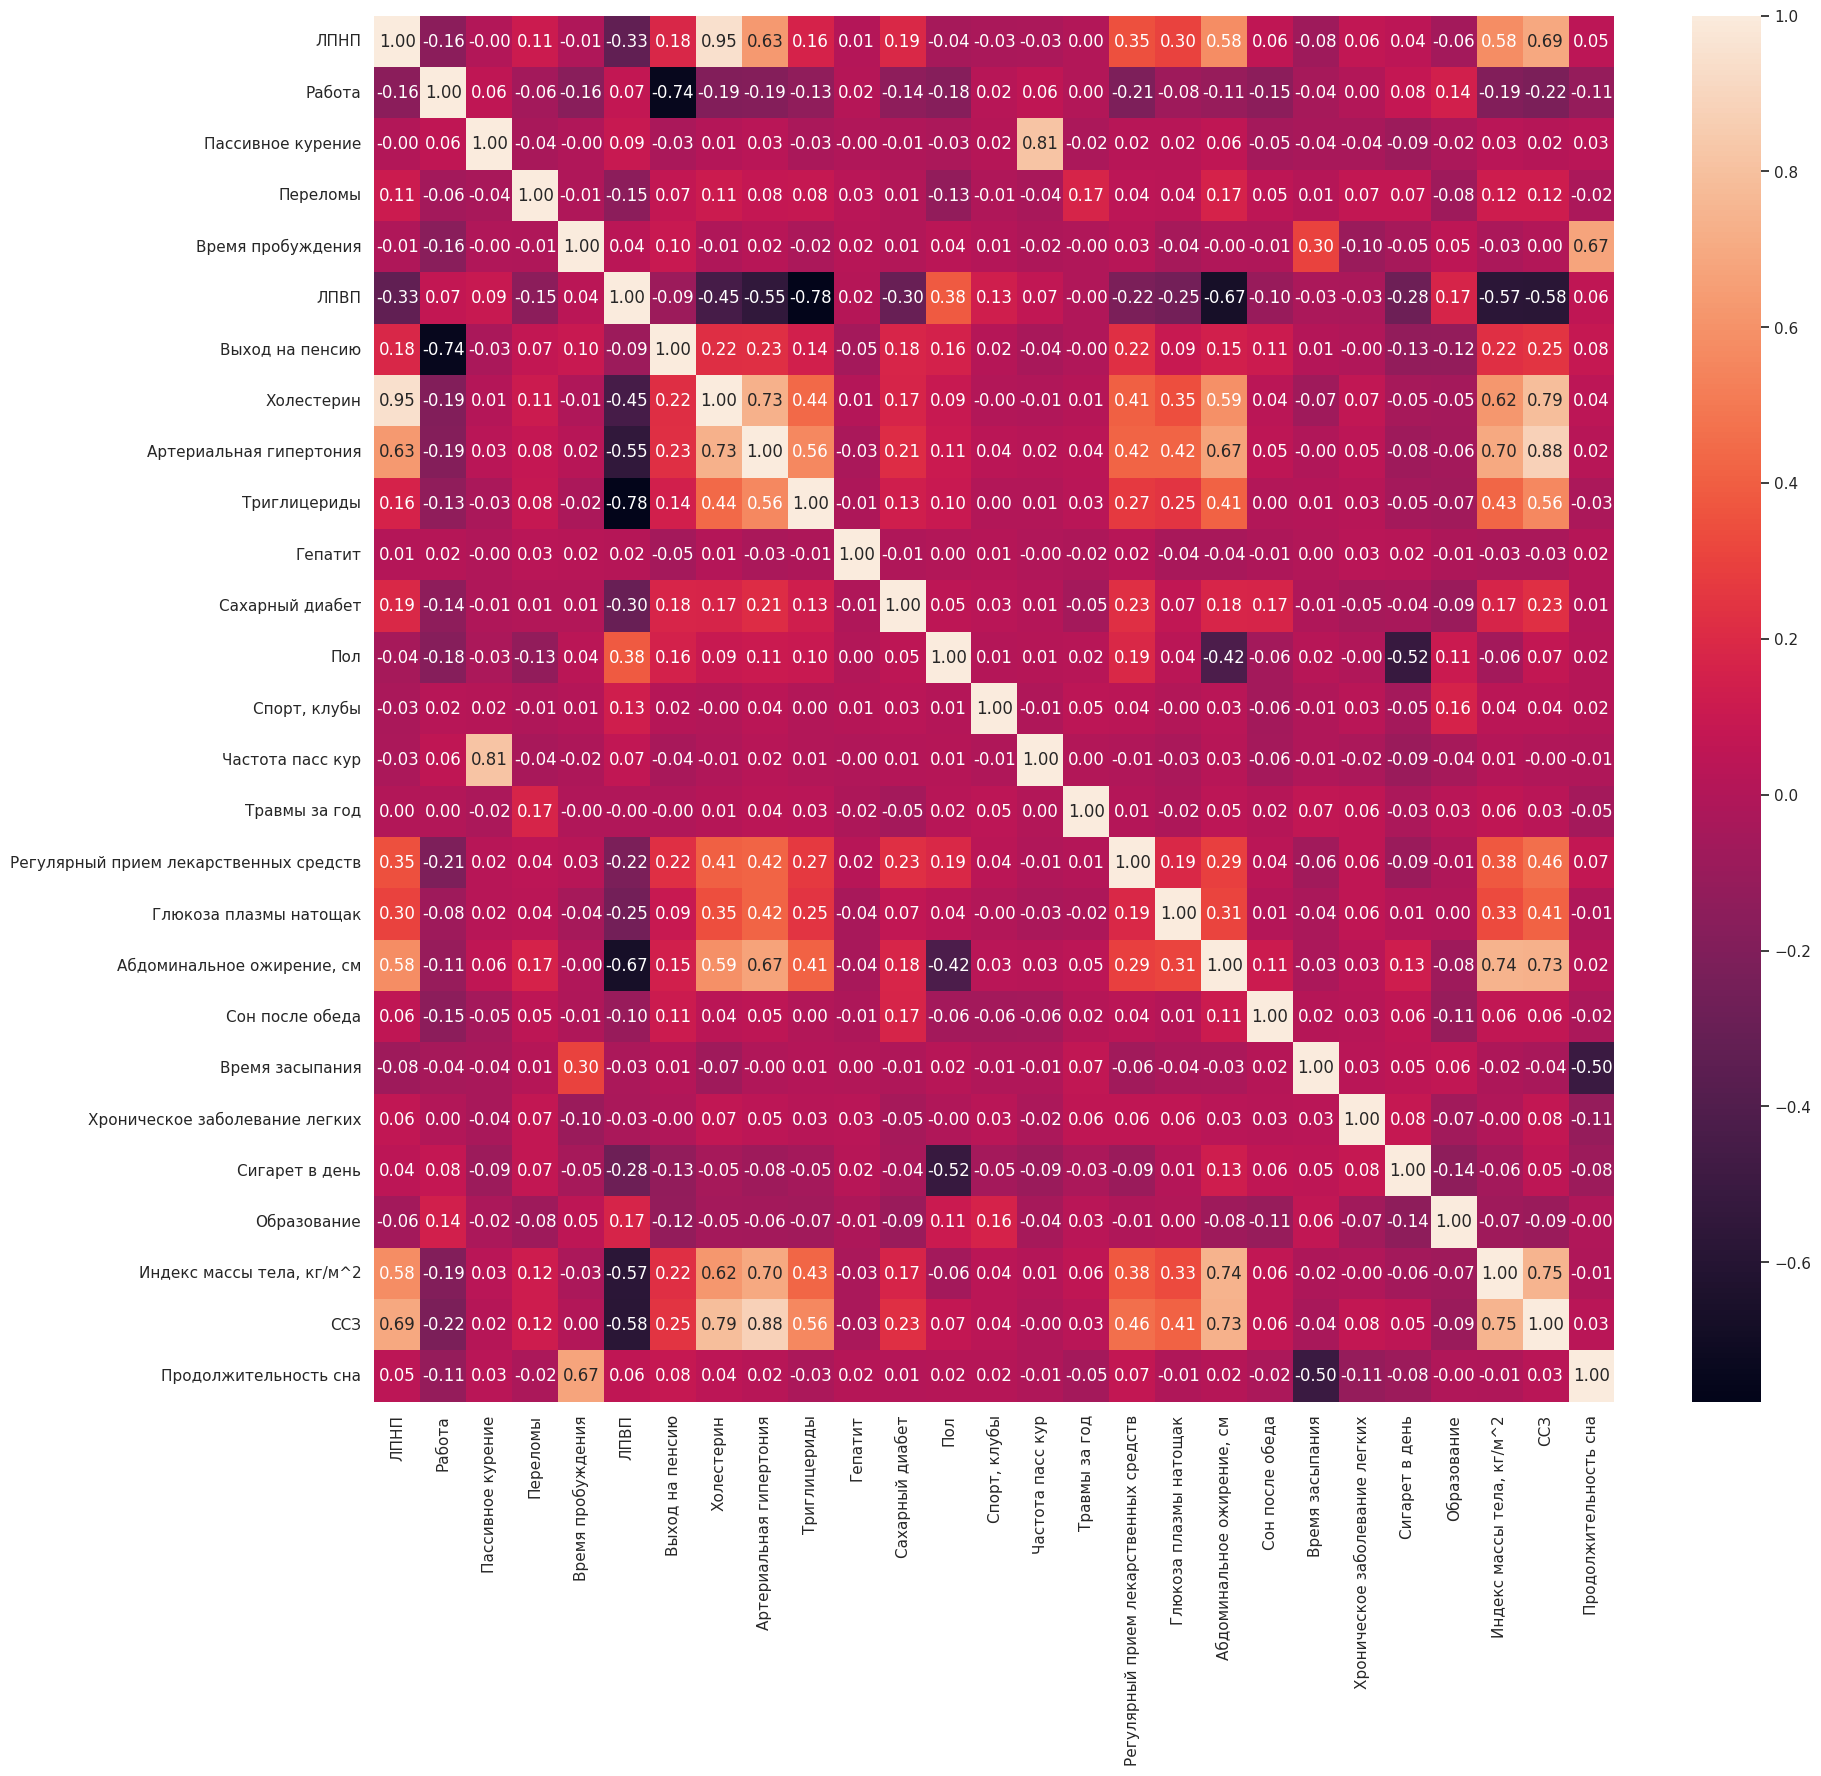

In [ ]:
plt.figure(figsize = (20,18))
# heart.corr(numeric_only=True): вычисляет корреляционную матрицу для числовых столбцов DataFrame heart
# annot=True: отображает числовые значения корреляций на тепловой карте
# fmt=".2f": определяет формат числовых значений, отображаемых на тепловой карте (2 знака после запятой)
ax = sns.heatmap(heart.corr(numeric_only=True), annot = True, fmt = ".2f")

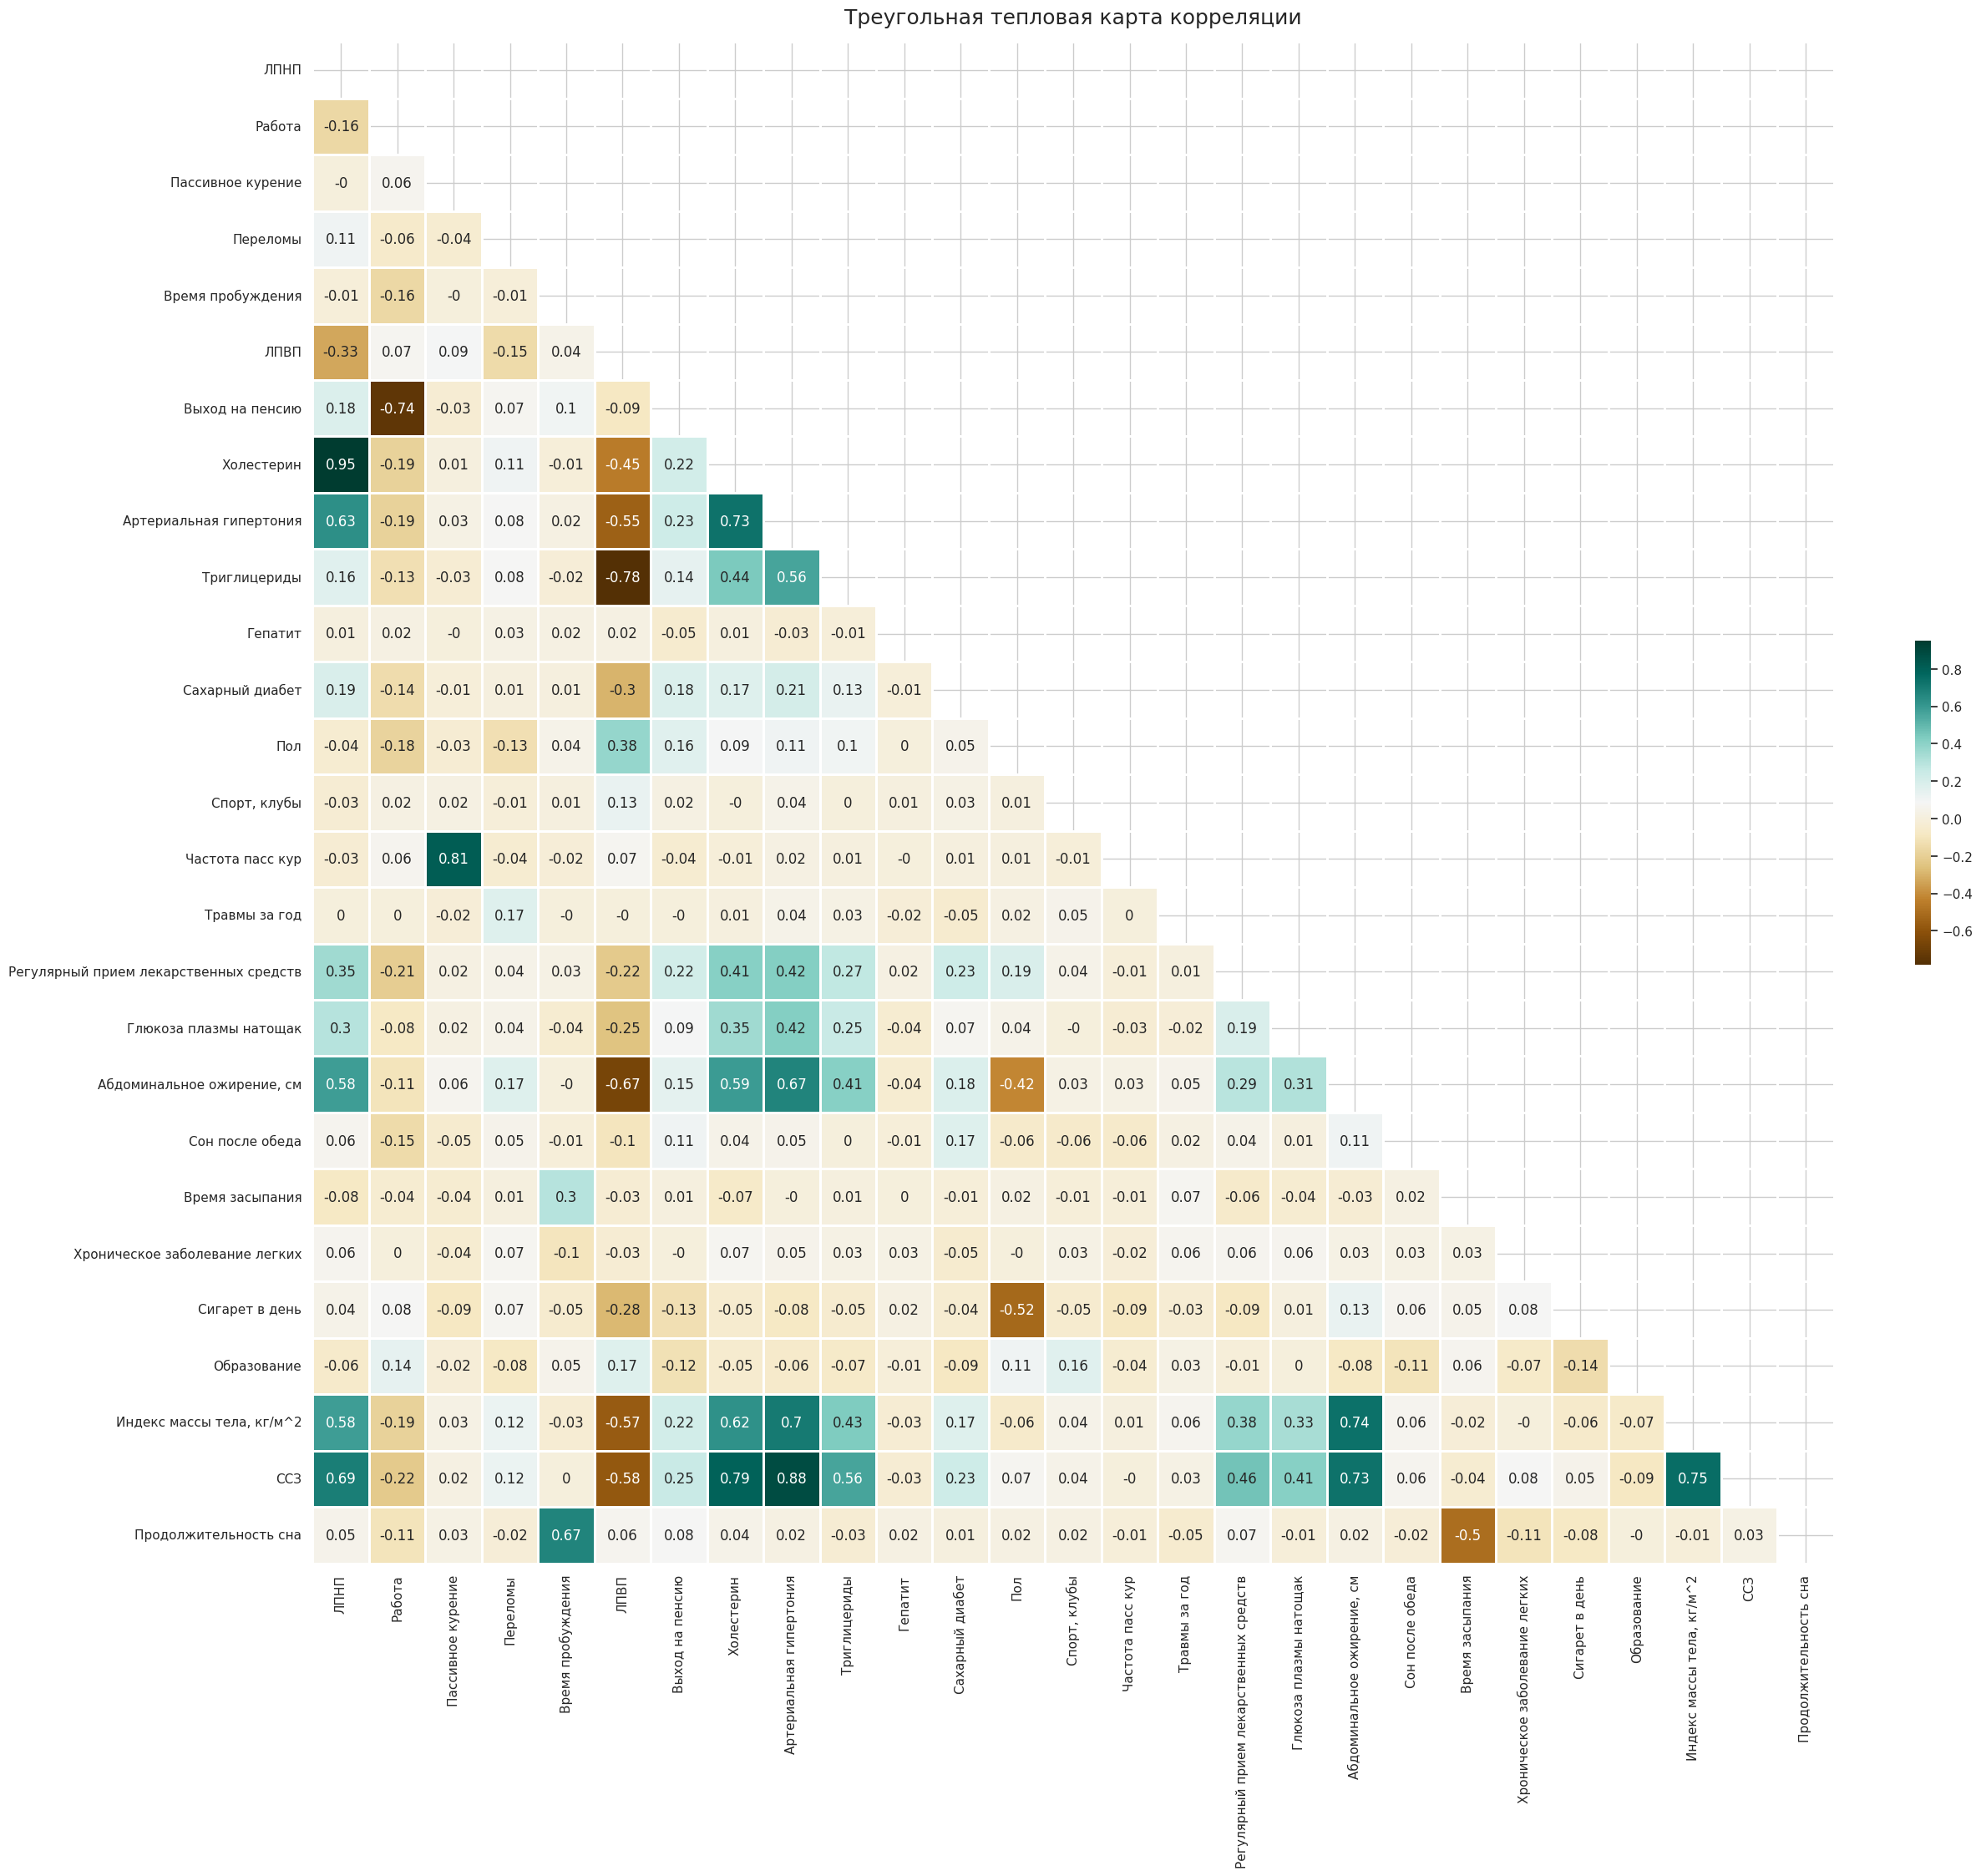

In [ ]:
plt.rcParams["figure.figsize"] = (25, 25)
sns.set_style("whitegrid")

# Воспользуемся функциями np.triu, чтобы изолировать верхний треугольник (np.tril нижний)
# функция np.ones_like() изменит все изолированные значения на 1.
mask = np.triu(np.ones_like(heart.corr(numeric_only=True), dtype=bool))

heatmap = sns.heatmap(
    heart.corr(numeric_only=True).round(2),
    annot=True, # annot=True: отображает числовые значения корреляций на тепловой карте
    square=True, # ячейки будут квадратными
    cmap="BrBG", # указывает цветовую палитру «коричневый-синий-зелёный»
    cbar_kws={"fraction": 0.01}, # размер цветовой шкалы (colorbar) уменьшается на 0,01.
    linewidth=1, # указывает, что между каждой ячейкой (бином) будет добавлена тонкая белая линия

    mask=mask,
)

heatmap.set_title(
    "Треугольная тепловая карта корреляции", fontdict={"fontsize": 18}, pad=16
);

In [ ]:
corr = heart.corr(numeric_only=True).round(4)
m = (corr.mask(np.eye(len(corr), dtype=bool)).abs() > 0.8).any()
raw = corr.loc[m, m]
raw

,ЛПНП,Пассивное курение,Холестерин,Артериальная гипертония,Частота пасс кур,ССЗ
ЛПНП,1.0000,-0.0004,0.9462,0.6274,-0.0253,0.6929
Пассивное курение,-0.0004,1.0000,0.0069,0.0283,0.8132,0.0173
Холестерин,0.9462,0.0069,1.0000,0.7317,-0.0068,0.7872
Артериальная гипертония,0.6274,0.0283,0.7317,1.0000,0.0207,0.8809
Частота пасс кур,-0.0253,0.8132,-0.0068,0.0207,1.0000,-0.0010
ССЗ,0.6929,0.0173,0.7872,0.8809,-0.0010,1.0000


Признаки **Пассивное курение** и **Частота пасс кур**, **Холестерин** и **ЛПНП** сильно коррелируют. Удалим один из них


In [ ]:
heart = heart.drop(columns=["Пассивное курение", "ЛПНП"], axis=1)

In [ ]:
heart.shape

(949, 33)

In [ ]:
heart.columns

Index(['Возраст алког', 'Работа', 'Статус Курения', 'Переломы',
       'Время пробуждения', 'ЛПВП', 'Выход на пенсию', 'Холестерин',
       'Артериальная гипертония', 'Триглицериды', 'Гепатит', 'Сахарный диабет',
       'Пол', 'Спорт, клубы', 'Семья', 'Частота пасс кур', 'Возраст курения',
       'Травмы за год', 'Регулярный прием лекарственных средств',
       'Национальность', 'Алкоголь', 'Глюкоза плазмы натощак',
       'Абдоминальное ожирение, см', 'Сон после обеда', 'Время засыпания',
       'Хроническое заболевание легких', 'Сигарет в день', 'Образование',
       'Индекс массы тела, кг/м^2', 'Религия', 'Профессия', 'ССЗ',
       'Продолжительность сна'],
      dtype='object')

* Сохраним результат анализа на данный момент в новый датасет

##### **Промежуточое сохранение без кодировки 6 категорийных признаков**

In [ ]:
heart.to_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart1.csv', index=False)

* Рассмотрим подробнее какие уникальные значения имеют 6 категориальных переменных, которые нам необходимо закодировать числовыми значениями

In [ ]:
for col in ['Семья', 'Национальность', 'Религия', 'Профессия', 'Статус Курения', 'Алкоголь']:
    print(heart[col].value_counts(dropna=False))
    print()

Семья
в браке в настоящее время                          559
вдовец / вдова                                     142
в разводе                                          124
гражданский брак / проживание с партнером           79
никогда не был(а) в браке                           43
раздельное проживание (официально не разведены)      2
Name: count, dtype: int64

Национальность
Русские                  895
Татары                    17
Немцы                      6
Чуваши                     5
Азербайджанцы              4
Украинцы                   4
Другие национальности      2
Армяне                     2
Казахи                     2
Киргизы                    2
Евреи                      2
Таджики                    2
Эстонцы                    1
Молдаване                  1
Мордва                     1
Белорусы                   1
Башкиры                    1
Буряты                     1
Name: count, dtype: int64

Религия
Христианство         799
Атеист / агностик     85
Нет            

* Посчитаем сколько уникальных значений имеет категориальные признаки

In [ ]:
columns_to_change = ['Семья', 'Национальность', 'Религия', 'Профессия', 'Статус Курения', 'Алкоголь']
for column in columns_to_change:
 print('Число уникальных значений признака {}: '.format(column), heart[column].nunique())

Число уникальных значений признака Семья:  6
Число уникальных значений признака Национальность:  18
Число уникальных значений признака Религия:  4
Число уникальных значений признака Профессия:  11
Число уникальных значений признака Статус Курения:  3
Число уникальных значений признака Алкоголь:  3


##### 1. Кодирование категориальных переменных **OneHot-методом**




In [ ]:
# Инициализация кодировщика
one_hot_encoder = OneHotEncoder()

In [ ]:
# Обучаем энкодер, применяем преобразование к выборке. Результат переводим в массив
heart_onehot = one_hot_encoder.fit_transform(heart[columns_to_change]).toarray()

In [ ]:
# Сохраним полученные названия новых колонок в переменную colums
columns = one_hot_encoder.get_feature_names_out(columns_to_change)

In [ ]:
# Преобразуем массив в формат DataFrame
heart_onehot_df = pd.DataFrame(heart_onehot, columns=columns)

In [ ]:
# Переустановим индексацию в таблицах
# reset_index() — изменяет индексы с рандомных на последовательные от 0 до n
# drop(['index'], axis = 1) — удаляет образовавшийся столбец 'index'
heart = heart.reset_index().drop(['index'], axis = 1)

In [ ]:
# Объединим таблицы
heart = pd.concat([heart, heart_onehot_df], axis=1)

In [ ]:
# Удалим старые категориальные признаки
heart = heart.drop(columns=columns_to_change)

In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 72 columns):
 #   Column                                                                                         Non-Null Count  Dtype  
---  ------                                                                                         --------------  -----  
 0   Возраст алког                                                                                  949 non-null    object 
 1   Работа                                                                                         949 non-null    int64  
 2   Переломы                                                                                       949 non-null    int64  
 3   Время пробуждения                                                                              949 non-null    int64  
 4   ЛПВП                                                                                           949 non-null    float64
 5   Выход на пенсию       

In [ ]:
heart.columns

Index(['Возраст алког', 'Работа', 'Переломы', 'Время пробуждения', 'ЛПВП',
       'Выход на пенсию', 'Холестерин', 'Артериальная гипертония',
       'Триглицериды', 'Гепатит', 'Сахарный диабет', 'Пол', 'Спорт, клубы',
       'Частота пасс кур', 'Возраст курения', 'Травмы за год',
       'Регулярный прием лекарственных средств', 'Глюкоза плазмы натощак',
       'Абдоминальное ожирение, см', 'Сон после обеда', 'Время засыпания',
       'Хроническое заболевание легких', 'Сигарет в день', 'Образование',
       'Индекс массы тела, кг/м^2', 'ССЗ', 'Продолжительность сна',
       'Семья_в браке в настоящее время', 'Семья_в разводе',
       'Семья_вдовец / вдова',
       'Семья_гражданский брак / проживание с партнером',
       'Семья_никогда не был(а) в браке',
       'Семья_раздельное проживание (официально не разведены)',
       'Национальность_Азербайджанцы', 'Национальность_Армяне',
       'Национальность_Башкиры', 'Национальность_Белорусы',
       'Национальность_Буряты', 'Национальность

In [ ]:
heart.head().T

,0,1,2,3,4
Возраст алког,18.0,90,17.0,13.0,16.0
Работа,1,0,0,1,0
Переломы,0,1,0,0,1
Время пробуждения,6,4,7,7,6
ЛПВП,0.97,0.74,1.57,0.68,1.01
...,...,...,...,...,...
Статус Курения_Курит,1.0,0.0,0.0,0.0,0.0
Статус Курения_Никогда не курил(а),0.0,1.0,1.0,0.0,1.0
Алкоголь_никогда не употреблял,0.0,1.0,0.0,0.0,0.0
Алкоголь_ранее употреблял,0.0,0.0,0.0,0.0,0.0


Такого же результата можно было добиться с помощью следующего кода:

In [ ]:
#def encode_data(heart, columns_to_change):
#  dummies = pd.get_dummies(heart[[columns_to_change]], dtype='int')
#  res = pd.concat([heart, dummies], axis=1)
#  res = res.drop([columns_to_change], axis=1)
#  return (res)
#for feature in columns_to_change:
# heart = encode_data(heart, feature)

* Построим матрицу корреляций

In [ ]:
heart.corr(numeric_only=True)

,Работа,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,Гепатит,Сахарный диабет,...,"Профессия_работники, занятые в сфере обслуживания, торговые работники магазинов и рынков",Профессия_ремесленники и представители других отраслей промышленности,Профессия_служащие,Профессия_техники и младшие специалисты,Статус Курения_Бросил(а),Статус Курения_Курит,Статус Курения_Никогда не курил(а),Алкоголь_никогда не употреблял,Алкоголь_ранее употреблял,Алкоголь_употребляю в настоящее время
Работа,1.000000,-0.059346,-0.163078,0.069345,-0.744403,-0.193728,-0.187557,-0.134104,0.017931,-0.139983,...,0.028794,-0.098500,0.017296,-0.021997,-0.042164,0.136748,-0.082366,-0.074760,-0.109440,0.145446
Переломы,-0.059346,1.000000,-0.013959,-0.153113,0.073549,0.112110,0.076169,0.083114,0.029760,0.005025,...,-0.035577,0.080041,-0.025846,-0.009843,0.018122,0.045490,-0.053333,-0.044076,0.001697,0.033890
Время пробуждения,-0.163078,-0.013959,1.000000,0.040359,0.100311,-0.014496,0.024831,-0.022599,0.020644,0.005079,...,-0.015722,-0.015800,0.005397,0.020615,0.027185,-0.011987,-0.011729,-0.079109,-0.000148,0.063328
ЛПВП,0.069345,-0.153113,0.040359,1.000000,-0.090318,-0.450709,-0.546301,-0.778913,0.019355,-0.304419,...,0.017863,-0.129350,0.043660,0.042939,0.016195,-0.300843,0.242968,0.045519,-0.067096,0.016174
Выход на пенсию,-0.744403,0.073549,0.100311,-0.090318,1.000000,0.217564,0.225669,0.140576,-0.051547,0.178070,...,-0.081194,0.100905,0.001356,0.025654,-0.013035,-0.145098,0.134001,0.067358,0.024525,-0.073030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Статус Курения_Курит,0.136748,0.045490,-0.011987,-0.300843,-0.145098,-0.071183,-0.076986,-0.055472,0.018865,-0.057647,...,0.034368,0.029697,-0.047515,-0.076169,-0.273140,1.000000,-0.630709,-0.130069,-0.025501,0.123904
Статус Курения_Никогда не курил(а),-0.082366,-0.053333,-0.011729,0.242968,0.134001,0.066667,0.081750,0.066615,-0.055822,0.076205,...,-0.038778,-0.078390,0.031128,0.094951,-0.574239,-0.630709,1.000000,0.209242,-0.088449,-0.097926
Алкоголь_никогда не употреблял,-0.074760,-0.044076,-0.079109,0.045519,0.067358,0.065423,0.032526,0.071303,-0.057808,-0.010701,...,0.023902,-0.031497,-0.060247,0.093107,-0.122161,-0.130069,0.209242,1.000000,-0.201205,-0.641481
Алкоголь_ранее употреблял,-0.109440,0.001697,-0.000148,-0.067096,0.024525,0.019618,0.021131,0.006566,0.010631,0.071181,...,-0.051681,0.063201,0.063201,0.030098,0.136547,-0.025501,-0.088449,-0.201205,1.000000,-0.622382


* Нарисуем тепловую карту матрицы корреляций

In [ ]:
plt.figure(figsize = (45,38))
ax = sns.heatmap(heart.corr(numeric_only=True), annot = True, fmt = ".2f")
i, k = ax.get_ylim()
ax.set_ylim(i+0.5, k-0.5)

Output hidden; open in https://colab.research.google.com to view.

* Найдём все признаки, корреляция которых выше 0,8

In [ ]:
corr = heart.corr(numeric_only=True)
m = (corr.mask(np.eye(len(corr), dtype=bool)).abs() > 0.8).any()
raw = corr.loc[m, m]
raw

,Артериальная гипертония,ССЗ
Артериальная гипертония,1.000000,0.880934
ССЗ,0.880934,1.000000


Удалим одну из коррелирующих переменных в каждой паре.

In [ ]:
heart.drop(columns=['Статус Курения_Никогда не курил(а)','Алкоголь_никогда не употреблял'], axis=1, inplace=True)

* Сохраним результат в новый набор данных

In [ ]:
heart.to_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart2.csv', index=False)

##### 2. Кодирования категориальных признаков - **по популярности**

* Вернёмся к набору данных до кодирования  6 признаков

In [ ]:
heart = pd.read_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart1.csv')
heart.head (3)

,Возраст алког,Работа,Статус Курения,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ,Продолжительность сна
0,18.0,1,Курит,0,6,0.97,0,4.0,0,0.52,...,0,10,0,20.0,3,25.1,Христианство,низкоквалифицированные работники,0,8
1,90.0,0,Никогда не курил(а),1,4,0.74,0,8.6,0,2.73,...,1,12,0,0.0,5,35.2,Христианство,дипломированные специалисты,1,4
2,17.0,0,Никогда не курил(а),0,7,1.57,0,5.2,0,1.02,...,0,11,0,0.0,5,19.0,Христианство,дипломированные специалисты,0,8


* Закодируем признаки по популярности с добавлением в закодированные значения небольшого уровня шума, чтобы различать категории с одинаковой популярностью

In [ ]:
np.random.seed(42)
cats = ['Семья', 'Национальность', 'Религия', 'Профессия', 'Статус Курения', 'Алкоголь']
for cat in cats:
    heart[cat] = heart[cat].map(heart[cat].value_counts()) + 0.1 * np.random.random(len(heart))

* Посмотрим результат данной кодировки

In [ ]:
heart[cats].head()

,Семья,Национальность,Религия,Профессия,Статус Курения,Алкоголь
0,559.037454,895.059741,799.035538,136.025100,219.053229,631.005383
1,124.095071,895.060052,799.078379,224.056407,541.010327,163.018988
2,559.073199,895.066504,799.055423,224.035858,541.017252,631.003896
3,559.059866,895.017537,85.000523,136.065663,189.056797,631.039181
4,559.015602,895.091441,799.076099,72.024040,541.029636,631.080240


In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 33 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Возраст алког                           949 non-null    float64
 1   Работа                                  949 non-null    int64  
 2   Статус Курения                          949 non-null    float64
 3   Переломы                                949 non-null    int64  
 4   Время пробуждения                       949 non-null    int64  
 5   ЛПВП                                    949 non-null    float64
 6   Выход на пенсию                         949 non-null    int64  
 7   Холестерин                              949 non-null    float64
 8   Артериальная гипертония                 949 non-null    int64  
 9   Триглицериды                            949 non-null    float64
 10  Гепатит                                 949 non-null    int64 

In [ ]:
heart.corr(numeric_only=True).round(2)

,Возраст алког,Работа,Статус Курения,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ,Продолжительность сна
Возраст алког,1.00,-0.09,0.22,-0.04,-0.09,0.04,0.08,0.08,0.04,0.08,...,-0.02,0.03,0.00,-0.21,-0.04,0.06,0.04,0.04,0.04,-0.11
Работа,-0.09,1.00,-0.08,-0.06,-0.16,0.07,-0.74,-0.19,-0.19,-0.13,...,-0.15,-0.04,0.00,0.08,0.14,-0.19,-0.03,0.08,-0.22,-0.11
Статус Курения,0.22,-0.08,1.00,-0.05,-0.01,0.23,0.13,0.06,0.08,0.07,...,-0.05,-0.07,-0.06,-0.74,0.10,0.15,0.09,0.13,0.03,0.04
Переломы,-0.04,-0.06,-0.05,1.00,-0.01,-0.15,0.07,0.11,0.08,0.08,...,0.05,0.01,0.07,0.07,-0.08,0.12,-0.02,-0.08,0.12,-0.02
Время пробуждения,-0.09,-0.16,-0.01,-0.01,1.00,0.04,0.10,-0.01,0.02,-0.02,...,-0.01,0.30,-0.10,-0.05,0.05,-0.03,0.06,-0.02,0.00,0.67
ЛПВП,0.04,0.07,0.23,-0.15,0.04,1.00,-0.09,-0.45,-0.55,-0.78,...,-0.10,-0.03,-0.03,-0.28,0.17,-0.57,0.01,0.13,-0.58,0.06
Выход на пенсию,0.08,-0.74,0.13,0.07,0.10,-0.09,1.00,0.22,0.23,0.14,...,0.11,0.01,-0.00,-0.13,-0.12,0.22,0.05,-0.06,0.25,0.08
Холестерин,0.08,-0.19,0.06,0.11,-0.01,-0.45,0.22,1.00,0.73,0.44,...,0.04,-0.07,0.07,-0.05,-0.05,0.62,0.06,-0.05,0.79,0.04
Артериальная гипертония,0.04,-0.19,0.08,0.08,0.02,-0.55,0.23,0.73,1.00,0.56,...,0.05,-0.00,0.05,-0.08,-0.06,0.70,0.08,-0.05,0.88,0.02
Триглицериды,0.08,-0.13,0.07,0.08,-0.02,-0.78,0.14,0.44,0.56,1.00,...,0.00,0.01,0.03,-0.05,-0.07,0.43,0.07,-0.03,0.56,-0.03


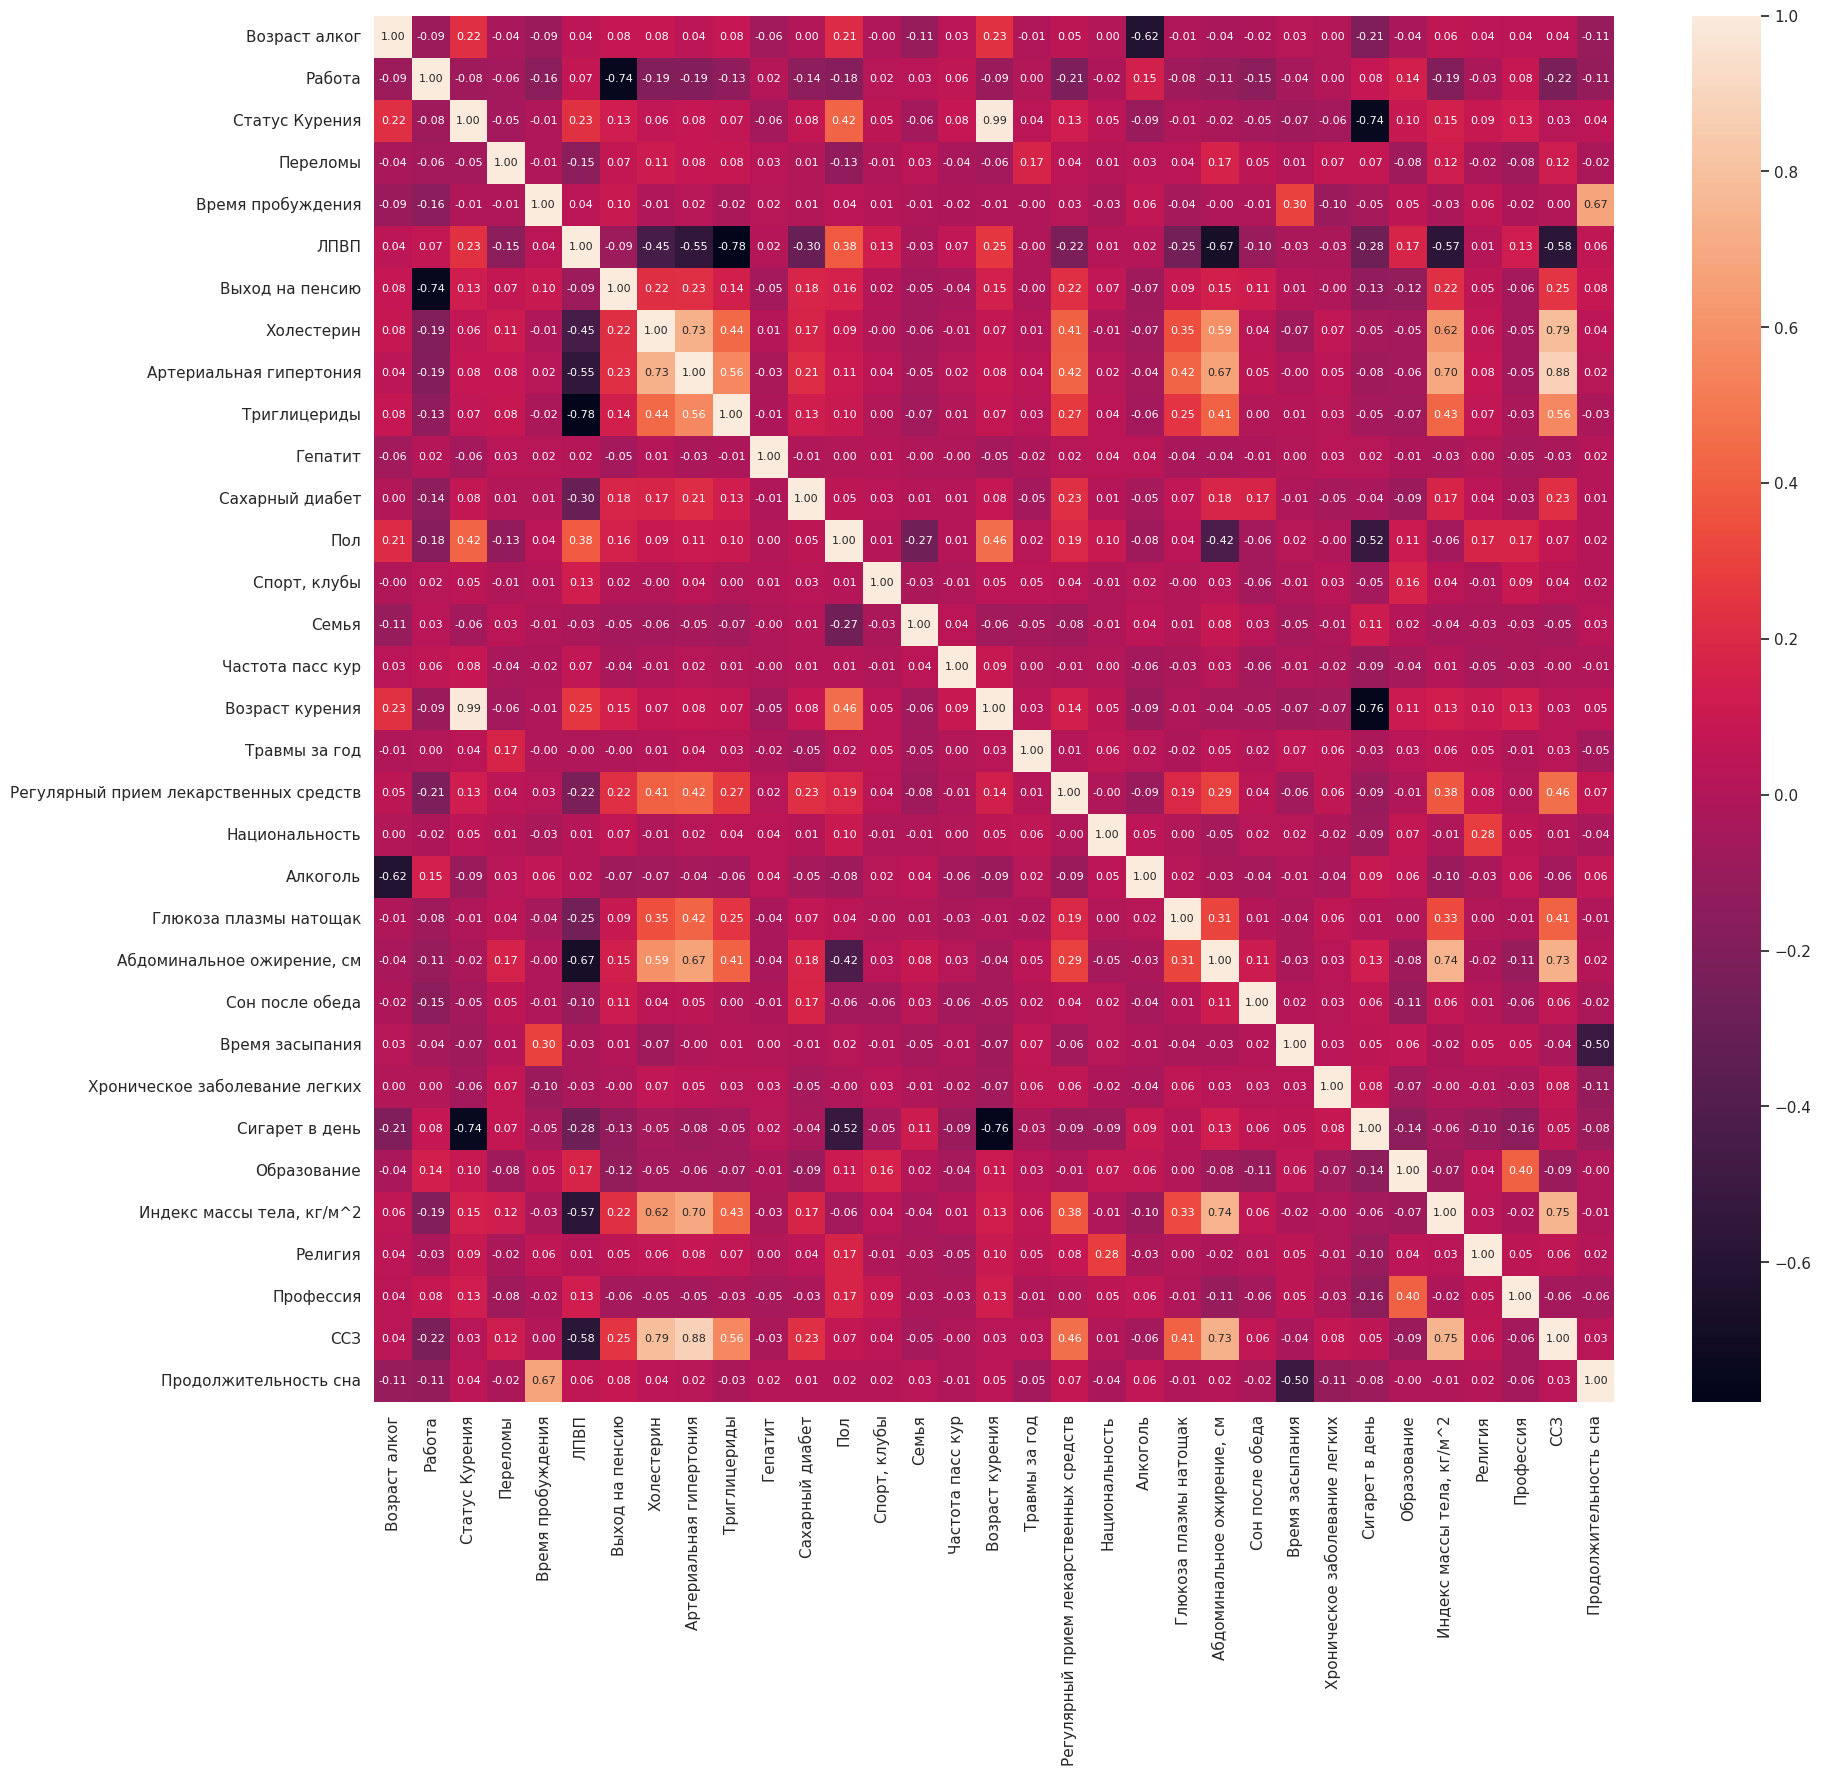

In [ ]:
plt.figure(figsize = (20,18))
annot_settings = {'fontsize': 8}
ax = sns.heatmap(heart.corr(numeric_only=True), annot = True, fmt = ".2f", annot_kws = annot_settings);

In [ ]:
corr = heart.corr(numeric_only=True)
m = (corr.mask(np.eye(len(corr), dtype=bool)).abs() > 0.8).any()
raw = corr.loc[m, m]
raw

,Статус Курения,Артериальная гипертония,Возраст курения,ССЗ
Статус Курения,1.000000,0.079671,0.987552,0.025854
Артериальная гипертония,0.079671,1.000000,0.082982,0.880934
Возраст курения,0.987552,0.082982,1.000000,0.031527
ССЗ,0.025854,0.880934,0.031527,1.000000


* Удалим одну из сильно коррелирующих переменных

In [ ]:
heart.drop('Статус Курения', axis=1, inplace=True)

* Сохраним результат в новый набор данных

In [ ]:
heart.to_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart3.csv', index=False)

##### 3. OneHot метод + бинарное кодирование

In [ ]:
heart=pd.read_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart1.csv')
heart.head()

,Возраст алког,Работа,Статус Курения,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,...,Сон после обеда,Время засыпания,Хроническое заболевание легких,Сигарет в день,Образование,"Индекс массы тела, кг/м^2",Религия,Профессия,ССЗ,Продолжительность сна
0,18.0,1,Курит,0,6,0.97,0,4.0,0,0.52,...,0,10,0,20.0,3,25.1,Христианство,низкоквалифицированные работники,0,8
1,90.0,0,Никогда не курил(а),1,4,0.74,0,8.6,0,2.73,...,1,12,0,0.0,5,35.2,Христианство,дипломированные специалисты,1,4
2,17.0,0,Никогда не курил(а),0,7,1.57,0,5.2,0,1.02,...,0,11,0,0.0,5,19.0,Христианство,дипломированные специалисты,0,8
3,13.0,1,Бросил(а),0,7,0.68,0,4.9,1,3.25,...,0,11,0,10.0,3,31.6,Атеист / агностик,низкоквалифицированные работники,1,8
4,16.0,0,Никогда не курил(а),1,6,1.01,0,8.2,1,1.25,...,0,11,0,0.0,3,32.8,Христианство,операторы и монтажники установок и машинного о...,1,7


In [ ]:
columns_to_change1 = ['Семья', 'Религия', 'Статус Курения', 'Алкоголь']
for column in columns_to_change1:
 print('Число уникальных значений признака {}: '.format(column), heart[column].nunique())

Число уникальных значений признака Семья:  6
Число уникальных значений признака Религия:  4
Число уникальных значений признака Статус Курения:  3
Число уникальных значений признака Алкоголь:  3


* Проведём кодирование категориальных переменных **OneHot-методом**




In [ ]:
one_hot_encoder = OneHotEncoder()
heart_onehot = one_hot_encoder.fit_transform(heart[columns_to_change1]).toarray()
columns = one_hot_encoder.get_feature_names_out(columns_to_change1)
heart_onehot_df = pd.DataFrame(heart_onehot, columns=columns)
heart = heart.reset_index().drop(['index'], axis = 1)
heart = pd.concat([heart, heart_onehot_df], axis=1)
heart = heart.drop(columns=columns_to_change1)

In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 45 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Возраст алког                                          949 non-null    float64
 1   Работа                                                 949 non-null    int64  
 2   Переломы                                               949 non-null    int64  
 3   Время пробуждения                                      949 non-null    int64  
 4   ЛПВП                                                   949 non-null    float64
 5   Выход на пенсию                                        949 non-null    int64  
 6   Холестерин                                             949 non-null    float64
 7   Артериальная гипертония                                949 non-null    int64  
 8   Триглицериды                                      

In [ ]:
pip install category_encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 3.8 MB/s eta 0:00:00


In [ ]:
heart.head()

,Возраст алког,Работа,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,Гепатит,...,Религия_Атеист / агностик,Религия_Ислам,Религия_Нет,Религия_Христианство,Статус Курения_Бросил(а),Статус Курения_Курит,Статус Курения_Никогда не курил(а),Алкоголь_никогда не употреблял,Алкоголь_ранее употреблял,Алкоголь_употребляю в настоящее время
0,18.0,1,0,6,0.97,0,4.0,0,0.52,0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,90.0,0,1,4,0.74,0,8.6,0,2.73,0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
2,17.0,0,0,7,1.57,0,5.2,0,1.02,0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,13.0,1,0,7,0.68,0,4.9,1,3.25,0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,16.0,0,1,6,1.01,0,8.2,1,1.25,1,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


* Проведём бинарное кодирование переменных **Национальность** и **Профессия**

In [ ]:
from category_encoders import BinaryEncoder
encoder = BinaryEncoder(cols =['Национальность'])
newdata = encoder.fit_transform(heart['Национальность'])
heart = pd.concat([heart, newdata], axis = 1)
heart = heart.drop(['Национальность'], axis = 1)
heart.head()

,Возраст алког,Работа,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,Гепатит,...,Статус Курения_Курит,Статус Курения_Никогда не курил(а),Алкоголь_никогда не употреблял,Алкоголь_ранее употреблял,Алкоголь_употребляю в настоящее время,Национальность_0,Национальность_1,Национальность_2,Национальность_3,Национальность_4
0,18.0,1,0,6,0.97,0,4.0,0,0.52,0,...,1.0,0.0,0.0,0.0,1.0,0,0,0,0,1
1,90.0,0,1,4,0.74,0,8.6,0,2.73,0,...,0.0,1.0,1.0,0.0,0.0,0,0,0,0,1
2,17.0,0,0,7,1.57,0,5.2,0,1.02,0,...,0.0,1.0,0.0,0.0,1.0,0,0,0,0,1
3,13.0,1,0,7,0.68,0,4.9,1,3.25,0,...,0.0,0.0,0.0,0.0,1.0,0,0,0,0,1
4,16.0,0,1,6,1.01,0,8.2,1,1.25,1,...,0.0,1.0,0.0,0.0,1.0,0,0,0,0,1


In [ ]:
encoder = BinaryEncoder(cols =['Профессия'])
newdata = encoder.fit_transform(heart['Профессия'])
heart = pd.concat([heart, newdata], axis = 1)
heart = heart.drop(['Профессия'], axis = 1)
heart.head(10)

,Возраст алког,Работа,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,Гепатит,...,Алкоголь_употребляю в настоящее время,Национальность_0,Национальность_1,Национальность_2,Национальность_3,Национальность_4,Профессия_0,Профессия_1,Профессия_2,Профессия_3
0,18.0,1,0,6,0.97,0,4.0,0,0.52,0,...,1.0,0,0,0,0,1,0,0,0,1
1,90.0,0,1,4,0.74,0,8.6,0,2.73,0,...,0.0,0,0,0,0,1,0,0,1,0
2,17.0,0,0,7,1.57,0,5.2,0,1.02,0,...,1.0,0,0,0,0,1,0,0,1,0
3,13.0,1,0,7,0.68,0,4.9,1,3.25,0,...,1.0,0,0,0,0,1,0,0,0,1
4,16.0,0,1,6,1.01,0,8.2,1,1.25,1,...,1.0,0,0,0,0,1,0,0,1,1
5,35.0,0,0,6,1.47,0,4.0,0,0.90,0,...,1.0,0,0,0,0,1,0,0,1,0
6,90.0,1,1,5,1.54,0,3.9,0,1.13,1,...,0.0,0,0,0,0,1,0,1,0,0
7,12.0,0,0,6,0.57,1,7.8,1,4.09,0,...,1.0,0,0,0,1,0,0,0,0,1
8,17.0,1,0,7,0.61,0,6.5,1,5.23,0,...,1.0,0,0,0,0,1,0,1,0,0
9,18.0,1,0,8,1.43,0,4.3,0,0.50,0,...,1.0,0,0,0,0,1,0,0,1,0


In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 52 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Возраст алког                                          949 non-null    float64
 1   Работа                                                 949 non-null    int64  
 2   Переломы                                               949 non-null    int64  
 3   Время пробуждения                                      949 non-null    int64  
 4   ЛПВП                                                   949 non-null    float64
 5   Выход на пенсию                                        949 non-null    int64  
 6   Холестерин                                             949 non-null    float64
 7   Артериальная гипертония                                949 non-null    int64  
 8   Триглицериды                                      

In [ ]:
for col in heart.columns:
    print(heart[col].value_counts(dropna=False))
    print()

Возраст алког
20.0    183
90.0    165
18.0    158
17.0     91
16.0     65
25.0     57
19.0     42
21.0     36
15.0     29
22.0     21
30.0     17
23.0     15
14.0     10
35.0      8
26.0      5
12.0      5
27.0      4
29.0      4
24.0      4
40.0      4
13.0      3
37.0      3
32.0      2
10.0      2
33.0      2
28.0      2
6.0       2
50.0      2
9.0       1
48.0      1
45.0      1
46.0      1
36.0      1
63.0      1
43.0      1
44.0      1
Name: count, dtype: int64

Работа
1    497
0    452
Name: count, dtype: int64

Переломы
0    614
1    335
Name: count, dtype: int64

Время пробуждения
6     317
7     261
8     150
5      90
9      71
10     28
4      21
12      4
11      3
3       3
0       1
Name: count, dtype: int64

ЛПВП
1.18    18
1.14    17
0.85    17
0.93    16
1.24    16
        ..
0.23     1
1.79     1
1.72     1
0.02     1
1.65     1
Name: count, Length: 160, dtype: int64

Выход на пенсию
0    631
1    318
Name: count, dtype: int64

Холестерин
5.0    46
5.1    40
4.9    3

In [ ]:
heart.corr(numeric_only=True).round(2)

,Возраст алког,Работа,Переломы,Время пробуждения,ЛПВП,Выход на пенсию,Холестерин,Артериальная гипертония,Триглицериды,Гепатит,...,Алкоголь_употребляю в настоящее время,Национальность_0,Национальность_1,Национальность_2,Национальность_3,Национальность_4,Профессия_0,Профессия_1,Профессия_2,Профессия_3
Возраст алког,1.00,-0.09,-0.04,-0.09,0.04,0.08,0.08,0.04,0.08,-0.06,...,-0.62,-0.03,0.03,-0.02,-0.00,0.04,-0.06,0.02,0.03,0.07
Работа,-0.09,1.00,-0.06,-0.16,0.07,-0.74,-0.19,-0.19,-0.13,0.02,...,0.15,-0.00,0.03,0.00,-0.01,0.04,-0.28,0.06,0.05,0.12
Переломы,-0.04,-0.06,1.00,-0.01,-0.15,0.07,0.11,0.08,0.08,0.03,...,0.03,0.02,-0.01,-0.03,0.00,-0.00,0.07,-0.06,0.03,0.04
Время пробуждения,-0.09,-0.16,-0.01,1.00,0.04,0.10,-0.01,0.02,-0.02,0.02,...,0.06,0.02,0.05,0.04,-0.01,-0.00,0.03,0.02,0.01,-0.03
ЛПВП,0.04,0.07,-0.15,0.04,1.00,-0.09,-0.45,-0.55,-0.78,0.02,...,0.02,0.00,0.05,-0.03,-0.01,0.03,-0.14,0.06,0.03,-0.04
Выход на пенсию,0.08,-0.74,0.07,0.10,-0.09,1.00,0.22,0.23,0.14,-0.05,...,-0.07,-0.01,-0.04,-0.03,-0.04,0.01,0.23,-0.08,-0.00,-0.11
Холестерин,0.08,-0.19,0.11,-0.01,-0.45,0.22,1.00,0.73,0.44,0.01,...,-0.07,-0.03,-0.01,-0.00,0.00,-0.01,0.11,-0.00,0.00,-0.01
Артериальная гипертония,0.04,-0.19,0.08,0.02,-0.55,0.23,0.73,1.00,0.56,-0.03,...,-0.04,-0.03,-0.02,-0.04,-0.04,-0.00,0.11,0.02,-0.01,-0.03
Триглицериды,0.08,-0.13,0.08,-0.02,-0.78,0.14,0.44,0.56,1.00,-0.01,...,-0.06,-0.04,-0.06,-0.01,-0.02,0.01,0.06,0.00,-0.03,0.01
Гепатит,-0.06,0.02,0.03,0.02,0.02,-0.05,0.01,-0.03,-0.01,1.00,...,0.04,0.03,-0.03,-0.00,-0.05,-0.03,-0.02,0.02,-0.00,0.01


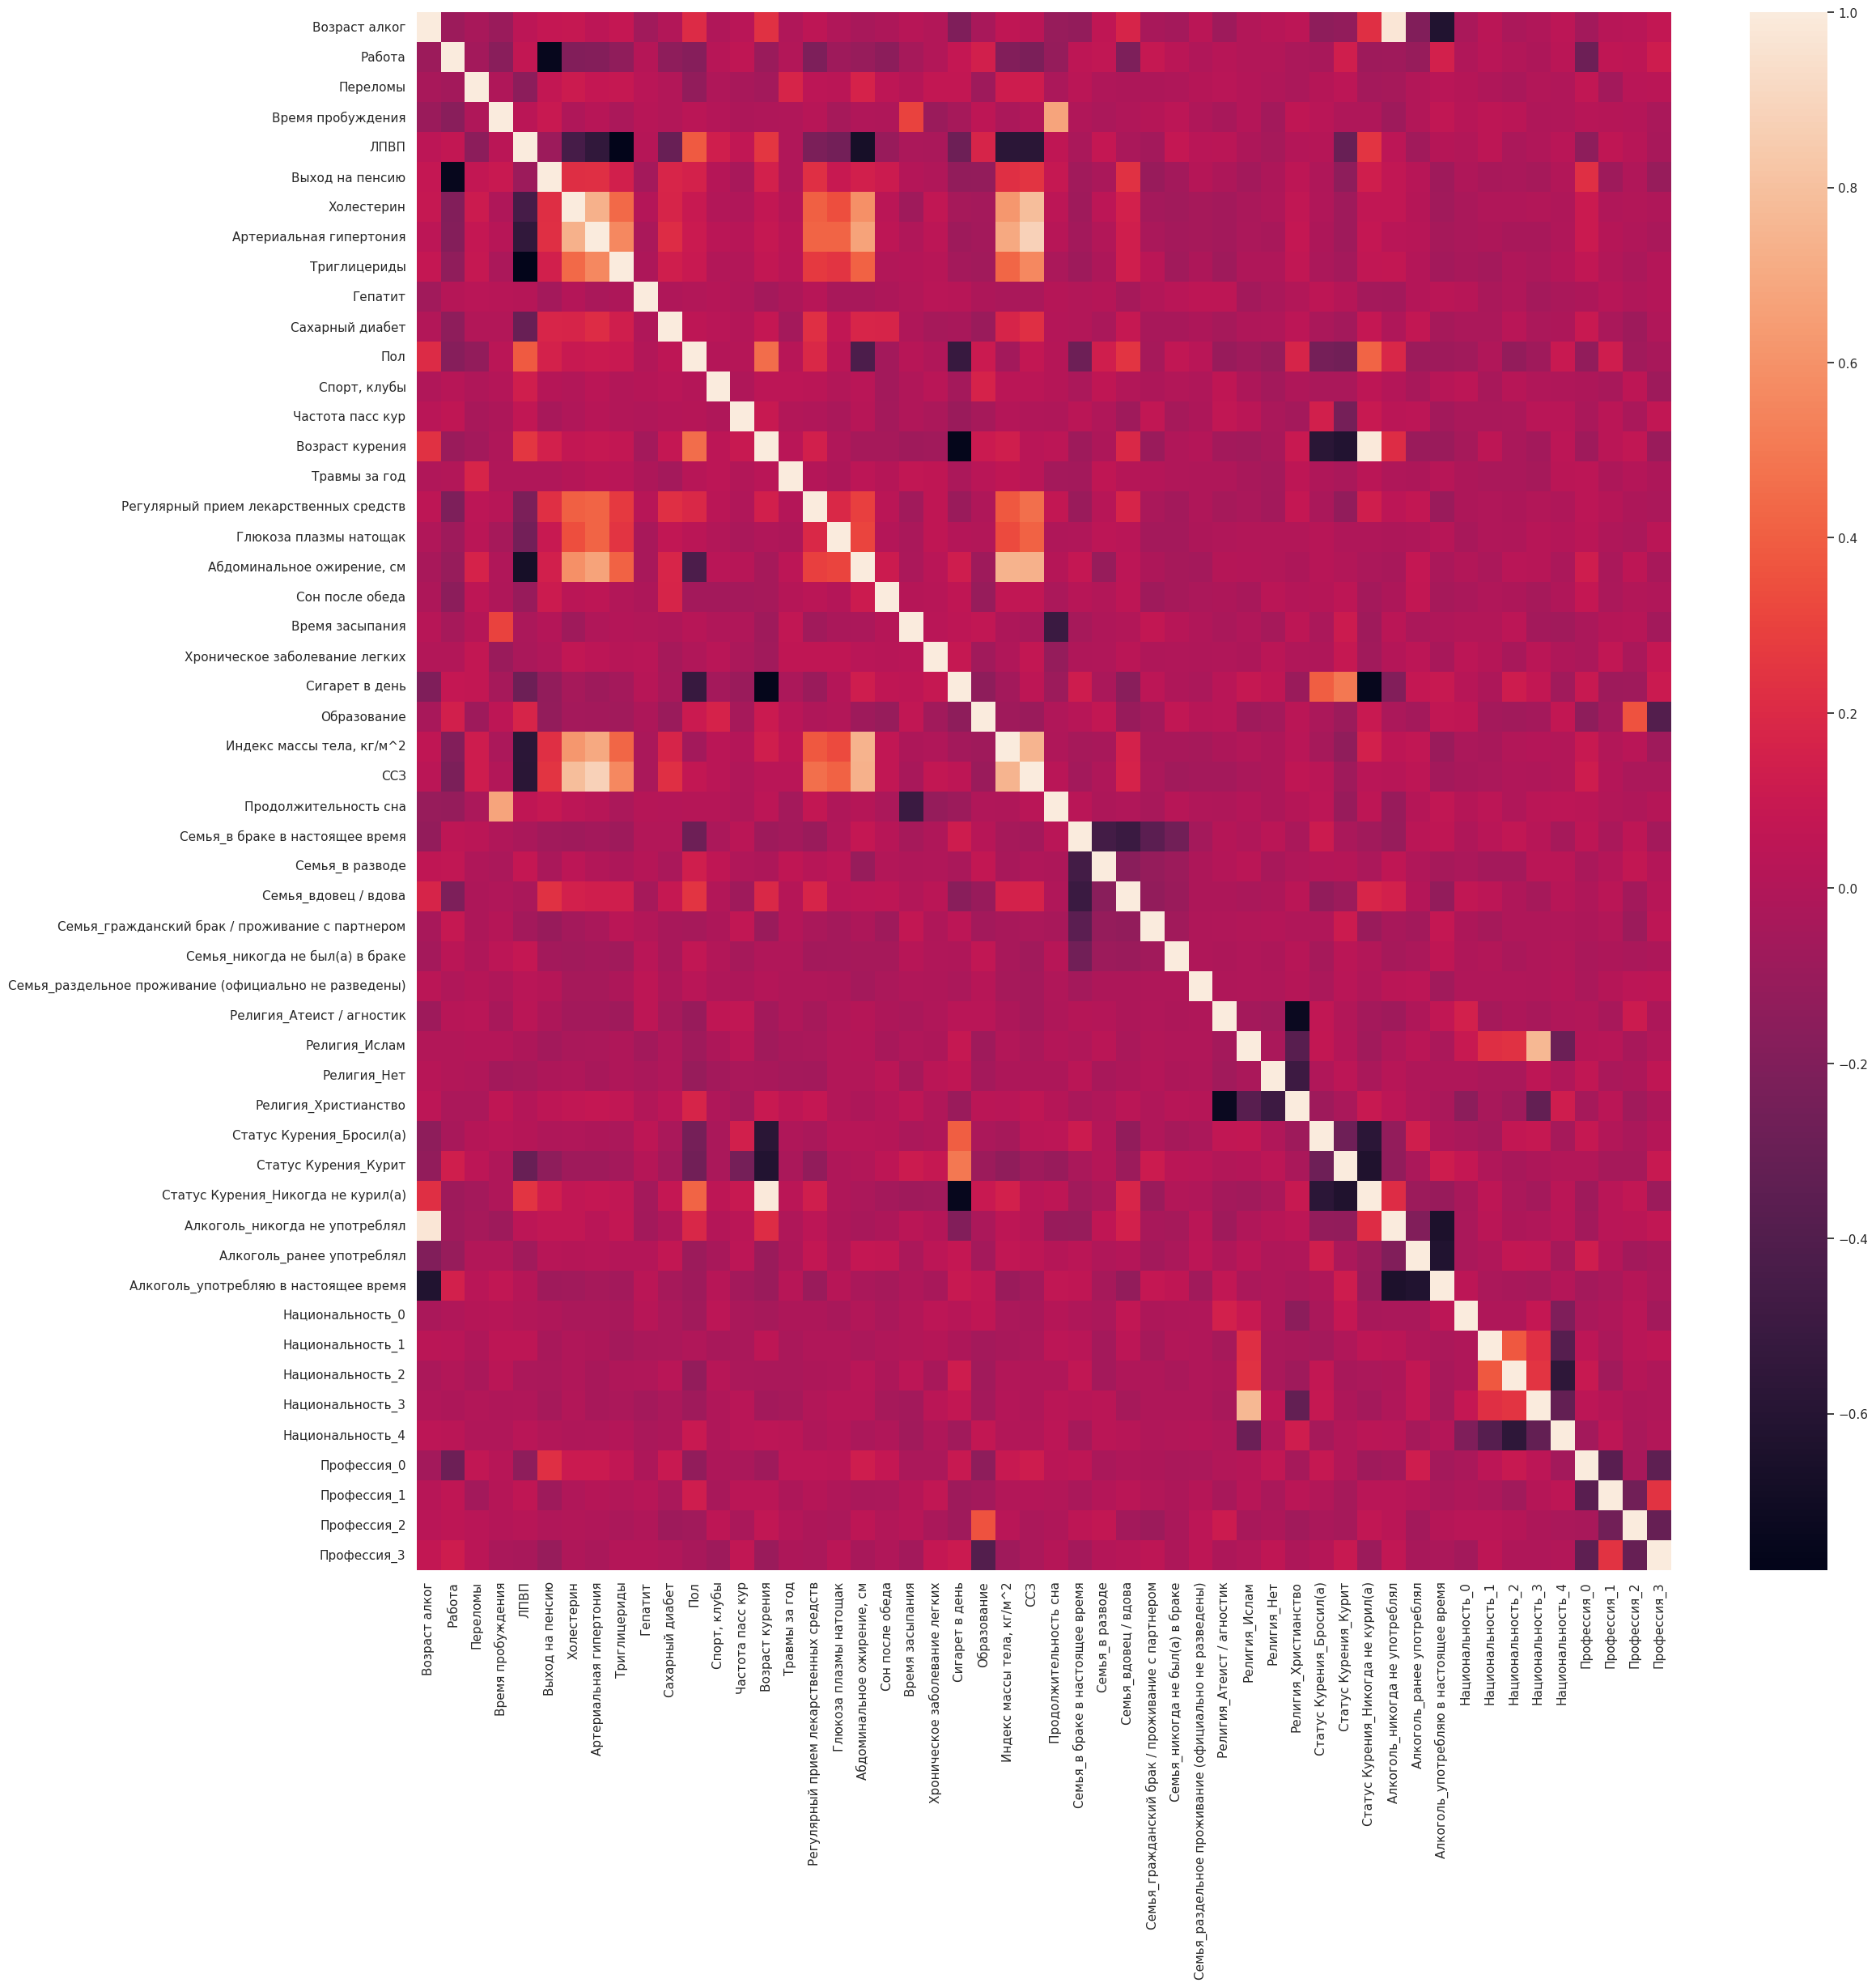

In [ ]:
sns.heatmap(heart.corr(numeric_only=True));

In [ ]:
corr = heart.corr(numeric_only=True)
m = (corr.mask(np.eye(len(corr), dtype=bool)).abs() > 0.8).any()
raw = corr.loc[m, m]
raw

,Возраст алког,Артериальная гипертония,Возраст курения,ССЗ,Статус Курения_Никогда не курил(а),Алкоголь_никогда не употреблял
Возраст алког,1.000000,0.043672,0.233508,0.036049,0.224185,0.977351
Артериальная гипертония,0.043672,1.000000,0.082982,0.880934,0.081750,0.032526
Возраст курения,0.233508,0.082982,1.000000,0.031527,0.988495,0.212377
ССЗ,0.036049,0.880934,0.031527,1.000000,0.029907,0.025340
Статус Курения_Никогда не курил(а),0.224185,0.081750,0.988495,0.029907,1.000000,0.209242
Алкоголь_никогда не употреблял,0.977351,0.032526,0.212377,0.025340,0.209242,1.000000


In [ ]:
heart.drop(columns=['Статус Курения_Никогда не курил(а)', 'Алкоголь_никогда не употреблял'], axis=1, inplace=True)

In [ ]:
heart.to_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart4.csv', index=False)

# СТАТИСТИЧЕСКИЙ АНАЛИЗ ДАННЫХ

In [ ]:
from scipy import stats
from scipy.stats import norm #загружаем график нормального распределения
import scipy.stats as scs
import statsmodels.stats.diagnostic as sm
import statsmodels.api as sml # для Q-Q plot
from statsmodels import stats as sms
from scipy.stats import shapiro
from scipy.stats import bartlett
from scipy.stats import ttest_1samp
from scipy.stats import ttest_rel

In [ ]:
! pip install scikit-posthocs
import scikit_posthocs as sp

In [ ]:
! pip install pingouin
import pingouin as pg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.4/204.4 kB 4.9 MB/s eta 0:00:00


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart1.csv')

In [ ]:
df.head().T

,0,1,2,3,4
Возраст алког,18.0,90.0,17.0,13.0,16.0
Работа,1,0,0,1,0
Статус Курения,Курит,Никогда не курил(а),Никогда не курил(а),Бросил(а),Никогда не курил(а)
Переломы,0,1,0,0,1
Время пробуждения,6,4,7,7,6
ЛПВП,0.97,0.74,1.57,0.68,1.01
Выход на пенсию,0,0,0,0,0
Холестерин,4.0,8.6,5.2,4.9,8.2
Артериальная гипертония,0,0,0,1,1
Триглицериды,0.52,2.73,1.02,3.25,1.25


##**Гипотеза 1:** о влиянии признака Глюкозы плазмы натощак на риск развития ССЗ


H₀: нет статистически значимых отличий признака Глюкоза плазмы натощак у пациентов с ССЗ и без ССЗ

H₁: Глюкоза плазмы натощак у пациентов с ССЗ и пациентов без ССЗ имеют статистически значимые отличия

### Проверка данных на нормальность

Визуализация распределения

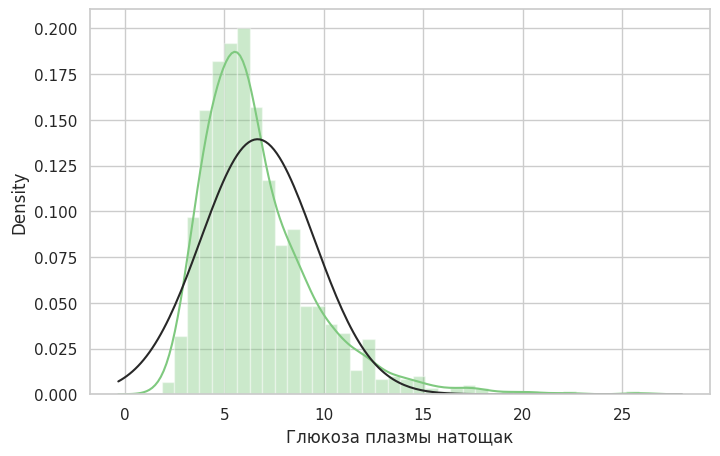

In [ ]:
plt.figure(figsize=(8, 5))
sns.distplot(df['Глюкоза плазмы натощак'], fit=norm);

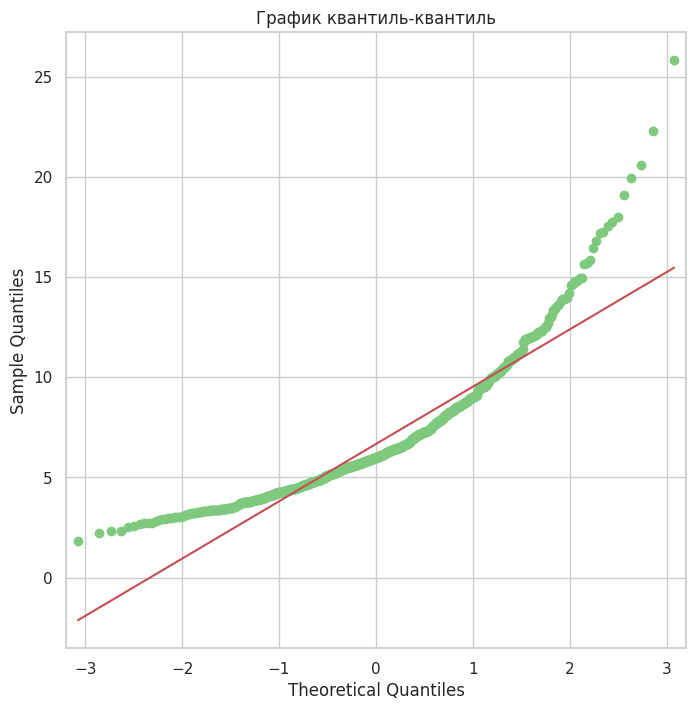

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
sml.qqplot(df['Глюкоза плазмы натощак'], line='s', ax=ax)
plt.title('График квантиль-квантиль')
plt.show()

In [ ]:
# Проведение теста Шапиро-Уилка для проверки на нормальность данных
statistic, p_value = shapiro(df['Глюкоза плазмы натощак'])

# Вывод результатов
print("Значение статистики теста Шапиро-Уилка:", statistic)
print("p-value:", p_value)

alpha = 0.05
if p_value > alpha:
    print("Данные распределены примерно нормально")
else:
    print("Данные НЕ распределены нормально")

Значение статистики теста Шапиро-Уилка: 0.8744168807681093
p-value: 5.9198682717025125e-27
Данные НЕ распределены нормально


In [ ]:
# Проведение теста Лилиефорса для проверки на нормальность признака Рост
statistic, p_value = sm.lilliefors(df['Глюкоза плазмы натощак'])

# Вывод результатов
print("Значение статистики теста Лилиефорса:", statistic)
print("p-value:", p_value)

alpha = 0.05
if p_value > alpha:
    print("Данные распределены примерно нормально")
else:
    print("Данные НЕ распределены нормально")

Значение статистики теста Лилиефорса: 0.12665413927303437
p-value: 0.0009999999999998899
Данные НЕ распределены нормально


**Вывод:** Данные Глюкозы плазмы натощак не распределены нормально

### Критерий Манна–Уитни

In [ ]:
g0 = df.loc[df['ССЗ'] == 0, 'Глюкоза плазмы натощак'].dropna().values
g1 = df.loc[df['ССЗ'] == 1, 'Глюкоза плазмы натощак'].dropna().values

u_stat, p_val = stats.mannwhitneyu(g0, g1, alternative='two-sided')

# Вывод результатов
print("Значение t-статистики:", u_stat)
print("Значение p-value:", p_val)

if p_val < 0.05:
    print("Различия между группами статистически значимы")
else:
    print("Статистически значимых различий между группами не выявлено")

Значение t-статистики: 55918.0
Значение p-value: 6.100175336301761e-40
Различия между группами статистически значимы


**Вывод:** p ≤ 0.05, следовательно распределение значений **глюкозы плазмы натощак** у людей с **ССЗ** статистически значимо отличается от значений у людей без ССЗ.

##**Гипотеза 2:** о влиянии признака Абдоминальное ожирение, см на риск развития ССЗ


H₀: нет статистически значимых отличий признака Абдоминальное ожирение, см у пациентов с ССЗ и без ССЗ

H₁: Абдоминальное ожирение, см у пациентов с ССЗ и пациентов без ССЗ имеют статистически значимые отличия

### Проверка данных на нормальность

Визуализация распределения

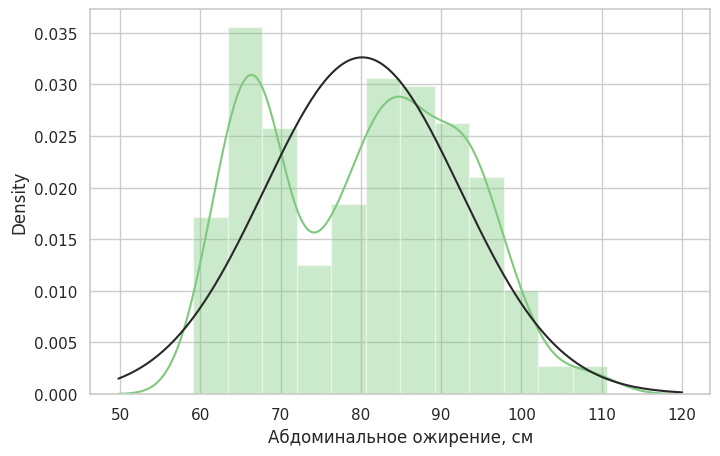

In [ ]:
plt.figure(figsize=(8, 5))
sns.distplot(df['Абдоминальное ожирение, см'], fit=norm);

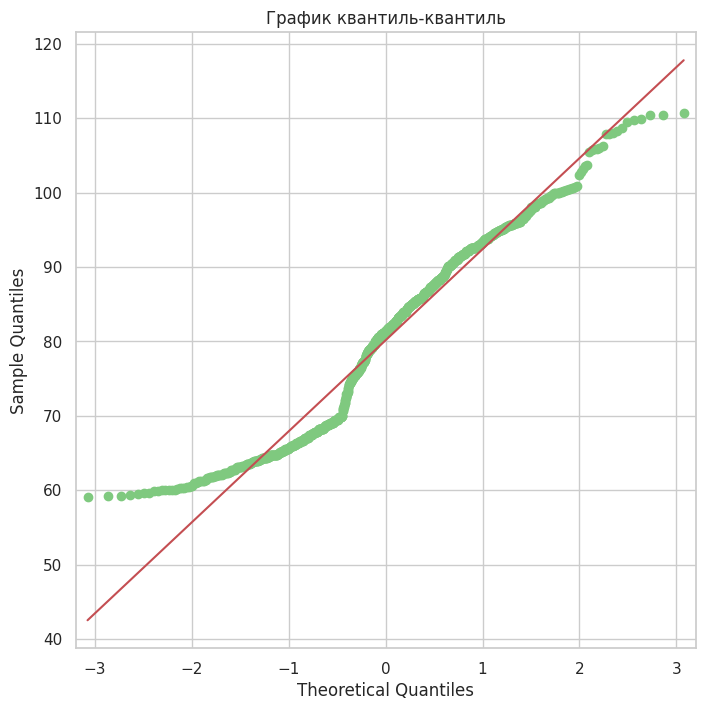

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
sml.qqplot(df['Абдоминальное ожирение, см'], line='s',ax=ax)
plt.title('График квантиль-квантиль')
plt.show()

In [ ]:
# Проведение теста Шапиро-Уилка для проверки на нормальность данных
statistic, p_value = shapiro(df['Абдоминальное ожирение, см'])

# Вывод результатов
print("Значение статистики теста Шапиро-Уилка:", statistic)
print("p-value:", p_value)

alpha = 0.05
if p_value > alpha:
    print("Данные распределены примерно нормально")
else:
    print("Данные НЕ распределены нормально")

Значение статистики теста Шапиро-Уилка: 0.9575201432286891
p-value: 5.855896498707604e-16
Данные НЕ распределены нормально


In [ ]:
# Проведение теста Лилиефорса для проверки на нормальность признака Рост
statistic, p_value = sm.lilliefors(df['Абдоминальное ожирение, см'])

# Вывод результатов
print("Значение статистики теста Лилиефорса:", statistic)
print("p-value:", p_value)

alpha = 0.05
if p_value > alpha:
    print("Данные распределены примерно нормально")
else:
    print("Данные НЕ распределены нормально")

Значение статистики теста Лилиефорса: 0.12462539434167974
p-value: 0.0009999999999998899
Данные НЕ распределены нормально


**Вывод:** Данные Абдоминальное ожирение, см не распределены нормально

### Критерий Манна–Уитни

In [ ]:
g0 = df.loc[df['ССЗ'] == 0, 'Абдоминальное ожирение, см'].dropna().values
g1 = df.loc[df['ССЗ'] == 1, 'Абдоминальное ожирение, см'].dropna().values

u_stat, p_val = stats.mannwhitneyu(g0, g1, alternative='two-sided')

# Вывод результатов
print("Значение t-статистики:", u_stat)
print("Значение p-value:", p_val)

if p_val < 0.05:
    print("Различия между группами статистически значимы")
else:
    print("Статистически значимых различий между группами не выявлено")

Значение t-статистики: 16352.5
Значение p-value: 1.5860684688503753e-113
Различия между группами статистически значимы


**Вывод:** p ≤ 0.05, следовательно распределение значений **Абдоминальное ожирение, см** у людей с **ССЗ** статистически значимо отличается от значений у людей без ССЗ.

## **Гипотеза 3** о влиянии сахарного диабета на риск развития ССЗ


H₀: Наличие сахарного диабета не влияет на развитие сердечно-сосудистого заболевания

H₁: Пациенты с сахарным диабетом имеют повышенный риск развития сердечно-сосудистого заболевания

### Таблица сопряжённости

In [ ]:
# составляем таблицу сопряжённости
cross_table = pd.crosstab(df['Сахарный диабет'], df['ССЗ'])

cross_table

ССЗ,0,1
Сахарный диабет,,
0,416,433
1,12,88


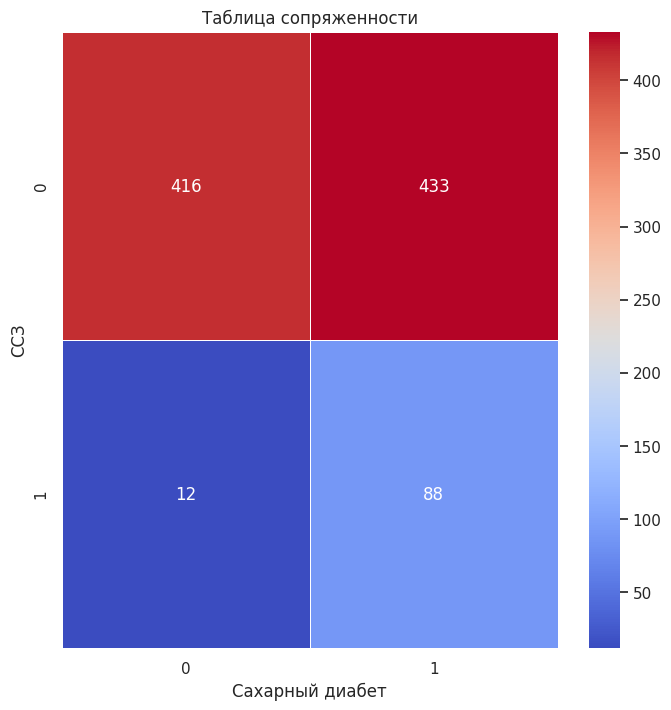

In [ ]:
#таблица сопряжённости
fig, ax = plt.subplots(figsize=(8, 8))
cross_tab = pd.crosstab(index=df['Сахарный диабет'], columns=df['ССЗ'])
ax = sns.heatmap(cross_tab, annot=True, linewidth=.5, fmt='.0f', cmap="coolwarm", ax=ax)
ax.set(xlabel='Сахарный диабет', ylabel='ССЗ')
plt.title('Таблица сопряженности')
plt.show()

Согласно данным, среди людей с ССЗ имеющих Сахарный диабет больше, чем не имеющих.

### Хи-квадрат тест.

In [ ]:
# проводим тест
_, p, _, _ = stats.chi2_contingency(cross_table)
print("Уровень значимости alpha = {:.2f}".format(p))
if p < 0.05:
    print("Различия между группами статистически значимы")
else:
    print("Статистически значимых различий между группами не выявлено")

Уровень значимости alpha = 0.00
Различия между группами статистически значимы


**Вывод:** p ≤ 0.05, связь между наличием ССЗ и Сахарного диабета не случайна, различия между группами статистически значимы.

# МАШИННОЕ ОБУЧЕНИЕ

In [ ]:
from sklearn.linear_model import LogisticRegression    # Импорт модели логистической регрессии
from sklearn.neighbors import KNeighborsClassifier     # Импорт классификатора K-ближайших соседей
from sklearn.tree import DecisionTreeClassifier        # Импорт классификатора на основе дерева решений
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn import metrics      # Импорт всего модуля metrics для работы с метриками оценки моделей
from sklearn.metrics import  (    # Импорт конкретных функций оценки из подмодуля metrics
    accuracy_score,              # Импорт функции для оценки точности (accuracy) модели, т.е. доли правильно предсказанных примеров
    balanced_accuracy_score,     # Импорт функции для оценки сбалансированной точности, учитывающей классовую неоднородность
    precision_score,             # Импорт функции для вычисления точности (precision)
    recall_score,                # Импорт функции для вычисления полноты (recall)
    confusion_matrix,            # Импорт функции для создания матрицы ошибок (confusion matrix):TN, TP, FN, FP
    multilabel_confusion_matrix, # Импорт функции для создания матрицы ошибок для случаев с многомерной классификацией
    f1_score,                    # Импорт функции для вычисления F1-меры
    roc_auc_score,               # Импорт функции для вычисления AUC-ROC (площадь под кривой приемлемости и ошибок)
    roc_curve,                   # Импорт функции для вычисления координат для построения ROC-кривой
    average_precision_score,     # Импорт функции для вычисления средней точности (average precision)
    precision_recall_curve       # Импорт функции для вычисления и визуализации кривой "точность-полнота" (precision-recall curve)
)

In [ ]:
heart_new=pd.read_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart2.csv')

* Разобьём датасет на данные для обучения и тестирования методом **train_test_split** библиотеки **Scikit-learn**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    heart_new.drop("ССЗ", axis=1),
    heart_new["ССЗ"],
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=heart_new["ССЗ"]
)

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((759, 69), (190, 69), (759,), (190,))

* Создадим **функцию вычисления специфичности** (готовой реализации нет)


In [ ]:
def calculate_specificity(true_labels, predictions):
    """Вычисление специфичности для бинарной и многоклассовой классификации
  Аргументы функции:
    true_labels: истинные метки классов
    predictions: предсказанные метки классов
  Результат:
    специфичность и confusion_matrix
    """
    conf_matrix = confusion_matrix(true_labels, predictions)
    tn, fp, fn, tp = conf_matrix.ravel()
    specif = (tn / (tn + fp)).round(4)
    return specif, (tn, fp, fn, tp)

* Поместим вычисление нескольких метрик  в отдельную функцию:

In [ ]:
  def get_all_metrics(
    true_labels,
    predictions,
    probabilities,
    print_metrics=False,
    **kwargs
):
    """Подсчёт и вывод всех метрик
  Аргументы функции:
    true_labels: истинные метки классов
    predictions: предсказания (метки классов)
    probabilities: предсказания (вероятности принадлежности каждого объекта к каждому классу)
    print_metrics: если True, то печатает получившиеся метрики
    **kwargs: специальный синтаксис для сборки всех дополнительных именованных аргументов в один словарь
  Возвращает:
    словарь, ключи которого -- названия метрик точности, значения - значения метрик точности
    """

    kwargs_roc_auc = dict()

    """
    Создается пустой словарь, в который будут добавлены дополнительные параметры для анализа, связанного
    с ROC  кривой и площадью под ней
    """
    probabilities = probabilities[:, 1]

    """
   извлекает вероятности для позитивного класса (второго столбца) из массива предсказаний probabilities
    """

    accuracy = accuracy_score(true_labels, predictions)
    balanced_accuracy=balanced_accuracy_score(true_labels, predictions)
    precision = precision_score(true_labels, predictions)
    recall = recall_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions)

    roc_auc = roc_auc_score(true_labels, probabilities,**kwargs_roc_auc)
    pr_auc = average_precision_score(true_labels, predictions)

    specificity, conf_matrix = calculate_specificity(true_labels, predictions)


    tn, fp, fn, tp = conf_matrix

    print(
            "Accuracy = {:.4f}\nBalanced_accuracy = {:.4f}\nPrecision = {:.4f}\nRecall = {:.4f}\nF1_score = {:.4f}\nROC AUC = {:.4f}\nPR AUC = {:.4f}\nSpecificity = {:.4f}".format(
                accuracy, balanced_accuracy, precision, recall, f1, roc_auc, pr_auc, specificity
            )
        )


    return {
        "Accuracy": accuracy,
        "Balanced accuracy": balanced_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1,
        "ROC AUC": roc_auc,
        "PR AUC": pr_auc,
        "Specificity": specificity
    }

Поскольку необходимо сравнивать несколько моделей, напишем отдельную функцию для обучения и тестирования модели. Также эта функция будет вычислять и все указанные выше метрики.

In [ ]:
def model_train_test(X_train, y_train, X_test, y_test, model, **kwargs):
    """Обучение и тестирование модели на обучающей и тестовой выборке соответственно.
    Аргументы функции:
    X_train: объекты обучающей выборки
    y_train: значения целевой переменной обучающей выборки
    X_test: объекты тестовой выборки
    y_test: значения целевой переменной тестовой выборки
    model: модель, которая обучается и тестируется
    Функция возвращает предсказания - классы и вероятности принадлежности к каждому классу, все метрики
    """
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    """
    Метод predict используется для получения окончательных предсказаний класса для данного набора данных.
    Возвращает классы (метки) для объектов, исходя из решения модели. Для бинарной классификации возможные значения могут быть 0 или 1
    """
    if isinstance(model, LogisticRegression):
        importance = model.coef_[0]
    elif isinstance(model, DecisionTreeClassifier):
        importance = model.feature_importances_
    else:
         importance = None
    """
    Функция isinstance() в Python проверяет, является ли объект экземпляром указанного класса или кортежа классов.
    Возвращает True, если объект соответствует заданному типу, и False в противном случае.
    В нашем случае -это проверка, является ли объект model экземпляром класса LogisticRegression или DecisionTreeClassifier
    Логистическая регрессия:
    classifier.coef_ - атрибут модели, который содержит коэффициенты (веса) перед каждым признаком.
    Индекс [0] в classifier.coef_[0] используется для доступа к коэффициентам первого класса.
    Следовательно, код importance = classifier.coef_[0] присваивает переменной importance массив коэффициентов,
    которые модель использует для принятия решений о принадлежности нового наблюдения к первому классу.
    """
    print(str(model), end="\n\n")

    all_metrics = get_all_metrics(
        y_test,
        pred,
        proba,
        print_metrics=True,
        **kwargs,
    )
    return pred, proba, importance, all_metrics

## Сравнение алгоритмов

Перейдем к непосредственному сравнению моделей. В задаче бинарной классификации будем сравнивать логистическую регрессию, решающее дерево, метод k-ближайших соседей.  

In [ ]:
pred_logreg, proba_logreg, importance_logreg, all_metrics_logreg = model_train_test(
    X_train, y_train.values,
    X_test, y_test.values,
    LogisticRegression(random_state=42, max_iter=1000)
)

LogisticRegression(max_iter=1000, random_state=42)

Accuracy = 0.9947
Balanced_accuracy = 0.9952
Precision = 1.0000
Recall = 0.9904
F1_score = 0.9952
ROC AUC = 1.0000
PR AUC = 0.9956
Specificity = 1.0000


In [ ]:
pred_dt, proba_dt, importance_dt, all_metrics_dt = model_train_test(
    X_train, y_train.values,
    X_test, y_test.values,
    DecisionTreeClassifier(random_state=42)
)

DecisionTreeClassifier(random_state=42)

Accuracy = 0.9895
Balanced_accuracy = 0.9894
Precision = 0.9904
Recall = 0.9904
F1_score = 0.9904
ROC AUC = 0.9894
PR AUC = 0.9861
Specificity = 0.9884


In [ ]:
pred_knn, proba_knn, importance_knn, all_metrics_knn = model_train_test(
    X_train, y_train.values,
    X_test, y_test.values,
    KNeighborsClassifier()
)

KNeighborsClassifier()

Accuracy = 0.9368
Balanced_accuracy = 0.9403
Precision = 0.9792
Recall = 0.9038
F1_score = 0.9400
ROC AUC = 0.9770
PR AUC = 0.9376
Specificity = 0.9767


## Матрицы ошибок

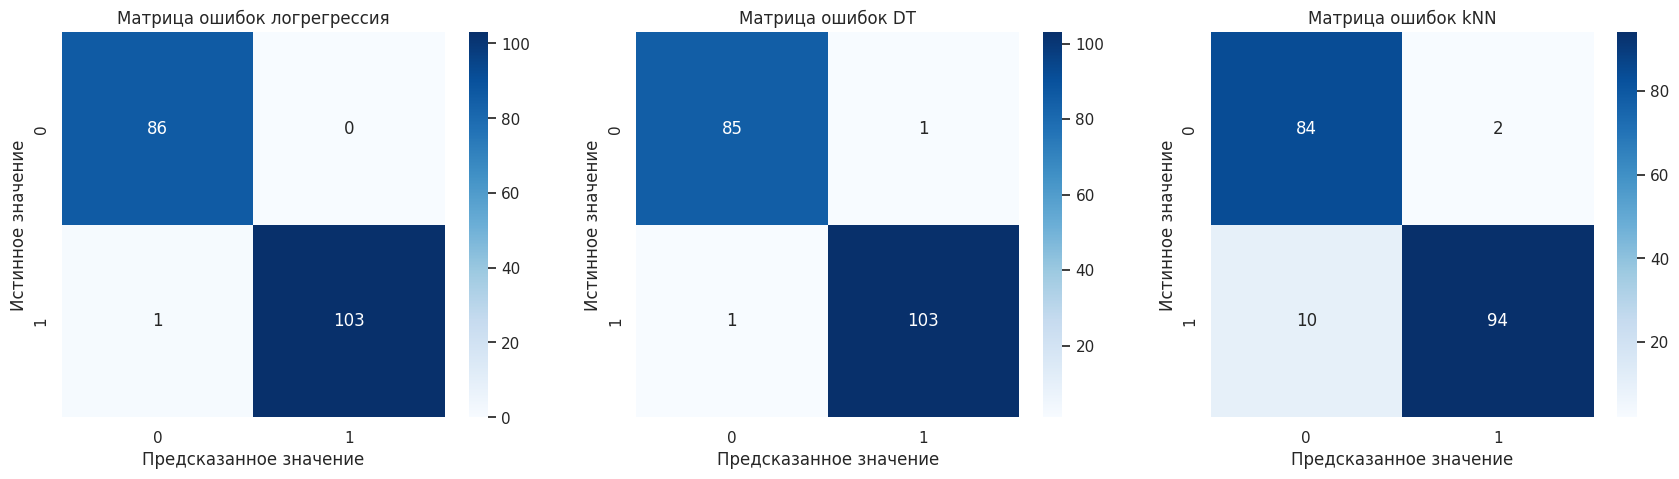

In [ ]:
#Строим матрицу ошибок для модели
confus_matrix = metrics.confusion_matrix(y_test, pred_logreg)
confus_matrix1 = metrics.confusion_matrix(y_test, pred_dt)
confus_matrix2 = metrics.confusion_matrix(y_test, pred_knn)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
sns.heatmap(confus_matrix, annot=True, fmt='', cmap='Blues', ax=axes[0])
axes[0].set_title('Матрица ошибок логрегрессия')
axes[0].set_xlabel('Предсказанное значение')
axes[0].set_ylabel('Истинное значение')

sns.heatmap(confus_matrix1, annot=True, fmt='', cmap='Blues', ax=axes[1])
axes[1].set_title('Матрица ошибок DT')
axes[1].set_xlabel('Предсказанное значение')
axes[1].set_ylabel('Истинное значение')

sns.heatmap(confus_matrix2, annot=True, fmt='', cmap='Blues', ax=axes[2])
axes[2].set_title('Матрица ошибок kNN')
axes[2].set_xlabel('Предсказанное значение')
axes[2].set_ylabel('Истинное значение');

* Сравним не только ROC AUC и PR AUC, но и ROC- и PR-кривые. Для их визуализации будем использовать функцию, приведенную ниже:

In [ ]:
def plot_roc_pr_curves(true_labels, algorithms):
    """Отрисовка ROC- и PR-кривых.
    Аргументы функции:
    true_labels: истинные метки классов
    algorithms: словарь формата {название_алгоритма: вероятности_принадлежности_к_каждому_классу}
    """
    fig, ax = plt.subplots(1, 2, figsize=(20, 8))
    ax[0].set_title("ROC-кривая", fontsize=20)
    ax[1].set_title("PR-кривая", fontsize=20)

    for alg_name, probabilities in algorithms.items():
        fpr, tpr, _ = roc_curve(true_labels, probabilities[:, 1])
        precisions, recalls, _ = precision_recall_curve(true_labels, probabilities[:, 1])

        ax[0].plot(
            fpr,
            tpr,
            label="{} (ROC AUC = {})".format(
                alg_name,
                round(
                    roc_auc_score(true_labels, probabilities[:, 1]),
                    3
                )
            )
        )
        ax[1].plot(
            recalls,
            precisions,
            label="{} (PR AUC = {})".format(
                alg_name,
                round(
                    average_precision_score(true_labels, probabilities[:, 1]),
                    3
                )
            )
        )

    ax[0].legend(fontsize=14)
    ax[0].set_xlabel("Ложноположительные", fontsize=16)
    ax[0].set_ylabel("Истинно положительные", fontsize=16)

    ax[1].legend(fontsize=14)
    ax[1].set_xlabel("Recall", fontsize=16)
    ax[1].set_ylabel("Precision", fontsize=16)
    plt.show()

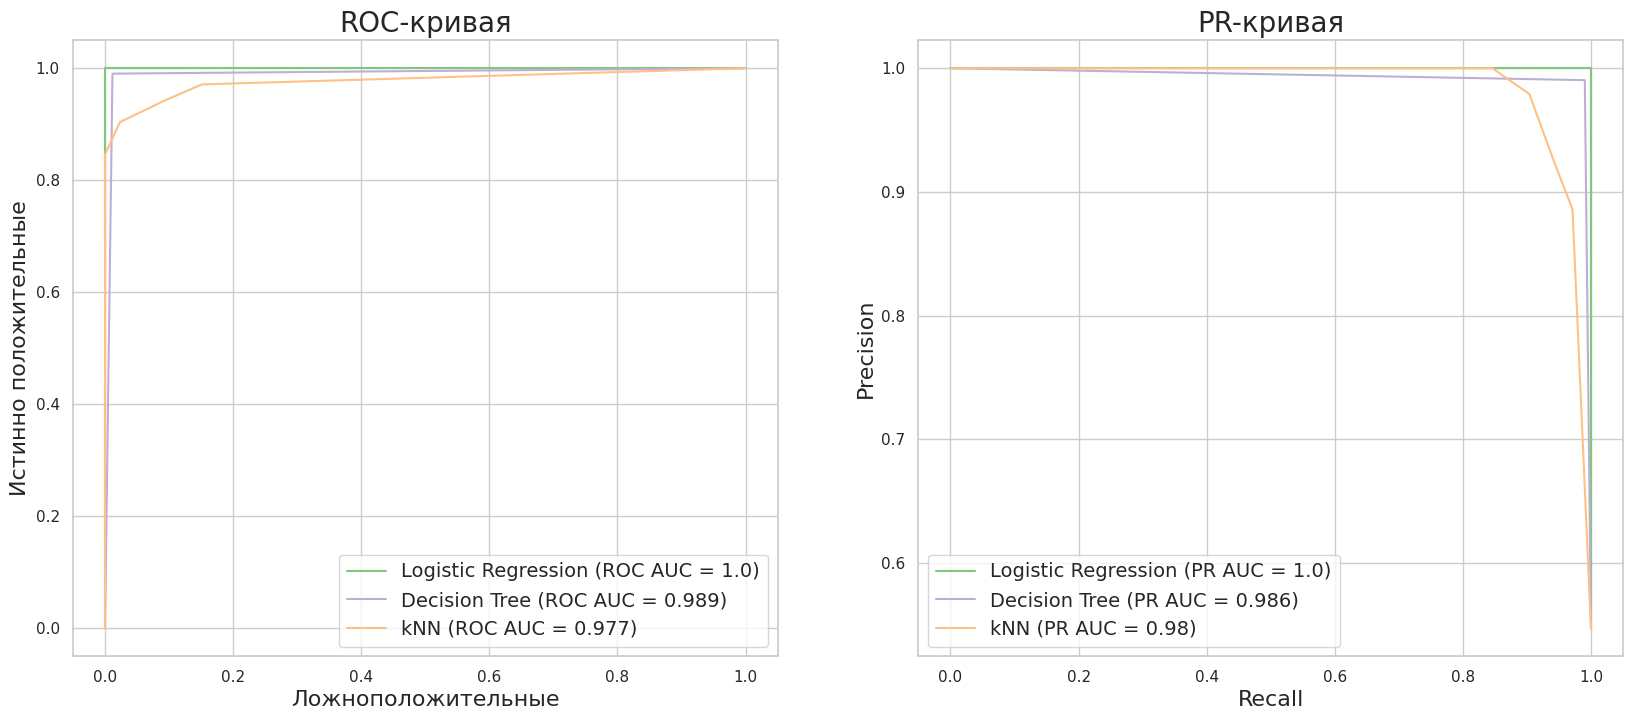

In [ ]:
plot_roc_pr_curves(
    y_test,
    {
        "Logistic Regression": proba_logreg,
        "Decision Tree": proba_dt,
        "kNN": proba_knn,
    }
)

* Сагрегируем все метрики моделей

In [ ]:
ans_df = pd.DataFrame(
    [all_metrics_logreg, all_metrics_dt, all_metrics_knn],
    index=["Logistic Regression", "Decision Tree", "kNN"]
)
ans_df

,Accuracy,Balanced accuracy,Precision,Recall,F1_score,ROC AUC,PR AUC,Specificity
Logistic Regression,0.994737,0.995192,1.000000,0.990385,0.995169,1.000000,0.995648,1.0000
Decision Tree,0.989474,0.989378,0.990385,0.990385,0.990385,0.989378,0.986125,0.9884
kNN,0.936842,0.940295,0.979167,0.903846,0.940000,0.976968,0.937648,0.9767


* Для каждой метрики выведем список моделей по убыванию их качества

In [ ]:
for metric in ans_df.columns:
    sorted_ans_df = ans_df.sort_values(by=metric, ascending=False)
    print(
        "{}:{}{}".format(
            metric,
            " " * (20 - len(metric)),
            sorted_ans_df.index.tolist()
        )
    )

Accuracy:            ['Logistic Regression', 'Decision Tree', 'kNN']
Balanced accuracy:   ['Logistic Regression', 'Decision Tree', 'kNN']
Precision:           ['Logistic Regression', 'Decision Tree', 'kNN']
Recall:              ['Logistic Regression', 'Decision Tree', 'kNN']
F1_score:            ['Logistic Regression', 'Decision Tree', 'kNN']
ROC AUC:             ['Logistic Regression', 'Decision Tree', 'kNN']
PR AUC:              ['Logistic Regression', 'Decision Tree', 'kNN']
Specificity:         ['Logistic Regression', 'Decision Tree', 'kNN']


Согласно всем метрикам наилучшим алгоритмом оказалась логистическая регрессия.

##Подбор гиперпараметров с последующей оценкой

In [ ]:
# 1. БАЗОВАЯ МОДЕЛЬ (до оптимизации)

raw_table_data = pd.read_csv('/content/drive/MyDrive/Итоговый проект/Данные/heart2.csv')
X = raw_table_data.drop(['ССЗ'], axis=1)
y = raw_table_data['ССЗ'].values
raw_table_data_columns = X.columns
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Отбор признаков: SelectKBest с f_classif, k = 10 (можно подобрать, но для примера — 10)
selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)
model = LogisticRegression(C=0.0001, penalty='l2',solver='liblinear',class_weight=None,random_state=42, max_iter=1000)
model.fit(X_train_selected, y_train)

y_pred_base = model.predict(X_test_selected)
y_proba_base = model.predict_proba(X_test_selected)
print("\n--- Метрики ДО оптимизации ---")
metrics_before = get_all_metrics(y_test, y_pred_base, y_proba_base,
                 print_metrics=True, average='binary')


# 2. ОПТИМИЗАЦИЯ ГИПЕРПАРАМЕТРОВ
param_grid = {'C': [0.005, 0.001, 0.1, 0.5, 1, 5, 10, 50, 100],'penalty': ['l1', 'l2'],
             'solver': ['liblinear', 'saga']}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000),
    param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid_search.fit(X_train_selected, y_train)

# 3. МЕТРИКИ ПОСЛЕ ОПТИМИЗАЦИИ
print("\n--- Метрики ПОСЛЕ оптимизации ---")
best_model = grid_search.best_estimator_
y_pred_opt = best_model.predict(X_test_selected)
y_proba_opt = best_model.predict_proba(X_test_selected)

metrics_after = get_all_metrics(y_test, y_pred_opt, y_proba_opt,
                print_metrics=True)


# 4. СРАВНЕНИЕ (опционально красиво)
print("\n" + "="*50)
print("СРАВНЕНИЕ МЕТРИК: ДО → ПОСЛЕ")
print("="*50)
for metric in metrics_before:
    before = metrics_before[metric]
    after = metrics_after[metric]
    sign = "↑" if after > before else "↓" if after < before else "="
    print(f"{metric:<20}: {before:.4f} → {after:.4f} {sign}")


--- Метрики ДО оптимизации ---
Accuracy = 0.9842
Balanced_accuracy = 0.9856
Precision = 1.0000
Recall = 0.9712
F1_score = 0.9854
ROC AUC = 0.9959
PR AUC = 0.9869
Specificity = 1.0000

--- Метрики ПОСЛЕ оптимизации ---
Accuracy = 0.9895
Balanced_accuracy = 0.9904
Precision = 1.0000
Recall = 0.9808
F1_score = 0.9903
ROC AUC = 0.9956
PR AUC = 0.9913
Specificity = 1.0000

СРАВНЕНИЕ МЕТРИК: ДО → ПОСЛЕ
Accuracy            : 0.9842 → 0.9895 ↑
Balanced accuracy   : 0.9856 → 0.9904 ↑
Precision           : 1.0000 → 1.0000 =
Recall              : 0.9712 → 0.9808 ↑
F1_score            : 0.9854 → 0.9903 ↑
ROC AUC             : 0.9959 → 0.9956 ↓
PR AUC              : 0.9869 → 0.9913 ↑
Specificity         : 1.0000 → 1.0000 =


## Вклад признаков в предсказание

* Метод, который упорядочивает и визуализирует коэффициенты регрессии для каждого признака

In [ ]:
def plot_imp(ssz, importance):
    order = np.argsort(importance)
    ssz = ssz[order]
    importance = importance[order]

    for idx, val in enumerate(importance):
        print(f'{ssz[idx]:40} {val:.4f}')
    plt.figure(figsize=(4, np.ceil(len(ssz) / 4)))

    plt.barh(ssz, importance)
    plt.show()

In [ ]:
heart_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 70 columns):
 #   Column                                                                                         Non-Null Count  Dtype  
---  ------                                                                                         --------------  -----  
 0   Возраст алког                                                                                  949 non-null    float64
 1   Работа                                                                                         949 non-null    int64  
 2   Переломы                                                                                       949 non-null    int64  
 3   Время пробуждения                                                                              949 non-null    int64  
 4   ЛПВП                                                                                           949 non-null    float64
 5   Выход на пенсию       

In [ ]:
heart_new.drop("ССЗ", axis=1, inplace=True)

Гепатит                                  -0.6610
Образование                              -0.5114
Семья_в браке в настоящее время          -0.3834
Религия_Христианство                     -0.3521
Профессия_квалифицированные работники сельского хозяйства и рыболовного -0.2916
Статус Курения_Курит                     -0.2811
Алкоголь_ранее употреблял                -0.2660
Сон после обеда                          -0.2149
Профессия_низкоквалифицированные работники -0.2097
Работа                                   -0.2047
Травмы за год                            -0.1716
Религия_Ислам                            -0.1526
Профессия_техники и младшие специалисты  -0.1456
Профессия_операторы и монтажники установок и машинного оборудования -0.1428
Национальность_Татары                    -0.0831
Частота пасс кур                         -0.0709
Национальность_Немцы                     -0.0671
Национальность_Азербайджанцы             -0.0290
Национальность_Другие национальности     -0.0214
Профессия

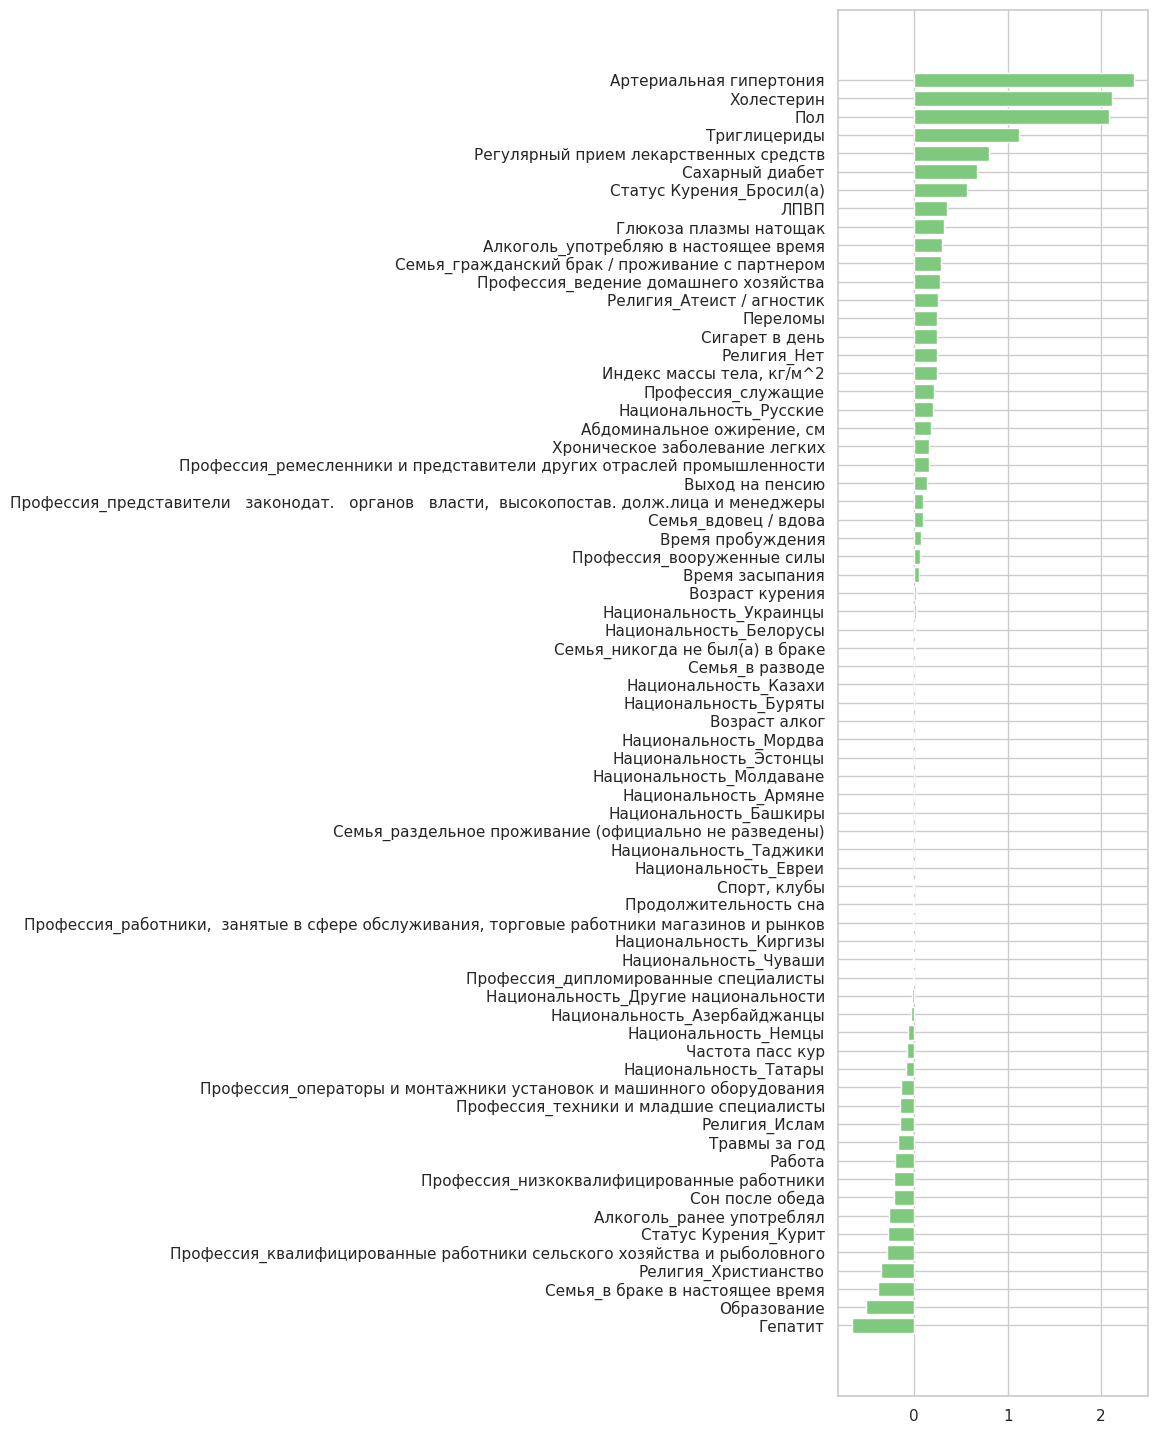

In [ ]:
ssz = heart_new.columns
plot_imp(ssz, importance_logreg)

* Выведем абсолютный вклад признаков в предсказание

Национальность_Молдаване                 0.0000
Национальность_Эстонцы                   0.0000
Национальность_Мордва                    0.0000
Возраст алког                            0.0002
Национальность_Буряты                    0.0003
Национальность_Армяне                    0.0007
Национальность_Казахи                    0.0008
Национальность_Башкиры                   0.0029
Семья_раздельное проживание (официально не разведены) 0.0030
Семья_в разводе                          0.0031
Национальность_Таджики                   0.0050
Национальность_Евреи                     0.0063
Семья_никогда не был(а) в браке          0.0072
Спорт, клубы                             0.0090
Продолжительность сна                    0.0097
Профессия_работники,  занятые в сфере обслуживания, торговые работники магазинов и рынков 0.0101
Национальность_Белорусы                  0.0113
Национальность_Киргизы                   0.0121
Национальность_Чуваши                    0.0121
Профессия_дипломированные 

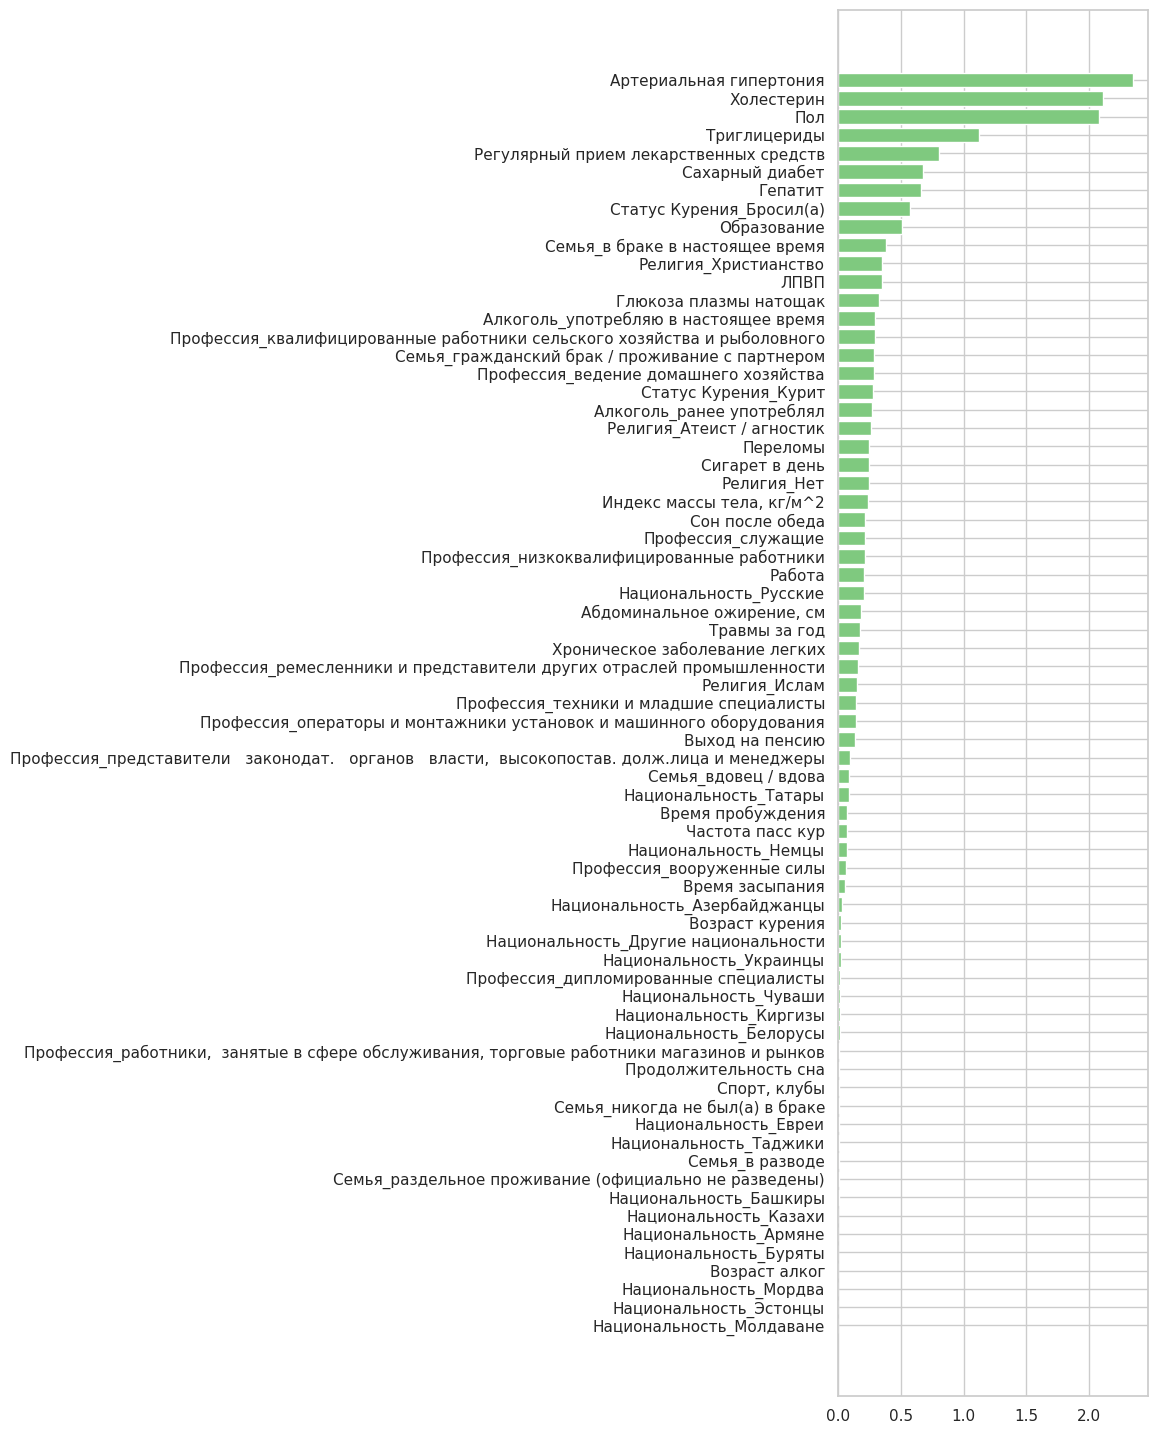

In [ ]:
plot_imp(ssz, np.abs(importance_logreg))

Важность признаков, полученная с помощью Деревьев решений

Возраст алког                            0.0000
Работа                                   0.0000
Переломы                                 0.0000
Время пробуждения                        0.0000
ЛПВП                                     0.0000
Выход на пенсию                          0.0000
Гепатит                                  0.0000
Триглицериды                             0.0000
Спорт, клубы                             0.0000
Частота пасс кур                         0.0000
Сахарный диабет                          0.0000
Пол                                      0.0000
Травмы за год                            0.0000
Сон после обеда                          0.0000
Глюкоза плазмы натощак                   0.0000
Регулярный прием лекарственных средств   0.0000
Семья_вдовец / вдова                     0.0000
Семья_гражданский брак / проживание с партнером 0.0000
Семья_в браке в настоящее время          0.0000
Время засыпания                          0.0000
Образование                      

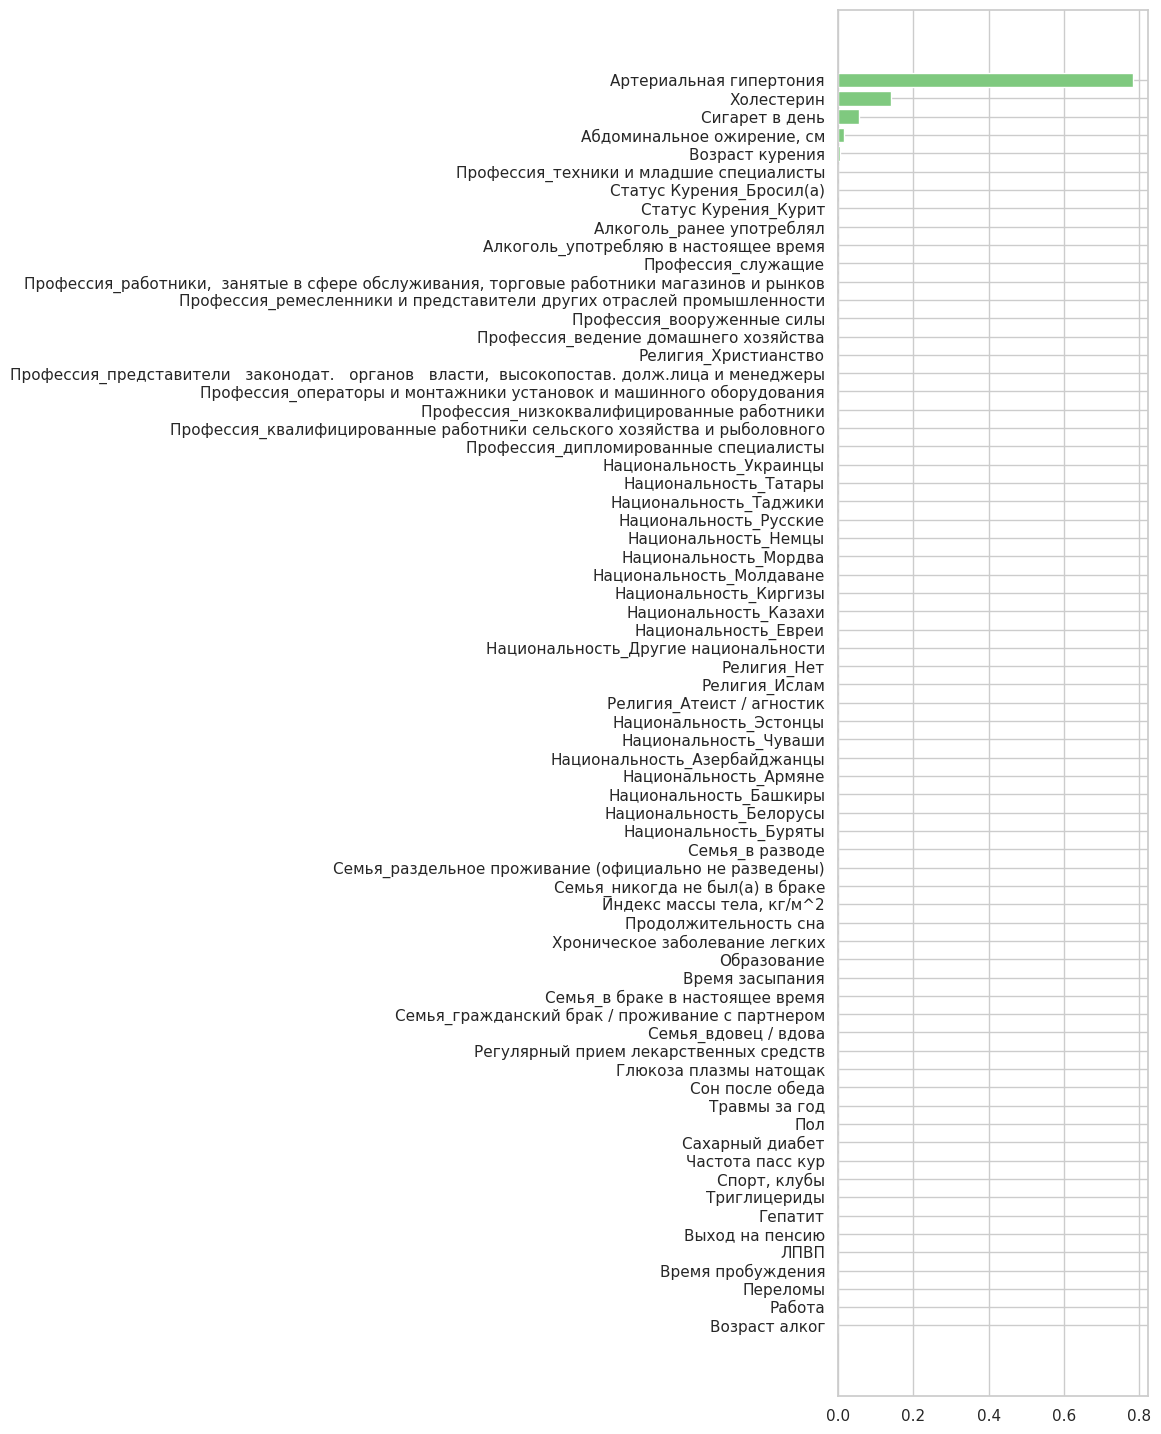

In [ ]:
plot_imp(ssz, importance_dt)



---



# Выводы

Все модели показали, что признаки 'Артериальная гипертония' и 'Холестерин' влияют на наличие ССЗ у пациента.

**Лучшая модель из рассмотренных** – логистическая регрессия.

Оценки точности этой модели:
* Accuracy = 0.9895
* Balanced_accuracy = 0.9904
* Precision = 1.0000
* Recall = 0.9808
* F1_score = 0.9903
* ROC AUC = 0.9956
* PR AUC = 0.9913
* Specificity = 1.0000

# Конец